# Análisis exploratorio del consumo de los usuarios de Electrohuila (2020–2026)

| | |
|---|---|
| **Versión** | 2.3 · 2026-11-08 |
| **Fuente** | `data/input/consumos.xlsx`, hoja *Exportar Hoja de Trabajo* (consulta SQL en la hoja *SQL*) |
| **Alcance** | Registros mensuales de enero 2020 a octubre 2026. El consumo se analiza hasta septiembre 2026, el último mes completo (sección 3.3) |
| **Unidad de análisis** | **152 usuarios**: cada cuenta toma su último nombre (titular actual) y se unen las variantes de escritura de una misma empresa (sección 4) |
| **Salidas** | `data/output/reportes/analisis_exploratorio/figuras/` (figuras numeradas) y `data/output/reportes/analisis_exploratorio/tablas/` (libros de Excel con formato) |

**Control de versiones**

| Versión | Cambios |
|---|---|
| 1.0 | Limpieza de nombres, cuentas con varios nombres, titular actual por cuenta, unión de variantes (152 usuarios), cuentas por año y serie interactiva |
| 2.0–2.1 | Calidad, cobertura, ciclos, evolución, consumo, distribución, concentración, comportamiento, exportación y conclusiones |
| 2.2 | Código compactado y documentado. La sección 4 sigue el método del autor (152 usuarios) y todas las interpretaciones se actualizaron con esas cifras |
| 2.3 | Nueva sección 6.7: perfiles estacionales por usuario-año (normalización por el máximo, silueta y k-means) |

## Contenido
1. Introducción
2. Metodología y revisión de literatura
3. Datos: estructura, calidad y cobertura
4. Homologación de nombres y consolidación de usuarios
5. Evolución de usuarios y cuentas
6. Consumo agregado: tendencia, estacionalidad y composición
7. Distribución del consumo
8. Concentración y principales usuarios
9. Comportamiento por usuario: cambios, estabilidad y atípicos
10. Exportación de tablas y verificación de totales
11. Conclusiones y próximos pasos
12. Referencias

**Cómo usar este cuaderno.** Es el único archivo del análisis: lee el Excel de `data/input/` y escribe todo en `data/output/`. Ejecute *Restart* y *Run All*. Cada figura y tabla va seguida de su interpretación: qué muestra y hallazgos.

## 1. Introducción

Este cuaderno describe la base de *usuarios especiales* de la Electrificadora del Huila (Electrohuila): cuántos son, cuántas cuentas tienen, cómo ha evolucionado su número, cuánta energía consumen, qué tan concentrado está ese consumo y qué problemas de calidad tienen los datos. Responde a cinco preguntas de gestión:

1. ¿Cuántos usuarios distintos hay realmente detrás de las cuentas registradas?
2. ¿Cuántos usuarios se observan hoy y cómo se compara con la historia?
3. ¿El consumo total cambia porque los usuarios consumen distinto o porque cambia la composición de la base?
4. ¿Qué tan concentrado está el consumo en pocos usuarios?
5. ¿Qué datos atípicos o vacíos deben revisarse antes de usar estas series para decisiones?

## 2. Metodología y revisión de literatura

**Análisis exploratorio antes de modelar.** La analítica de datos de medición de energía suele organizarse en tres etapas: preparación y control de calidad de los datos, descripción de patrones (tendencia, estacionalidad, perfiles) y, solo después, pronóstico o gestión de la demanda (Wang et al., 2019). Ese orden se adopta aquí: primero se valida qué representa cada registro, luego se consolida la identidad de los usuarios y finalmente se describen los patrones.

**Series de tiempo.** Las series se tratan como mensuales. La tendencia se resume con un promedio móvil de 12 meses y la estacionalidad con índices mensuales (consumo del mes frente al promedio de su año), un método descriptivo adecuado para una serie corta de 81 meses completos (Hyndman & Athanasopoulos, 2021, cap. 3). Los pronósticos de carga requieren distinguir entre dato ausente y consumo cero y validar la calidad de la historia antes de estimar (Hong & Fan, 2016); por eso aquí no se imputan ceros en meses sin registro.

**Atípicos.** Las distribuciones de consumo son muy asimétricas; la media y la desviación estándar se dejan arrastrar por los valores extremos. Se usa una puntuación robusta basada en la mediana y la desviación absoluta mediana (MAD), con umbral 3, que Leys et al. (2013) describen como muy conservador.

**Concentración.** Se usan la participación de los principales usuarios, la curva de Lorenz, el índice de Gini y el índice de Herfindahl-Hirschman (HHI), que suma los cuadrados de las participaciones porcentuales (Rhoades, 1993).

**Composición de la base.** El cambio del consumo total se separa entre lo que aportan el Municipio de Neiva, los grandes usuarios y el resto, y entre las cohortes según el año de primera aparición. También se compara cada usuario con su propio consumo del año anterior. Esto separa los cambios de consumo de los cambios en la composición.

**Reglas transversales del análisis**
- Un mes sin registro es *dato no observado*, nunca consumo cero. Un registro con `TOTAL_ACTIVA = 0` es *cero registrado*.
- No se elimina ni se imputa ningún registro; los problemas se marcan con banderas y se excluyen del cálculo solo cuando se justifica (por ejemplo, octubre de 2026 incompleto).
- Sin datos contractuales no se habla de altas, bajas ni deserción: se usan *primera aparición*, *reaparece* y *deja de observarse*.
- Los años parciales se comparan contra el mismo tramo de meses del año anterior.
- En figuras y tablas de resultados, los titulares que parecen personas naturales se muestran como “Persona natural Uxxx”.

In [1]:
# =============================================================================
# 0. CONFIGURACIÓN: librerías, rutas, parámetros, estilo gráfico y funciones de apoyo
# -----------------------------------------------------------------------------
# Todo lo que se lee está en data/input/ y todo lo que se produce va a data/output/.
# Cada ejecución completa (Restart + Run All) regenera figuras y tablas.
# =============================================================================
import re
from difflib import SequenceMatcher
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates

VERSION = '2.3'

# --- Rutas ---
RAIZ = Path.cwd().parent if Path.cwd().name == 'homework' else Path.cwd()   # funciona desde homework/ o desde la raíz
DIR_INPUT, DIR_OUTPUT = RAIZ / 'data' / 'input', RAIZ / 'data' / 'output'
DIR_FIG = DIR_OUTPUT / 'reportes' / 'analisis_exploratorio' / 'figuras'
DIR_TAB = DIR_OUTPUT / 'reportes' / 'analisis_exploratorio' / 'tablas'
RUTA_EXCEL = DIR_INPUT / 'consumos.xlsx'
for d in (DIR_FIG, DIR_TAB):
    d.mkdir(parents=True, exist_ok=True)
for viejo in [*DIR_FIG.glob('*.png'), *DIR_FIG.glob('*.html')]:   # se regeneran en cada ejecución
    viejo.unlink()
assert RUTA_EXCEL.exists(), f'No se encuentra {RUTA_EXCEL}: copie el Excel en la carpeta data/input/'

# --- Parámetros del análisis ---
UNIDAD = 'kWh'            # unidad de TOTAL_ACTIVA, inferida en la sección 3.2 (el archivo no la declara)
UMBRAL_Z_ROBUSTO = 3.0    # atípicos: |z robusto| > 3 (Leys et al., 2013)

# --- Visualización de tablas en el cuaderno ---
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# --- Paleta: cada color tiene un único significado en todo el cuaderno ---
AZUL, NARANJA, AQUA, AMARILLO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
MAGENTA, VERDE, VIOLETA, ROJO = '#e87ba4', '#008300', '#6250d6', '#e34948'
TINTA, TINTA_2, TINTA_3 = '#1d1d1b', '#52514e', '#8a8984'
REJILLA, FONDO, GRIS_SUAVE = '#e7e6e2', '#ffffff', '#c9c8c3'
SECUENCIAL = matplotlib.colors.LinearSegmentedColormap.from_list(
    'azules', ['#eef5fd', '#b7d3f6', '#6da7ec', '#2a78d6', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'font.family': 'DejaVu Sans', 'font.size': 10.5, 'text.color': TINTA,
    'axes.edgecolor': REJILLA, 'axes.labelcolor': TINTA_2, 'axes.labelsize': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'xtick.major.size': 0, 'ytick.major.size': 0,
    'legend.frameon': False, 'legend.fontsize': 9.5, 'lines.linewidth': 2,
    'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight',
})
FUENTE = f'Fuente: Electrohuila, tabla estadistica_usuario (tipo_usuario = NR). Cálculos propios. Cuaderno v{VERSION}.'
MESES_ES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
N_FIGURA = 0              # contador: las figuras se numeran en el orden en que se crean


def nueva_figura(titulo, subtitulo='', ancho=12, alto=5, filas=1, columnas=1, **kw):
    """Crea una figura numerada con título y subtítulo alineados a la izquierda."""
    global N_FIGURA
    N_FIGURA += 1
    fig, axes = plt.subplots(filas, columnas, figsize=(ancho, alto), **kw)
    fig.subplots_adjust(top=1 - (1.0 if subtitulo else 0.7) / alto, left=0.07, right=0.97)
    fig.text(0.01, 1 - 0.12 / alto, f'Figura {N_FIGURA}. {titulo}', fontsize=14.5, fontweight='bold',
             color=TINTA, ha='left', va='top')
    if subtitulo:
        fig.text(0.01, 1 - 0.47 / alto, subtitulo, fontsize=10.5, color=TINTA_2, ha='left', va='top')
    return fig, axes


def guardar(fig, nombre, nota=''):
    """Agrega la fuente al pie, guarda la figura como data/output/reportes/analisis_exploratorio/figuras/NN_nombre.png y la muestra."""
    fig.text(0.01, 0.0, FUENTE + (f'  {nota}' if nota else ''), fontsize=8.5, color=TINTA_3, ha='left', va='top')
    fig.savefig(DIR_FIG / f'{N_FIGURA:02d}_{nombre}.png')
    plt.show()


def miles(x, pos=None):
    """Formato con separador de miles en punto: 12345 -> '12.345'."""
    return f'{x:,.0f}'.replace(',', '.')


def fmt_es(x, dec=1):
    """Formato numérico en español: 1234.5 -> '1.234,5'."""
    return f'{x:,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def eje_miles(ax, eje='y'):
    (ax.yaxis if eje == 'y' else ax.xaxis).set_major_formatter(mtick.FuncFormatter(miles))


def eje_fechas(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


print(f'Cuaderno v{VERSION} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}')
print('Entrada:', RUTA_EXCEL.resolve())
print('Salidas:', DIR_OUTPUT.resolve())

Cuaderno v2.3 | pandas 2.3.3 | numpy 2.2.6 | matplotlib 3.10.9
Entrada: /sessions/rcw-01jq2kxr5esewvxaqb5qwqrm/mnt/Consumo_Usuarios/input/Consumo_Usarios.xlsx
Salidas: /sessions/rcw-01jq2kxr5esewvxaqb5qwqrm/mnt/Consumo_Usuarios/output


In [2]:
# ---------------------------------------------------------------
# Exportación a Excel con formato profesional
# ---------------------------------------------------------------
from datetime import datetime
from openpyxl.styles import Font, Alignment
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.table import Table, TableStyleInfo

def _formato_columna(nombre, serie):
    """Formato numérico de Excel según el nombre y el tipo de la columna."""
    n = nombre.lower()
    if pd.api.types.is_datetime64_any_dtype(serie):
        return 'yyyy-mm'
    if not pd.api.types.is_numeric_dtype(serie):
        return None
    if n in ('año', 'mes', 'ciclo', 'cuenta', 'posición') or n.startswith(('año ', 'cuenta ')):
        return '0'
    if '%' in nombre or 'índice' in n:
        return '0.0'
    if 'similitud' in n or 'por usuario' in n or 'z robusto' in n or 'coef' in n or 'gini' in n or n == 'valor':
        return '0.00'
    if 'gwh' in n or 'mwh' in n:
        return '#,##0.00'
    return '#,##0'

def exportar_excel(ruta, hojas, titulo_libro=None):
    """Escribe un libro de Excel con una tabla por hoja.

    hojas: lista de diccionarios con las llaves
        hoja (nombre de la pestaña, máx. 31 caracteres), tabla (DataFrame sin índice),
        titulo y descripcion (se escriben encima de la tabla).
    Si se indica titulo_libro, la primera hoja es un índice con vínculos a cada hoja.
    Cada tabla queda como Tabla de Excel (filtros y filas alternas), con encabezado fijo,
    anchos ajustados y formatos de número, fecha y porcentaje.
    """
    if titulo_libro:
        indice = pd.DataFrame({'Hoja': [h['hoja'] for h in hojas], 'Contenido': [h['titulo'] for h in hojas],
                               'Descripción': [h['descripcion'] for h in hojas], 'Filas': [len(h['tabla']) for h in hojas]})
        hojas = [{'hoja': 'Índice', 'tabla': indice, 'titulo': titulo_libro,
                  'descripcion': f'Generado el {datetime.now():%Y-%m-%d %H:%M} desde {RUTA_EXCEL.as_posix()}. '
                                 'Haga clic en el nombre de una hoja para ir a ella.'}] + hojas
    FILA_ENC = 4                                     # fila del encabezado de la tabla
    ruta = Path(ruta)
    try:                                             # si el archivo está abierto en Excel, Windows lo bloquea
        with open(ruta, 'a'):
            pass
    except PermissionError:
        ruta = ruta.with_name(f'{ruta.stem}_{datetime.now():%Y%m%d_%H%M%S}{ruta.suffix}')
        print(f'AVISO: el archivo original está abierto en Excel; se guardó como {ruta.name}. Ciérrelo y vuelva a ejecutar.')
    with pd.ExcelWriter(ruta, engine='openpyxl') as xw:
        for k, h in enumerate(hojas):
            t = h['tabla'].reset_index(drop=True)
            formatos = {c: _formato_columna(c, t[c]) for c in t.columns}
            t_out = t.astype(object).where(t.notna(), None)      # NA -> celda vacía
            t_out.to_excel(xw, sheet_name=h['hoja'], index=False, startrow=FILA_ENC - 1)
            ws = xw.sheets[h['hoja']]
            ws.sheet_view.showGridLines = False
            ws['A1'] = h['titulo']; ws['A1'].font = Font(bold=True, size=14, color='1D1D1B')
            ws['A2'] = h['descripcion']; ws['A2'].font = Font(italic=True, size=10, color='52514E')
            ws['A2'].alignment = Alignment(wrap_text=False)
            n_filas, n_cols = len(t), len(t.columns)
            ultima = get_column_letter(n_cols)
            if n_filas:
                tabla = Table(displayName=f'T{k:02d}_' + ''.join(ch for ch in h['hoja'] if ch.isalnum())[:20],
                              ref=f'A{FILA_ENC}:{ultima}{FILA_ENC + n_filas}')
                tabla.tableStyleInfo = TableStyleInfo(name='TableStyleMedium2', showRowStripes=True)
                ws.add_table(tabla)
            for j, c in enumerate(t.columns, start=1):
                letra = get_column_letter(j)
                celda_enc = ws.cell(row=FILA_ENC, column=j)
                celda_enc.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
                if formatos[c]:
                    for fila in range(FILA_ENC + 1, FILA_ENC + n_filas + 1):
                        ws.cell(row=fila, column=j).number_format = formatos[c]
                largo_datos = t[c].astype(str).str.len().max() if n_filas else 0
                if formatos[c] and formatos[c].startswith('#,##0'):
                    largo_datos = int(largo_datos * 1.3)          # separadores de miles
                ancho = min(max(len(str(c)) * 0.9, largo_datos, 8) + 3, 60)
                ws.column_dimensions[letra].width = ancho
                if ancho >= 60:                                       # texto largo: ajustar en varias líneas
                    for fila in range(FILA_ENC + 1, FILA_ENC + n_filas + 1):
                        ws.cell(row=fila, column=j).alignment = Alignment(wrap_text=True, vertical='top')
            ws.row_dimensions[FILA_ENC].height = 32
            ws.freeze_panes = ws.cell(row=FILA_ENC + 1, column=1)
            if titulo_libro and k == 0:                           # vínculos del índice
                for fila in range(FILA_ENC + 1, FILA_ENC + n_filas + 1):
                    celda = ws.cell(row=fila, column=1)
                    celda.hyperlink = f"#'{celda.value}'!A1"
                    celda.font = Font(color='2A78D6', underline='single')
    return ruta

## 3. Datos: estructura, calidad y cobertura

### 3.1 Archivos de entrada

In [3]:
# Corrección: la ruta "input\Consumo_Usarios.xlsx" con barra invertida genera un aviso en Python;
# se usa RUTA_EXCEL, definida en la celda de configuración.
df = pd.read_excel(RUTA_EXCEL, 'Exportar Hoja de Trabajo')
df_a = df.copy()
df_a

,ANO,MES,CICLO,CUENTA,NOMBRE,DIRECCION,TOTAL_ACTIVA
0,2020,1,1,941135667,SUR GAS S.A.E.S.P,KM3 VIA FORTALECILLAS VDA LA M,89181
1,2020,1,1,918789984,CARCAFE LTDA,CRA 11 A #5-167 TRILLADORA CAR,92083
2,2020,1,1,538262790,MOVILGAS LTDA,CALLE 15 CRA 37 E- CRA37F ED,48954
3,2020,1,1,219019728,CARLOS CABRERA VILLAMIL,HACIENDA LA COLORADA,50094
4,2020,1,1,358276403,ALMACENES GRALES DE DEPOSITO D,KM 2 VIA AGRADO - ALMACAFE,18783
...,...,...,...,...,...,...,...
46744,2026,9,1,547144637,BAKER DE COLOMBIA,COND. IND. TERPEL LOTE 1,60725
46745,2026,9,1,218902504,LEONEL VARGAS CAMACHO,K 7P 9 01 KM 2 VIA PALERMO - M,4140
46746,2026,9,1,446662948,ALFAREROS DEL MACIZO CBIANO,VR CRIOLLO,12518
46747,2026,9,1,578547226,CARLOS EFREN IBARRA MARTINEZ,LADRILLERA BUENOS AIRES - KM 1,57136


In [4]:
df_a.shape

(46749, 7)

In [5]:
df_a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46749 entries, 0 to 46748
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ANO           46749 non-null  int64 
 1   MES           46749 non-null  int64 
 2   CICLO         46749 non-null  int64 
 3   CUENTA        46749 non-null  int64 
 4   NOMBRE        46749 non-null  object
 5   DIRECCION     46749 non-null  object
 6   TOTAL_ACTIVA  46749 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 2.5+ MB


In [6]:
DESCRIPCION = {
    'ANO': 'Año de facturación', 'MES': 'Mes de facturación (1–12)', 'CICLO': 'Ciclo de facturación',
    'CUENTA': 'Número de cuenta (identificador del punto de suministro)', 'NOMBRE': 'Nombre del titular (máx. 30 caracteres)',
    'DIRECCION': 'Dirección del suministro', 'TOTAL_ACTIVA': f'Energía activa facturada en el mes ({UNIDAD}, inferida)'}
estructura = pd.DataFrame({
    'Tipo': df_a.dtypes.astype(str),
    'Nulos': df_a.isna().sum(),
    'Valores distintos': df_a.nunique(),
    'Mínimo': [df_a[c].min() if df_a[c].dtype != object else '' for c in df_a],
    'Máximo': [df_a[c].max() if df_a[c].dtype != object else '' for c in df_a],
    'Largo máx. texto': [df_a[c].astype(str).str.len().max() if df_a[c].dtype == object else '' for c in df_a],
    'Descripción': [DESCRIPCION[c] for c in df_a],
})
estructura

,Tipo,Nulos,Valores distintos,Mínimo,Máximo,Largo máx. texto,Descripción
ANO,int64,0,7,2020,2026,,Año de facturación
MES,int64,0,12,1,12,,Mes de facturación (1–12)
CICLO,int64,0,3,1,202,,Ciclo de facturación
CUENTA,int64,0,701,149738730,967345088,,Número de cuenta (identificador del punto de s...
NOMBRE,object,0,207,,,30,Nombre del titular (máx. 30 caracteres)
DIRECCION,object,0,760,,,30,Dirección del suministro
TOTAL_ACTIVA,int64,0,14900,0,1358836,,"Energía activa facturada en el mes (kWh, infer..."


**Interpretación — estructura de los datos**

- **Qué muestra:** el archivo tiene 46.749 registros y 7 columnas; cada fila es el consumo de una cuenta en un mes (año, mes, ciclo, cuenta, nombre, dirección y energía activa).
- **Hallazgos:** no hay valores nulos. Hay 701 cuentas, 207 nombres y 760 direcciones distintas. Que haya más direcciones que cuentas indica que la dirección de una misma cuenta cambia de escritura en el tiempo. `NOMBRE` y `DIRECCION` llegan a 30 caracteres exactos: el sistema los trunca (por ejemplo, *HOSPITAL UNIVERSITARIO DE NEIV*). `CICLO` solo toma 3 valores (1, 19 y 202; ver 3.5).

### 3.2 Unidad de `TOTAL_ACTIVA`

In [7]:
desc = df_a['TOTAL_ACTIVA'].describe(percentiles=[.1, .25, .5, .75, .9, .99])
unidad = pd.DataFrame({'Valor mensual por cuenta': desc}).T
unidad

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
Valor mensual por cuenta,"46,749.00","20,935.37","72,874.17",0.00,66.00,194.00,592.00,"5,277.00","61,314.00","285,023.40","1,358,836.00"


### 3.3 Calidad: duplicados, ceros, negativos y cobertura mensual

In [8]:
df_a['FECHA'] = pd.to_datetime(dict(year=df_a['ANO'], month=df_a['MES'], day=1))
dup_total = df_a.duplicated().sum()
dup_clave = df_a.duplicated(['ANO', 'MES', 'CUENTA']).sum()
cuentas_mes = df_a.groupby('FECHA')['CUENTA'].nunique()
mediana_cuentas = cuentas_mes.median()
meses_incompletos = cuentas_mes[cuentas_mes < 0.5 * mediana_cuentas]
calidad = pd.DataFrame({
    'Indicador': ['Registros', 'Filas duplicadas completas', 'Duplicados de cuenta-mes (ANO, MES, CUENTA)',
                  'Valores nulos (todas las columnas)', 'Registros con consumo cero', 'Registros con consumo negativo',
                  'Meses distintos', 'Ciclos de facturación distintos', 'Meses con cobertura < 50 % de la mediana'],
    'Valor': [len(df_a), dup_total, dup_clave, int(df_a.isna().sum().sum()), int((df_a['TOTAL_ACTIVA'] == 0).sum()),
              int((df_a['TOTAL_ACTIVA'] < 0).sum()), df_a['FECHA'].nunique(), df_a['CICLO'].nunique(),
              ', '.join(meses_incompletos.index.strftime('%Y-%m')) or 'ninguno'],
})
calidad['% de registros'] = [''] + [f'{v / len(df_a):.2%}' if isinstance(v, (int, np.integer)) and i in (1, 2, 3, 4, 5) else ''
                                  for i, v in enumerate(calidad['Valor'][1:], start=1)]
calidad

,Indicador,Valor,% de registros
0,Registros,46749,
1,Filas duplicadas completas,0,0.00%
2,"Duplicados de cuenta-mes (ANO, MES, CUENTA)",0,0.00%
3,Valores nulos (todas las columnas),0,0.00%
4,Registros con consumo cero,2701,5.78%
5,Registros con consumo negativo,0,0.00%
6,Meses distintos,82,
7,Ciclos de facturación distintos,3,
8,Meses con cobertura < 50 % de la mediana,2026-10,


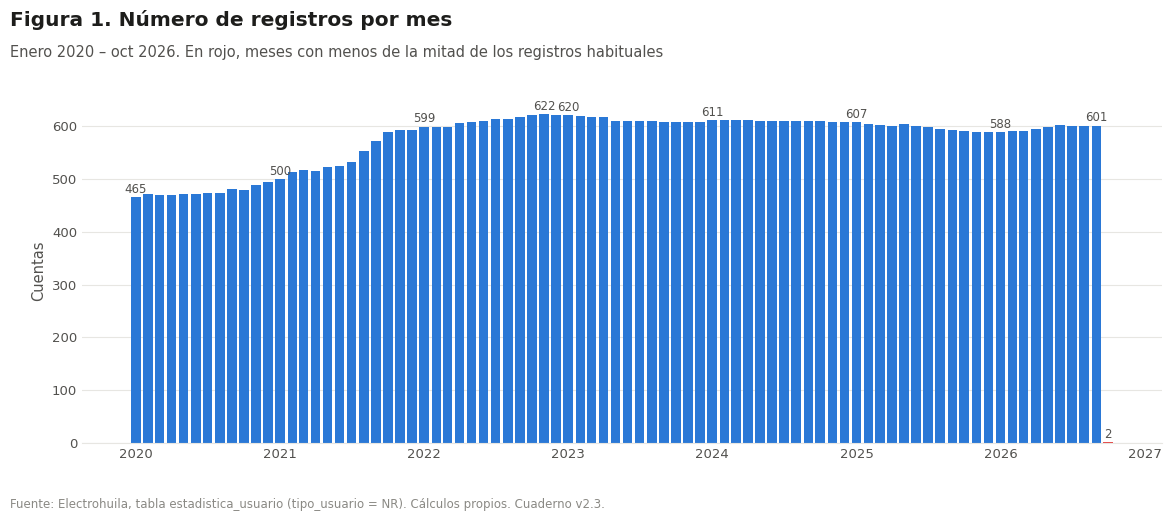

In [9]:
ULTIMO_MES = cuentas_mes[cuentas_mes >= 0.5 * mediana_cuentas].index.max()     # último mes completo
fig, ax = nueva_figura('Número de registros por mes',
                       f'Enero 2020 – {MESES_ES[cuentas_mes.index.max().month - 1].lower()} {cuentas_mes.index.max().year}. En rojo, meses con menos de la mitad de los registros habituales')
colores = [ROJO if f in meses_incompletos.index else AZUL for f in cuentas_mes.index]
ax.bar(cuentas_mes.index, cuentas_mes.values, width=24, color=colores)
for f, v in cuentas_mes.items():
    if f.month == 1 or f == cuentas_mes.idxmax() or f == ULTIMO_MES or f in meses_incompletos.index:
        ax.annotate(f'{v}', (f, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8.5, color=TINTA_2)
ax.set_ylabel('Cuentas'); eje_fechas(ax)
guardar(fig, 'cobertura_mensual')

**Interpretación — calidad y cobertura**

- **Qué muestra:** la tabla resume los controles de calidad y la figura el número de cuentas con registro cada mes.
- **Hallazgos:**
  - No hay filas duplicadas, ni repetición de cuenta-mes, ni nulos, ni consumos negativos.
  - Las cuentas pasan de 465 (enero 2020) a un máximo de 622 (noviembre 2022) y se ubican en 601 en septiembre de 2026. El crecimiento ocurre sobre todo entre 2020 y 2022.
  - **Octubre de 2026 tiene solo 2 cuentas**: el mes está en proceso de cargue y se excluye de todos los cálculos de consumo.

### 3.4 Cobertura de cada cuenta en el tiempo

Para cada una de las 701 cuentas y cada mes completo se clasifica el estado: **con consumo**, **cero registrado** o **sin registro**. Un mes sin registro solo se cuenta como vacío si está entre el primer y el último registro de la cuenta: antes de aparecer o después de su último registro la cuenta no existía o ya no estaba. La primera tabla resume por año y la segunda lista las cuentas con más meses vacíos. Ambas se exportan a `data/output/reportes/analisis_exploratorio/tablas/registro_mensual_por_cuenta.xlsx`.

In [10]:
# Fecha mensual (se crea si aún no existe)
if 'FECHA' not in df_a.columns:
    df_a['FECHA'] = pd.to_datetime(dict(year=df_a['ANO'], month=df_a['MES'], day=1))

presencia = df_a.pivot_table(index='CUENTA', columns='FECHA', values='TOTAL_ACTIVA', aggfunc='sum')

# Se excluyen los meses incompletos (menos de la mitad de las cuentas habituales, p. ej. octubre de 2026)
cuentas_por_mes = presencia.notna().sum()
presencia = presencia.loc[:, cuentas_por_mes >= 0.5 * cuentas_por_mes.median()]

# Estado de cada cuenta en cada mes. "Sin registro" solo cuenta entre el primer y el último mes de la cuenta;
# antes de aparecer o después de su último registro la cuenta no existía o ya no estaba (no es un vacío).
con_registro = presencia.notna()
dentro = con_registro.cummax(axis=1) & con_registro.iloc[:, ::-1].cummax(axis=1).iloc[:, ::-1]
estado = pd.DataFrame(
    np.select([presencia.eq(0), con_registro, dentro],
              ['Cero registrado', 'Con consumo', 'Sin registro (vacío)'], 'Fuera de su periodo'),
    index=presencia.index, columns=presencia.columns)

# Tabla 1: meses-cuenta por año y estado
largo = estado.stack().rename('ESTADO').reset_index()
largo['Año'] = largo['FECHA'].dt.year
resumen_registro = (pd.crosstab(largo['Año'], largo['ESTADO'])
                    .reindex(columns=['Con consumo', 'Cero registrado', 'Sin registro (vacío)'], fill_value=0))
resumen_registro.columns.name = None
resumen_registro.insert(0, 'Cuentas activas', con_registro.T.groupby(con_registro.columns.year).any().sum(axis=1))
resumen_registro.insert(1, 'Meses', con_registro.columns.year.value_counts().sort_index())
resumen_registro.loc['Total'] = resumen_registro.sum()
resumen_registro.loc['Total', 'Cuentas activas'] = len(presencia)
resumen_registro.loc['Total', 'Meses'] = presencia.shape[1]
total_mc = resumen_registro[['Con consumo', 'Cero registrado', 'Sin registro (vacío)']].sum(axis=1)
resumen_registro['% con consumo'] = (resumen_registro['Con consumo'] / total_mc * 100).round(1)
resumen_registro['% en cero'] = (resumen_registro['Cero registrado'] / total_mc * 100).round(1)
resumen_registro['% sin registro'] = (resumen_registro['Sin registro (vacío)'] / total_mc * 100).round(1)

# Tabla 2: detalle por cuenta (ordenada por primer mes con registro)
registro_por_cuenta = pd.DataFrame({
    'PRIMER_MES': con_registro.idxmax(axis=1).dt.strftime('%Y-%m'),
    'ULTIMO_MES': con_registro.iloc[:, ::-1].idxmax(axis=1).dt.strftime('%Y-%m'),
    'MESES_CON_CONSUMO': (estado == 'Con consumo').sum(axis=1),
    'MESES_EN_CERO': (estado == 'Cero registrado').sum(axis=1),
    'MESES_SIN_REGISTRO': (estado == 'Sin registro (vacío)').sum(axis=1),
}).sort_values(['PRIMER_MES', 'MESES_SIN_REGISTRO'], ascending=[True, False])

estado_resumen = resumen_registro.loc['Total', ['Con consumo', 'Cero registrado', 'Sin registro (vacío)']].astype(int)

with pd.ExcelWriter(DIR_TAB / 'registro_mensual_por_cuenta.xlsx') as xw:
    resumen_registro.to_excel(xw, sheet_name='Resumen por año')
    registro_por_cuenta.to_excel(xw, sheet_name='Detalle por cuenta')

print(f'Cuentas con vacíos dentro de su periodo: {(registro_por_cuenta["MESES_SIN_REGISTRO"] > 0).sum()} | '
      f'cuentas con algún mes en cero: {(registro_por_cuenta["MESES_EN_CERO"] > 0).sum()}')
display(resumen_registro)
display(registro_por_cuenta.sort_values('MESES_SIN_REGISTRO', ascending=False).head(20))

Cuentas con vacíos dentro de su periodo: 20 | cuentas con algún mes en cero: 309


,Cuentas activas,Meses,Con consumo,Cero registrado,Sin registro (vacío),% con consumo,% en cero,% sin registro
Año,,,,,,,,
2020,509,12,5513,195,4,96.50,3.40,0.10
2021,604,12,6256,265,10,95.80,4.10,0.20
2022,631,12,6955,370,1,94.90,5.10,0.00
2023,621,12,6880,463,0,93.70,6.30,0.00
2024,617,12,6773,541,11,92.50,7.40,0.20
2025,617,12,6678,492,45,92.60,6.80,0.60
2026,612,9,4992,374,47,92.20,6.90,0.90
Total,701,81,44047,2700,118,94.00,5.80,0.30


,PRIMER_MES,ULTIMO_MES,MESES_CON_CONSUMO,MESES_EN_CERO,MESES_SIN_REGISTRO
CUENTA,,,,,
817480762,2024-12,2026-09,9,0,13
817481549,2024-12,2026-09,9,0,13
918790710,2020-01,2026-09,63,7,11
339812098,2021-12,2026-09,46,1,11
956715713,2020-01,2026-09,72,0,9
929220298,2020-01,2026-09,69,4,8
906661468,2020-01,2026-09,74,0,7
282217924,2021-10,2026-09,54,0,6
815627513,2025-05,2026-09,10,2,5


In [11]:
pres_periodo = presencia.loc[:, presencia.columns <= ULTIMO_MES].notna()      # sin el mes incompleto
meses_por_cuenta = pres_periodo.sum(axis=1)

def tiene_interrupcion(fila):
    """True si la cuenta deja de tener registro algún mes entre su primer y su último registro."""
    idx = np.flatnonzero(fila.values)
    return len(idx) > 0 and (idx[-1] - idx[0] + 1) > len(idx)

huecos = pres_periodo.apply(tiene_interrupcion, axis=1)
cobertura = pd.DataFrame({
    'Indicador': ['Cuentas', f'Cuentas con registro en todos los meses hasta {ULTIMO_MES:%Y-%m} ({pres_periodo.shape[1]})',
                  'Cuentas con menos de 12 meses de registro',
                  'Cuentas con interrupciones (vuelven a aparecer tras un vacío)', 'Mediana de meses con registro por cuenta'],
    'Valor': [len(presencia), int((meses_por_cuenta == pres_periodo.shape[1]).sum()), int((meses_por_cuenta < 12).sum()),
              int(huecos.sum()), int(meses_por_cuenta.median())]})
cobertura

,Indicador,Valor
0,Cuentas,701
1,Cuentas con registro en todos los meses hasta ...,402
2,Cuentas con menos de 12 meses de registro,53
3,Cuentas con interrupciones (vuelven a aparecer...,20
4,Mediana de meses con registro por cuenta,81


**Interpretación — registro mensual por cuenta**

- **Qué muestran:** las tablas de estado mensual por año y por cuenta, y el resumen de cobertura.
- **Hallazgos:**
  - El 94 % de los meses-cuenta tiene consumo, el 5,8 % (2.700) está en cero y solo el 0,3 % (118) son vacíos dentro del periodo de la cuenta.
  - La mediana es de 81 meses con registro por cuenta y 402 cuentas están presentes en todos los meses hasta septiembre de 2026.
  - Solo 20 cuentas tienen vacíos y luego vuelven a aparecer; las de mayor vacío son 2 cuentas que aparecen en diciembre de 2024 con 13 meses sin registro.
  - 309 cuentas tienen al menos un mes en cero, y la proporción de ceros sube de 3,4 % en 2020 a ≈ 7 % desde 2024.


### 3.5 Ciclos de facturación

In [12]:
ciclos = (df_a.groupby('CICLO').agg(Registros=('CUENTA', 'size'), Cuentas=('CUENTA', 'nunique'),
                                     Meses=('FECHA', 'nunique'), Primer_mes=('FECHA', 'min'), Ultimo_mes=('FECHA', 'max'),
                                     Consumo_GWh=('TOTAL_ACTIVA', lambda s: s.sum() / 1e6))
          .rename(columns={'Primer_mes': 'Primer mes', 'Ultimo_mes': 'Último mes', 'Consumo_GWh': 'Consumo (GWh)'}))
ciclos['% del consumo'] = ciclos['Consumo (GWh)'] / ciclos['Consumo (GWh)'].sum() * 100
cuentas_varios_ciclos = int((df_a.groupby('CUENTA')['CICLO'].nunique() > 1).sum())
print(f'Cuentas que cambian de ciclo: {cuentas_varios_ciclos}')
ciclos

Cuentas que cambian de ciclo: 0


,Registros,Cuentas,Meses,Primer mes,Último mes,Consumo (GWh),% del consumo
CICLO,,,,,,,
1,12352,219,81,2020-01-01,2026-09-01,891.08,91.05
19,34393,480,81,2020-01-01,2026-09-01,86.44,8.83
202,4,2,3,2026-08-01,2026-10-01,1.19,0.12


**Interpretación — ciclos de facturación**

- **Qué muestra:** registros, cuentas y consumo por ciclo de facturación.
- **Hallazgos:**
  - El campo `CICLO` toma tres valores.
  - **Ciclo 1:** 219 cuentas y el 91 % del consumo; 218 de ellas no son del Municipio de Neiva.
  - **Ciclo 19:** 480 cuentas y el 8,8 % del consumo; 477 de ellas son del Municipio de Neiva.
  - **Ciclo 202:** aparece solo desde agosto de 2026, con 2 cuentas y 4 registros.
  - Ninguna cuenta cambia de ciclo.

## 4. Homologación de nombres y consolidación de usuarios

Una misma organización puede aparecer con varios nombres (cambio de razón social, abreviaturas, espacios dobles, texto truncado a 30 caracteres) y tener varias cuentas. El método tiene tres pasos:

1. **Último nombre por cuenta (4.1–4.3).** Cada cuenta toma el último nombre con que aparece, su titular actual, y todo su historial queda a nombre de ese titular.
2. **Unión de variantes (4.4).** Un diccionario revisado manualmente une los nombres de una misma empresa escritos de dos formas en cuentas distintas.
3. **Consolidación (4.6).** Se construye la tabla de usuarios, con un código seudónimo y protección de personas naturales.

Resultado: **701 cuentas → 152 usuarios**.

### 4.1–4.3 Último nombre de cada cuenta

In [13]:
# =============================================================================
# 4.1–4.3 Homologación: cada cuenta toma el ÚLTIMO nombre con que aparece (titular actual)
# -----------------------------------------------------------------------------
# 1) NOMBRE_LIMPIO: mayúsculas, sin espacios al inicio/fin ni espacios dobles.
# 2) reporte_final: cuentas con más de un nombre, sus nombres en orden cronológico y el último.
# 3) NOMBRE_UNICO: último nombre de la cuenta; si la cuenta tuvo un solo nombre, el NOMBRE original.
# =============================================================================
df_a['NOMBRE_LIMPIO'] = (df_a['NOMBRE'].astype(str).str.upper().str.strip()
                         .str.replace(r'\s+', ' ', regex=True))
df_a['PERIODO'] = df_a['ANO'] * 100 + df_a['MES']            # AAAAMM, para ordenar en el tiempo

reporte_final = (df_a.sort_values(['CUENTA', 'PERIODO'])
                 .groupby('CUENTA')
                 .agg(NOMBRES_ENCONTRADOS=('NOMBRE_LIMPIO', lambda s: ' | '.join(pd.unique(s))),
                      CANT_NOMBRES=('NOMBRE_LIMPIO', 'nunique'),
                      PRIMER_NOMBRE=('NOMBRE_LIMPIO', 'first'),
                      ULTIMO_NOMBRE=('NOMBRE_LIMPIO', 'last'))
                 .query('CANT_NOMBRES > 1')
                 .reset_index())

dic_nombres = dict(zip(reporte_final['CUENTA'], reporte_final['ULTIMO_NOMBRE']))   # CUENTA -> último nombre
df_a['NOMBRE_UNICO'] = df_a['CUENTA'].map(dic_nombres).fillna(df_a['NOMBRE'])
# Nota: NOMBRE_LIMPIO se conserva porque la sección 4.6 y el Excel de resultados lo usan.

print(f'Cuentas con más de un nombre: {len(reporte_final)} | nombres únicos: {df_a["NOMBRE_UNICO"].nunique()}')
reporte_final

Cuentas con más de un nombre: 71 | nombres únicos: 157


,CUENTA,NOMBRES_ENCONTRADOS,CANT_NOMBRES,PRIMER_NOMBRE,ULTIMO_NOMBRE
0,149738730,DIRECCION ADTIVA JUDICIAL NEIV | DIRECCION ADM...,2,DIRECCION ADTIVA JUDICIAL NEIV,DIRECCION ADMINISTRATIVA JUDIC
1,149808880,CALPES S.A | INVERSIONES 3 LIN S.A.S.,2,CALPES S.A,INVERSIONES 3 LIN S.A.S.
2,156143002,HOTEL CHICALA LTDA | HOTEL CHICALA SAS,2,HOTEL CHICALA LTDA,HOTEL CHICALA SAS
3,156203273,CLINICA MEDILASER S.A. | CLINICA MEDILASER S.A.S.,2,CLINICA MEDILASER S.A.,CLINICA MEDILASER S.A.S.
4,156223011,CLINICA MEDILASER S.A. | CLINICA MEDILASER S.A.S.,2,CLINICA MEDILASER S.A.,CLINICA MEDILASER S.A.S.
...,...,...,...,...,...
66,929049545,CONSTRUCTORA NEIVA LA NUEVA SA | CENTRO COMERC...,2,CONSTRUCTORA NEIVA LA NUEVA SA,CENTRO COMERCIAL UNICENTRO NEI
67,929531235,CONSTRUCTORA NEIVA LA NUEVA SA | CENTRO COMERC...,2,CONSTRUCTORA NEIVA LA NUEVA SA,CENTRO COMERCIAL UNICENTRO NEI
68,941135667,SUR GAS S.A.E.S.P | SURGAS S.A. E.S.P.,2,SUR GAS S.A.E.S.P,SURGAS S.A. E.S.P.
69,941516754,SKN CARIBECAFE LTDA | SKN CARIBECAFE S.A.S.,2,SKN CARIBECAFE LTDA,SKN CARIBECAFE S.A.S.


**Interpretación — cuentas con más de un nombre**

- **Qué muestra:** las 71 cuentas que aparecen con más de un nombre de titular, sus nombres en orden cronológico y el último, que es el que se asigna a la cuenta.
- **Hallazgos:**
  - 71 de 701 cuentas (10 %) cambiaron de nombre.
  - 29 son variantes de escritura o de forma societaria (*CLINICA MEDILASER S.A.* → *S.A.S.*).
  - 42 son posibles cambios de titular: *INTEGRADOR A.P.* → *MUNICIPIO DE NEIVA*, *IBM DE COLOMBIA* → *FIDUCIARIA DAVIVIENDA*, *CALPES S.A* → *INVERSIONES 3 LIN*, entre otros.
  - Tras este paso quedan 157 nombres; la lista se muestra abajo.


In [14]:
df_a["NOMBRE_UNICO"].sort_values().unique().tolist()

['AGROINDUSTRIAL LOS ALTARES S.A', 'AGROPECUARIAS BOMBONA S.A.', 'AGROVETERINARIA LA CAMPIÑA SAS', 'ALCANOS DE COLOMBIA S.A. E.S.P', 'ALFAREROS DEL MACIZO CBIANO', 'ALMACENES GRALES DE DEPOSITO D', 'AMIGOS AMG SAS', 'ANA CECILIA URIBE TRUJILLO', 'ARCA MINERALES S. A. S.', 'ARCILLAS ARVA DE COLOMBIA SAS', 'ARNAL CUELLAR  GOMEZ', 'ASOBELMONTE', 'ASOC.USU.DIST.ADE.TIE.PQA.ESC.', 'ASOCIACION DE USUARIOS DEL DIS', 'ASOLOSNARANJOS', 'ASOPORVENIR', 'ASOSANJOSE', 'ASOSANTANA', 'ASOSANTANA (ASOCIACION DE USUA', 'ASOVILU - ASOC DISTRITO TIERRA', 'AVICOLA LA DOMINGA S.A.S', 'BAKER DE COLOMBIA', 'BOLIVARIANA DE MINERALES Y CIA', 'CAFE FORTALEZA LTDA', 'CAFE FORTALEZA S.A.S.', 'CAFETRILLA LTDA', 'CAJA DE COMPENSACION FAMILIAR ', 'CARCAFE LTDA', 'CARLOS CABRERA VILLAMIL', 'CARLOS EFREN IBARRA MARTINEZ', 'CARLOS GUILLERMO POLANIA LARA', 'CARMEN INES ANGEL DE LARA', 'CARNES LAS BRISAS SAS', 'CEAGRODEX DEL HUILA S. A.', 'CELSIA COLOMBIA S.A. E.S.P.', 'CENTRO COMERCIAL SAN PEDRO PLA', 'CENTRO COMERCIAL 

### 4.4 Unión de variantes de escritura

In [15]:
# =============================================================================
# 4.4 Unión de variantes de escritura de una misma empresa en cuentas distintas
# -----------------------------------------------------------------------------
# Las claves deben coincidir exactamente con NOMBRE_UNICO (incluidos espacios finales).
# =============================================================================
remplazar = {
    'ASOSANTANA': 'ASOSANTANA (ASOCIACION DE USUARIOS)',
    'ASOSANTANA (ASOCIACION DE USUA': 'ASOSANTANA (ASOCIACION DE USUARIOS)',
    'CAFE FORTALEZA LTDA': 'CAFE FORTALEZA S.A.S.',
    'E.S.E HOSPITAL DPTAL SAN ANTON': 'E.S.E HOSPITAL DPTAL SAN ANTONIO (PITALITO)',
    'E.S.E.HOSPITAL SAN ANTONIO DE ': 'E.S.E HOSPITAL DPTAL SAN ANTONIO (LA PLATA)',
    'E.S.E. HOSPITAL DEPARTAMENTAL': 'E.S.E HOSPITAL DPTAL SAN ANTONIO (LA PLATA)',
    'PISCICOLA EL CARACOLI SAS': 'PISCICOLA EL CARACOLI S.A.S.',
    'PISCICOLA NEWYORK S.A.': 'PISCICOLA NEW YORK S.A.',
}
claves_sin_efecto = [k for k in remplazar if k not in set(df_a['NOMBRE_UNICO'])]
df_a['NOMBRE_UNICO'] = df_a['NOMBRE_UNICO'].replace(remplazar)
print('Claves del diccionario que no coinciden con ningún nombre:', claves_sin_efecto or 'ninguna')

Claves del diccionario que no coinciden con ningún nombre: ninguna


In [16]:
print(len(df_a["NOMBRE_UNICO"].sort_values().unique().tolist()))
df_a["NOMBRE_UNICO"].sort_values().unique().tolist()

152


['AGROINDUSTRIAL LOS ALTARES S.A', 'AGROPECUARIAS BOMBONA S.A.', 'AGROVETERINARIA LA CAMPIÑA SAS', 'ALCANOS DE COLOMBIA S.A. E.S.P', 'ALFAREROS DEL MACIZO CBIANO', 'ALMACENES GRALES DE DEPOSITO D', 'AMIGOS AMG SAS', 'ANA CECILIA URIBE TRUJILLO', 'ARCA MINERALES S. A. S.', 'ARCILLAS ARVA DE COLOMBIA SAS', 'ARNAL CUELLAR  GOMEZ', 'ASOBELMONTE', 'ASOC.USU.DIST.ADE.TIE.PQA.ESC.', 'ASOCIACION DE USUARIOS DEL DIS', 'ASOLOSNARANJOS', 'ASOPORVENIR', 'ASOSANJOSE', 'ASOSANTANA (ASOCIACION DE USUARIOS)', 'ASOVILU - ASOC DISTRITO TIERRA', 'AVICOLA LA DOMINGA S.A.S', 'BAKER DE COLOMBIA', 'BOLIVARIANA DE MINERALES Y CIA', 'CAFE FORTALEZA S.A.S.', 'CAFETRILLA LTDA', 'CAJA DE COMPENSACION FAMILIAR ', 'CARCAFE LTDA', 'CARLOS CABRERA VILLAMIL', 'CARLOS EFREN IBARRA MARTINEZ', 'CARLOS GUILLERMO POLANIA LARA', 'CARMEN INES ANGEL DE LARA', 'CARNES LAS BRISAS SAS', 'CEAGRODEX DEL HUILA S. A.', 'CELSIA COLOMBIA S.A. E.S.P.', 'CENTRO COMERCIAL SAN PEDRO PLA', 'CENTRO COMERCIAL SANTA LUCIA P', 'CENTRO COMERCIA

**Interpretación — unión de variantes**

- **Qué muestra:** el número de usuarios después de aplicar el diccionario `remplazar`.
- **Hallazgos:**
  - Los 157 nombres quedan en **152 usuarios**.
  - Se unen 5 pares de una misma entidad: Asosantana, Café Fortaleza, Piscícola El Caracolí, Piscícola New York y E.S.E. Hospital Departamental San Antonio (La Plata).
  - Las 8 claves del diccionario coinciden con algún nombre; ninguna queda sin efecto.


### 4.6 Resultado de la consolidación

La celda siguiente:
- define `USUARIO = NOMBRE_UNICO` y verifica que cada cuenta pertenezca a un solo usuario;
- clasifica los cambios de nombre y los exporta a `reporte_cambios_nombre.xlsx`;
- lista los pares de usuarios con nombres parecidos que siguen separados, en `candidatos_homologacion_pendiente.xlsx`;
- asigna códigos seudónimos Uxxx y protege los nombres de personas naturales.

Nombres originales: 207 | usuarios: 152 | cuentas: 701 | nombres absorbidos por el titular actual: 66 | pares parecidos sin unir: 9 | personas naturales protegidas: 13


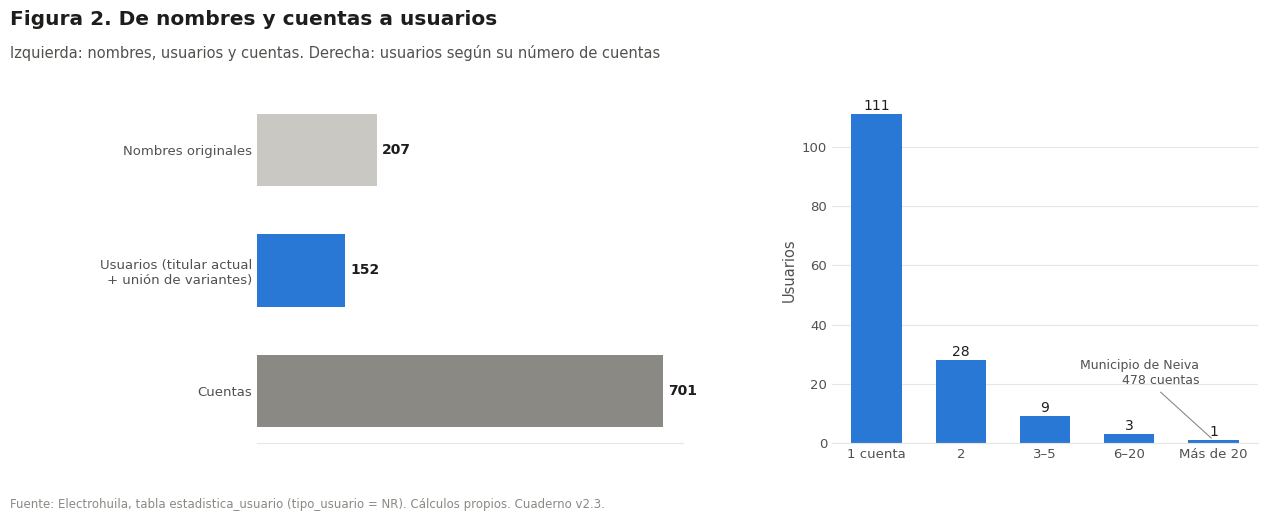

,ETIQUETA,CUENTAS,VARIANTES_NOMBRE,PRIMER_MES,ULTIMO_MES,CONSUMO_TOTAL_KWH
USUARIO,,,,,,
MUNICIPIO DE NEIVA,MUNICIPIO DE NEIVA,478,5,2020-01-01,2026-09-01,90360350
COMERCIALIZADORA AGRICOLA ASOJ,COMERCIALIZADORA AGRICOLA ASOJ,1,1,2020-01-01,2026-09-01,60647046
KYNDRYL COLOMBIA SAS,KYNDRYL COLOMBIA SAS,2,2,2022-01-01,2026-09-01,49556765
PISCICOLA NEW YORK S.A.,PISCICOLA NEW YORK S.A.,4,4,2020-01-01,2026-09-01,44521260
FIDUCIARIA DAVIVIENDA S.A.,FIDUCIARIA DAVIVIENDA S.A.,1,3,2022-01-01,2026-09-01,38417391
CI PISCICOLA BOTERO S.A.,CI PISCICOLA BOTERO S.A.,5,1,2020-01-01,2026-09-01,37089554
ASOC.USU.DIST.ADE.TIE.PQA.ESC.,ASOC.USU.DIST.ADE.TIE.PQA.ESC.,1,1,2020-01-01,2026-09-01,33116279
CAJA DE COMPENSACION FAMILIAR,CAJA DE COMPENSACION FAMILIAR,4,1,2020-01-01,2026-09-01,24047881
E.S.E. HOSPITAL UNIVERSITARIO,E.S.E. HOSPITAL UNIVERSITARIO,2,3,2020-01-01,2026-09-01,23237391


In [17]:
# =============================================================================
# 4.6 Resultado de la consolidación: tabla de usuarios, códigos seudónimos y figura
# -----------------------------------------------------------------------------
# USUARIO = NOMBRE_UNICO (152 usuarios). Cada usuario recibe un código Uxxx (por consumo total)
# y los titulares que parecen personas naturales se muestran como "Persona natural Uxxx".
# =============================================================================
def normalizar(t):
    """Mayúsculas y un solo espacio entre palabras (para comparar nombres)."""
    return re.sub(r'\s+', ' ', str(t).upper().strip())

def solo_letras(t):
    """Nombre sin puntos ni espacios, para medir similitud de texto."""
    return re.sub(r'[^A-Z0-9 ]', '', t.replace('.', '')).replace(' ', '')

df_a['USUARIO'] = df_a['NOMBRE_UNICO']
n_original, n_limpio, n_usuarios = df['NOMBRE'].nunique(), df_a['NOMBRE_LIMPIO'].nunique(), df_a['USUARIO'].nunique()
listado_usuarios = sorted(df_a['USUARIO'].unique())
assert df_a.groupby('CUENTA')['USUARIO'].nunique().max() == 1, 'Hay cuentas asignadas a más de un usuario'

# --- Tipo de cambio de nombre por cuenta (solo para revisión; no cambia la asignación) ---
reporte_final['SIMILITUD'] = [round(SequenceMatcher(None, solo_letras(a), solo_letras(b)).ratio(), 2)
                              for a, b in zip(reporte_final['PRIMER_NOMBRE'], reporte_final['ULTIMO_NOMBRE'])]
reporte_final['TIPO_CAMBIO'] = np.where(reporte_final['SIMILITUD'] >= 0.6, 'Variante de escritura o forma societaria',
                                        'Posible cambio de titular')
TABLA_CAMBIOS = (reporte_final.rename(columns={
    'CUENTA': 'Cuenta', 'NOMBRES_ENCONTRADOS': 'Nombres encontrados (orden cronológico)', 'CANT_NOMBRES': 'Cantidad de nombres',
    'PRIMER_NOMBRE': 'Primer nombre', 'ULTIMO_NOMBRE': 'Último nombre', 'SIMILITUD': 'Similitud', 'TIPO_CAMBIO': 'Tipo de cambio'})
    .sort_values(['Tipo de cambio', 'Similitud']))
exportar_excel(DIR_TAB / 'reporte_cambios_nombre.xlsx', [{
    'hoja': 'Cuentas con varios nombres', 'tabla': TABLA_CAMBIOS,
    'titulo': 'Cuentas que aparecen con más de un nombre de titular',
    'descripcion': 'El último nombre es el titular actual al que se asigna la cuenta. Similitud < 0,6 = posible cambio de titular.'}])

# --- Nombres anteriores que pasan al titular actual de su cuenta ---
absorbidos = (df_a[df_a['NOMBRE_LIMPIO'] != df_a['USUARIO'].map(normalizar)]
              .groupby(['NOMBRE_LIMPIO', 'USUARIO']).agg(CUENTAS=('CUENTA', 'nunique'), REGISTROS=('CUENTA', 'size'))
              .reset_index().rename(columns={'NOMBRE_LIMPIO': 'NOMBRE_ANTERIOR', 'USUARIO': 'TITULAR_ACTUAL'})
              .sort_values('REGISTROS', ascending=False))

# --- Pares de usuarios con nombres muy parecidos que siguen separados (para confirmar con el NIT) ---
base_txt = {u: solo_letras(normalizar(u)) for u in listado_usuarios}
candidatos = pd.DataFrame(
    [{'NOMBRE_A': a, 'NOMBRE_B': b, 'SIMILITUD': round(r, 2)}
     for i, a in enumerate(listado_usuarios) for b in listado_usuarios[i + 1:]
     if (r := SequenceMatcher(None, base_txt[a], base_txt[b]).ratio()) >= 0.85 or base_txt[a][:15] == base_txt[b][:15]],
    columns=['NOMBRE_A', 'NOMBRE_B', 'SIMILITUD']).sort_values('SIMILITUD', ascending=False)
TABLA_CANDIDATOS = candidatos.rename(columns={'NOMBRE_A': 'Nombre A', 'NOMBRE_B': 'Nombre B', 'SIMILITUD': 'Similitud'})
TABLA_CANDIDATOS[['Decisión (unir / separar)', 'Observación']] = ''
exportar_excel(DIR_TAB / 'candidatos_homologacion_pendiente.xlsx', [{
    'hoja': 'Pendientes de revisión', 'tabla': TABLA_CANDIDATOS, 'titulo': 'Pares de nombres parecidos que NO se unieron',
    'descripcion': 'Confirme con el NIT. Si deben unirse, agréguelos al diccionario remplazar (sección 4.4).'}])

# --- Protección de personas naturales: regla de texto (2–6 palabras, sin palabras de empresa) ---
PALABRAS_ENTIDAD = {
    'SAS', 'SA', 'LTDA', 'ESP', 'CIA', 'SCA', 'MUNICIPIO', 'HOSPITAL', 'CLINICA', 'ESE', 'EMPRESA', 'EMPRESAS',
    'INVERSIONES', 'ASOCIACION', 'CENTRO', 'COMERCIAL', 'COLOMBIA', 'DEPARTAMENTO', 'NACIONAL', 'POLICIA', 'UNIVERSIDAD',
    'INSTITUTO', 'COOPERATIVA', 'FONDO', 'CAJA', 'HOTEL', 'HOTELES', 'PISCICOLA', 'AVICOLA', 'CAFE', 'CARNES', 'FIDUCIARIA',
    'DIRECCION', 'UNIDAD', 'SALUD', 'BANCO', 'GRUPO', 'SOCIEDAD', 'CORPORACION', 'CORPORACIÓN', 'FUNDACION',
    'COMERCIALIZADORA', 'INDUSTRIA', 'INDUSTRIAS', 'MINERALES', 'DISTRITO', 'USUARIOS', 'CONSORCIO', 'UNION', 'TEMPORAL',
    'GOBERNACION', 'HUILA', 'NEIVA', 'SEDE', 'INTEGRADOR', 'EDS', 'ESTACION', 'CONJUNTO', 'INMOBILIARIO', 'LADRILLERA',
    'SUPERMERCADO', 'LABORATORIO', 'TRITURADOS', 'MOTEL', 'INDUCON', 'CONSTRUCTORA', 'TRILLADORA', 'EXPORTADORES',
    'FERRETERIA', 'MOLINO', 'ARROCERA', 'COMPAÑIA', 'ALFAREROS', 'ALMACENES', 'DISEÑO', 'COSTRUCCION', 'CONSTRUCCION',
    'ARCILLAS', 'FERTILIZANTES', 'QUIMICOS', 'TIERRAS'}

def probable_persona_natural(nombre):
    if re.search(r'\bS\W{0,2}A\b|\bS\W?EN\W?C\b|&', nombre):
        return False
    tokens = re.sub(r'[^A-ZÑÁÉÍÓÚ ]', ' ', nombre).split()
    if any(t in PALABRAS_ENTIDAD or t.startswith(('ASO', 'COO', 'AGRO', 'INVER', 'COMER', 'DISTRI')) for t in tokens):
        return False
    return 2 <= len(tokens) <= 6

# --- Tabla maestra de usuarios ---
usuarios = (df_a.groupby('USUARIO')
            .agg(CUENTAS=('CUENTA', 'nunique'), VARIANTES_NOMBRE=('NOMBRE_LIMPIO', 'nunique'),
                 PRIMER_MES=('FECHA', 'min'), ULTIMO_MES=('FECHA', 'max'), CONSUMO_TOTAL_KWH=('TOTAL_ACTIVA', 'sum'))
            .sort_values('CONSUMO_TOTAL_KWH', ascending=False))
usuarios['CODIGO'] = [f'U{i + 1:03d}' for i in range(len(usuarios))]
usuarios['PERSONA_NATURAL'] = usuarios.index.map(probable_persona_natural)
usuarios['ETIQUETA'] = usuarios.index.str.strip()
# La clasificación se conserva en PERSONA_NATURAL y Tipo de titular, sin reemplazar el nombre.
df_a['CODIGO_USUARIO'] = df_a['USUARIO'].map(usuarios['CODIGO'])
ETIQUETA = usuarios.set_index('CODIGO')['ETIQUETA']

print(f'Nombres originales: {n_original} | usuarios: {n_usuarios} | cuentas: {df_a["CUENTA"].nunique()} | '
      f'nombres absorbidos por el titular actual: {absorbidos["NOMBRE_ANTERIOR"].nunique()} | '
      f'pares parecidos sin unir: {len(candidatos)} | personas naturales protegidas: {usuarios["PERSONA_NATURAL"].sum()}')

# --- Figura: de nombres y cuentas a usuarios ---
pasos = pd.Series({'Nombres originales': n_original, 'Usuarios (titular actual\n+ unión de variantes)': n_usuarios,
                   'Cuentas': df_a['CUENTA'].nunique()})
dist_cuentas = (pd.cut(usuarios['CUENTAS'], [0, 1, 2, 5, 20, np.inf], labels=['1 cuenta', '2', '3–5', '6–20', 'Más de 20'])
                .value_counts().sort_index())
fig, (ax1, ax2) = nueva_figura('De nombres y cuentas a usuarios',
                               'Izquierda: nombres, usuarios y cuentas. Derecha: usuarios según su número de cuentas',
                               ancho=13, alto=5, columnas=2)
fig.subplots_adjust(wspace=0.35, left=0.2)
y = np.arange(len(pasos))[::-1]
ax1.barh(y, pasos.values, color=[GRIS_SUAVE, AZUL, TINTA_3], height=0.6)
ax1.set_yticks(y, pasos.index); ax1.grid(False); ax1.set_xticks([])
for yi, v in zip(y, pasos.values):
    ax1.annotate(f'{v}', (v, yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=10, fontweight='bold')
ax2.bar(dist_cuentas.index.astype(str), dist_cuentas.values, color=AZUL, width=0.6)
for i, v in enumerate(dist_cuentas.values):
    ax2.annotate(f'{v}', (i, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=10)
ax2.set_ylabel('Usuarios')
mayor = usuarios.iloc[usuarios['CUENTAS'].argmax()]
ax2.annotate(f"{mayor['ETIQUETA'].title().replace(' De ', ' de ')}\n{mayor['CUENTAS']} cuentas", (4, dist_cuentas.iloc[-1]),
             xytext=(-10, 40), textcoords='offset points', ha='right', fontsize=9, color=TINTA_2,
             arrowprops=dict(arrowstyle='-', color=TINTA_3, lw=0.8))
guardar(fig, 'consolidacion_usuarios')
usuarios.head(10)[['ETIQUETA', 'CUENTAS', 'VARIANTES_NOMBRE', 'PRIMER_MES', 'ULTIMO_MES', 'CONSUMO_TOTAL_KWH']]

**Interpretación — consolidación de usuarios**

- **Qué muestra:** nombres, usuarios y cuentas (izquierda) y cuántas cuentas tiene cada usuario (derecha).
- **Hallazgos:**
  - Detrás de las **701 cuentas** hay **152 usuarios**.
  - 111 usuarios (73 %) tienen una sola cuenta y 28 tienen dos.
  - El **Municipio de Neiva** tiene **478 cuentas** (68 % del total) y es el mayor usuario por consumo acumulado (90,4 GWh entre 2020 y 2026).
  - Quedan 9 pares de nombres parecidos sin unir (hospitales San Antonio y San Vicente, comercializadoras y centros comerciales): son entidades distintas.
  - 13 titulares parecen personas naturales; en resultados se muestran como “Persona natural Uxxx”.


## 5. Evolución de usuarios y cuentas

A partir de aquí se trabaja con la **base de análisis**: enero 2020 – último mes completo (octubre de 2026 se excluye por incompleto). Un usuario se cuenta en un mes si al menos una de sus cuentas tiene registro ese mes.

### 5.1 Usuarios y cuentas observados cada mes

Último mes completo: 2026-09. Registros excluidos (mes incompleto): 2 (495,606 kWh)


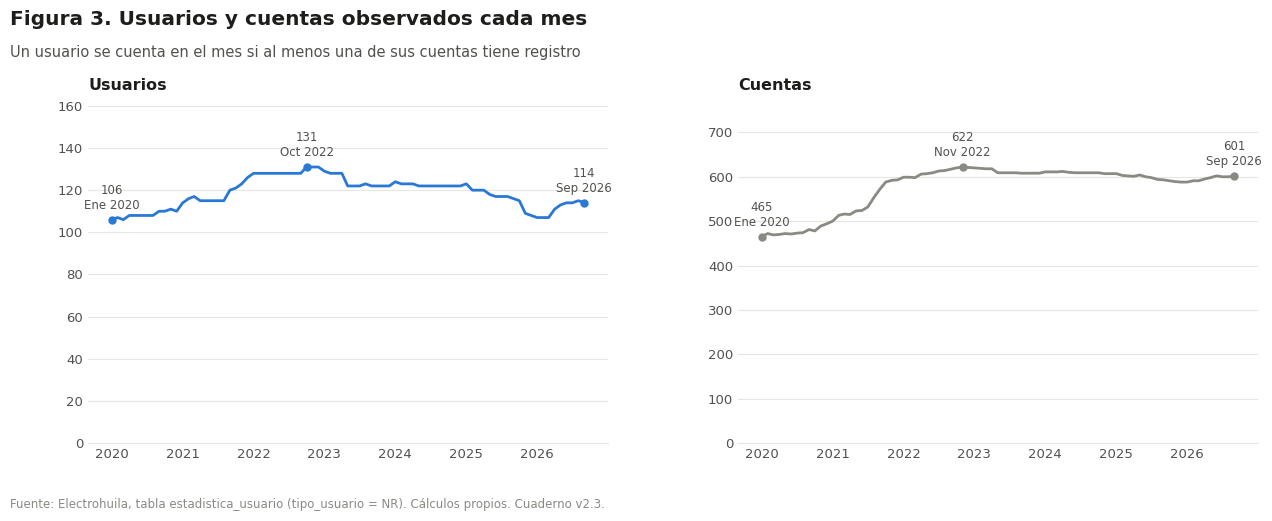

In [18]:
base = df_a[df_a['FECHA'] <= ULTIMO_MES].copy()
excluidos = df_a[df_a['FECHA'] > ULTIMO_MES]
print(f'Último mes completo: {ULTIMO_MES:%Y-%m}. Registros excluidos (mes incompleto): {len(excluidos)} '
      f'({excluidos["TOTAL_ACTIVA"].sum():,.0f} {UNIDAD})')
mensual = base.groupby('FECHA').agg(USUARIOS=('USUARIO', 'nunique'), CUENTAS=('CUENTA', 'nunique'),
                                    CONSUMO_KWH=('TOTAL_ACTIVA', 'sum'))
mensual['CUENTAS_POR_USUARIO'] = mensual['CUENTAS'] / mensual['USUARIOS']

fig, (ax1, ax2) = nueva_figura('Usuarios y cuentas observados cada mes',
                               'Un usuario se cuenta en el mes si al menos una de sus cuentas tiene registro',
                               alto=5, columnas=2, ancho=13)
fig.subplots_adjust(wspace=0.25)
for ax, col, color, tit in [(ax1, 'USUARIOS', AZUL, 'Usuarios'), (ax2, 'CUENTAS', TINTA_3, 'Cuentas')]:
    ax.plot(mensual.index, mensual[col], color=color)
    ax.set_title(tit, loc='left', fontsize=11.5, fontweight='bold', color=TINTA)
    for f in [mensual.index.min(), mensual[col].idxmax(), mensual.index.max()]:
        ax.plot(f, mensual.loc[f, col], 'o', color=color, ms=5)
        ax.annotate(f"{mensual.loc[f, col]}\n{MESES_ES[f.month - 1]} {f.year}", (f, mensual.loc[f, col]),
                    xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8.5, color=TINTA_2)
    ax.set_ylim(0, mensual[col].max() * 1.25); eje_fechas(ax)
guardar(fig, 'usuarios_cuentas_mensual')

**Interpretación — usuarios y cuentas en el tiempo**

- **Qué muestra:** el número de usuarios (izquierda) y de cuentas (derecha) con registro en cada mes.
- **Hallazgos:**
  - Los usuarios suben de 106 en enero de 2020 a un máximo de 131 en octubre de 2022. Bajan gradualmente hasta 107 a inicios de 2026 y se ubican en 114 en septiembre de 2026.
  - Las cuentas siguen la misma forma (465 → 622 → 601), pero se mueven sobre todo por el Municipio de Neiva, que pasó de 355 a 464 cuentas.


### 5.2 Cuentas por año: registradas, nuevas y que dejan de observarse

,Año,Registradas,Nuevas (no estaban el año anterior),Dejan de observarse
0,2020,509,NaN,NaN
1,2021,604,107.00,12.00
2,2022,631,43.00,16.00
3,2023,621,4.00,14.00
4,2024,617,9.00,13.00
5,2025,617,11.00,11.00
6,2026,612,17.00,22.00


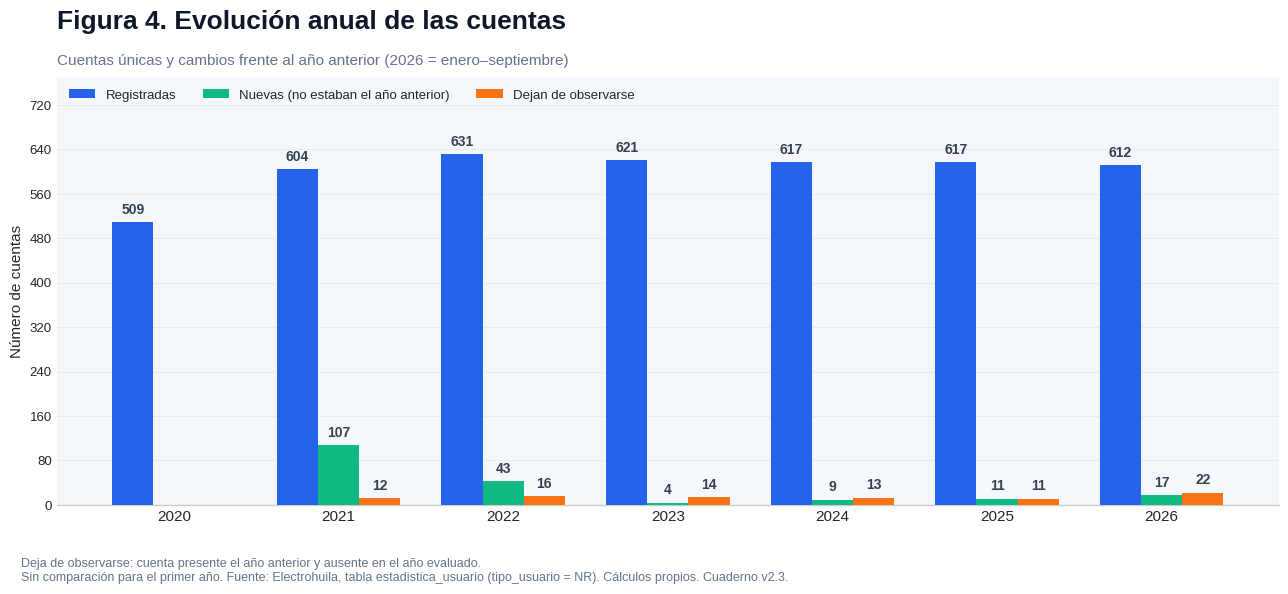

In [19]:
# Una cuenta se cuenta una sola vez por año (2026 = enero–septiembre, sin el mes incompleto)
col_anio = "ANO"
col_cuenta = "CUENTA"

base_cuentas = base[[col_anio, col_cuenta]].dropna().copy()
base_cuentas[col_anio] = base_cuentas[col_anio].astype(int)

cuentas = base_cuentas.groupby(col_anio)[col_cuenta].agg(set).sort_index()

resumen = []
for anio in cuentas.index:
    actuales = cuentas.loc[anio]
    # Solo comparar cuando existe el año inmediatamente anterior
    comparable = (anio - 1) in cuentas.index
    anteriores = cuentas.loc[anio - 1] if comparable else set()
    resumen.append({
        "Año": anio,
        "Registradas": len(actuales),
        "Nuevas (no estaban el año anterior)": len(actuales - anteriores) if comparable else np.nan,
        "Dejan de observarse": len(anteriores - actuales) if comparable else np.nan,
    })
resumen = pd.DataFrame(resumen)
display(resumen)

# Estilo del gráfico (se aplica solo a esta figura para no cambiar el estilo de las demás)
N_FIGURA += 1
with plt.style.context("seaborn-v0_8-whitegrid"):
    fig, ax = plt.subplots(figsize=(13, 6), facecolor="#F4F7FB")
    ax.set_facecolor("#F4F7FB")
    x = np.arange(len(resumen))
    ancho = 0.25
    series = [
        ("Registradas", "#2563EB", -ancho),
        ("Nuevas (no estaban el año anterior)", "#10B981", 0),
        ("Dejan de observarse", "#F97316", ancho),
    ]
    for columna, color, desplazamiento in series:
        valores = resumen[columna].to_numpy(dtype=float)
        barras = ax.bar(x + desplazamiento, valores, width=ancho, label=columna, color=color, zorder=3)
        ax.bar_label(barras, labels=[f"{v:,.0f}" if pd.notna(v) else "" for v in valores],
                     padding=4, fontsize=10, fontweight="bold", color="#334155")
    ax.set_title(f"Figura {N_FIGURA}. Evolución anual de las cuentas", loc="left", fontsize=19, fontweight="bold",
                 color="#0F172A", pad=35)
    ax.text(0, 1.03, "Cuentas únicas y cambios frente al año anterior (2026 = enero–septiembre)",
            transform=ax.transAxes, fontsize=11, color="#64748B")
    ax.set_xticks(x)
    ax.set_xticklabels(resumen["Año"], fontsize=11)
    ax.set_ylabel("Número de cuentas", fontsize=11)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.25, zorder=0)
    ax.grid(axis="x", visible=False)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.legend(frameon=False, ncol=3, loc="upper left")
    ax.margins(y=0.22)
    fig.text(0.02, 0.02,
             "Deja de observarse: cuenta presente el año anterior y ausente en el año evaluado.\n"
             "Sin comparación para el primer año. " + FUENTE,
             fontsize=9, color="#64748B")
    plt.tight_layout(rect=[0, 0.09, 1, 1])
    fig.savefig(DIR_FIG / f'{N_FIGURA:02d}_cuentas_por_anio.png')
    plt.show()

**Interpretación — cuentas por año**

- **Qué muestra:** cuántas cuentas distintas tienen registro cada año, cuántas son nuevas frente al año anterior y cuántas dejan de observarse.
- **Hallazgos:**
  - Las cuentas pasan de 509 en 2020 a 604 en 2021 (+107 nuevas, la mayoría del Municipio de Neiva) y a 631 en 2022, el máximo.
  - Desde 2023 la base se estabiliza en ≈ 617–621 cuentas, con 4 a 11 cuentas nuevas y 11 a 14 que dejan de observarse por año.
  - En 2026 (enero–septiembre) hay 612 cuentas: 17 nuevas y 22 que dejan de observarse, el mayor número de salidas del periodo.


### 5.3 Flujos anuales de usuarios: primera aparición y deja de observarse

- **Primera aparición:** el usuario se observa por primera vez ese año (para 2020 no se puede saber si ya existía antes, por eso no se calcula).
- **Deja de observarse:** el último año en que se observa el usuario es el anterior y no vuelve a aparecer hasta el último mes completo.
- **Reaparece:** se observa este año, no el anterior, pero sí antes.

In [20]:
anios_usuario = base.groupby('USUARIO')['ANO'].apply(set)
ANIOS = sorted(base['ANO'].unique())
filas = []
for a in ANIOS:
    obs = {u for u, s in anios_usuario.items() if a in s}
    prev = {u for u, s in anios_usuario.items() if a - 1 in s}
    antes = {u for u, s in anios_usuario.items() if min(s) < a}
    primera = {u for u in obs if min(anios_usuario[u]) == a}
    reaparece = {u for u in obs - prev if u in antes and u not in primera}
    deja = {u for u in prev - obs if max(anios_usuario[u]) == a - 1}
    filas.append({'AÑO': a, 'USUARIOS_OBSERVADOS': len(obs),
                  'PRIMERA_APARICION': len(primera) if a > ANIOS[0] else np.nan,
                  'REAPARECE': len(reaparece) if a > ANIOS[0] else np.nan,
                  'DEJA_DE_OBSERVARSE': len(deja) if a > ANIOS[0] else np.nan,
                  'PERMANECE_DEL_AÑO_ANTERIOR': len(obs & prev) if a > ANIOS[0] else np.nan})
flujos = pd.DataFrame(filas).set_index('AÑO').astype('Int64')
# Identidad contable: observados(t) = observados(t-1) + primera + reaparece − deja de observarse − pausas (no observados en t pero sí después)
flujos

,USUARIOS_OBSERVADOS,PRIMERA_APARICION,REAPARECE,DEJA_DE_OBSERVARSE,PERMANECE_DEL_AÑO_ANTERIOR
AÑO,,,,,
2020,113,<NA>,<NA>,<NA>,<NA>
2021,129,19,0,3,110
2022,133,7,0,3,126
2023,130,1,0,4,129
2024,125,3,0,8,122
2025,126,4,0,3,122
2026,117,4,0,13,113


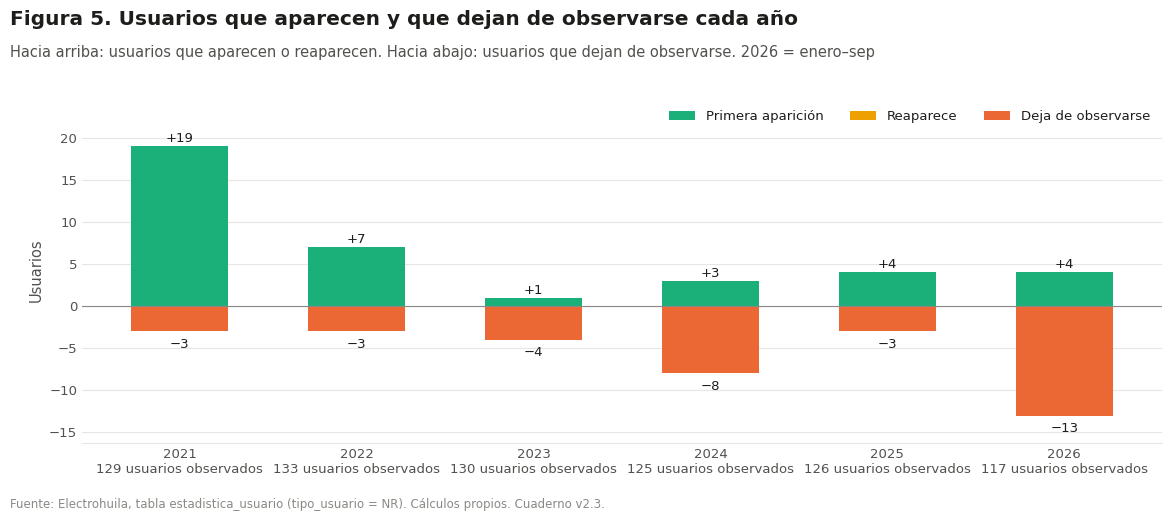

In [21]:
f2 = flujos.iloc[1:]
fig, ax = nueva_figura('Usuarios que aparecen y que dejan de observarse cada año',
                       f'Hacia arriba: usuarios que aparecen o reaparecen. Hacia abajo: usuarios que dejan de observarse. 2026 = enero–{MESES_ES[ULTIMO_MES.month - 1].lower()}',
                       alto=5)
x = np.arange(len(f2))
ax.bar(x, f2['PRIMERA_APARICION'].astype(float), color=AQUA, width=0.55, label='Primera aparición')
ax.bar(x, f2['REAPARECE'].astype(float), bottom=f2['PRIMERA_APARICION'].astype(float), color=AMARILLO, width=0.55, label='Reaparece')
ax.bar(x, -f2['DEJA_DE_OBSERVARSE'].astype(float), color=NARANJA, width=0.55, label='Deja de observarse')
for i, (_, r) in enumerate(f2.iterrows()):
    ax.annotate(f"+{int(r['PRIMERA_APARICION'] + r['REAPARECE'])}", (i, r['PRIMERA_APARICION'] + r['REAPARECE']),
                xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9.5)
    ax.annotate(f"−{int(r['DEJA_DE_OBSERVARSE'])}", (i, -r['DEJA_DE_OBSERVARSE']), xytext=(0, -12),
                textcoords='offset points', ha='center', fontsize=9.5)
ax.axhline(0, color=TINTA_3, lw=0.8)
ax.set_xticks(x, [f'{a}\n{v} usuarios observados' for a, v in f2['USUARIOS_OBSERVADOS'].items()])
ax.set_ylabel('Usuarios')
ax.set_ylim(-f2['DEJA_DE_OBSERVARSE'].max() * 1.25, (f2['PRIMERA_APARICION'] + f2['REAPARECE']).max() * 1.3)
ax.legend(loc='upper right', ncol=3)
guardar(fig, 'flujos_anuales_usuarios')

**Interpretación — flujos anuales de usuarios**

- **Qué muestra:** en cada año, cuántos usuarios aparecen por primera vez y cuántos dejan de observarse.
- **Hallazgos:**
  - 2021 fue el año de mayor entrada neta (+19/−3) y 2022 siguió en positivo (+7/−3).
  - Entre 2023 y 2025 las entradas y salidas son pequeñas (1 a 8 por año).
  - En 2026 hay **13 usuarios** que se observaron en 2025 y no aparecen en enero–septiembre de 2026; en 2025 consumieron 2,8 GWh. Solo aparecen 4 usuarios nuevos, que suman 1,1 GWh.


### 5.4 Permanencia: cuántos meses se observa cada usuario

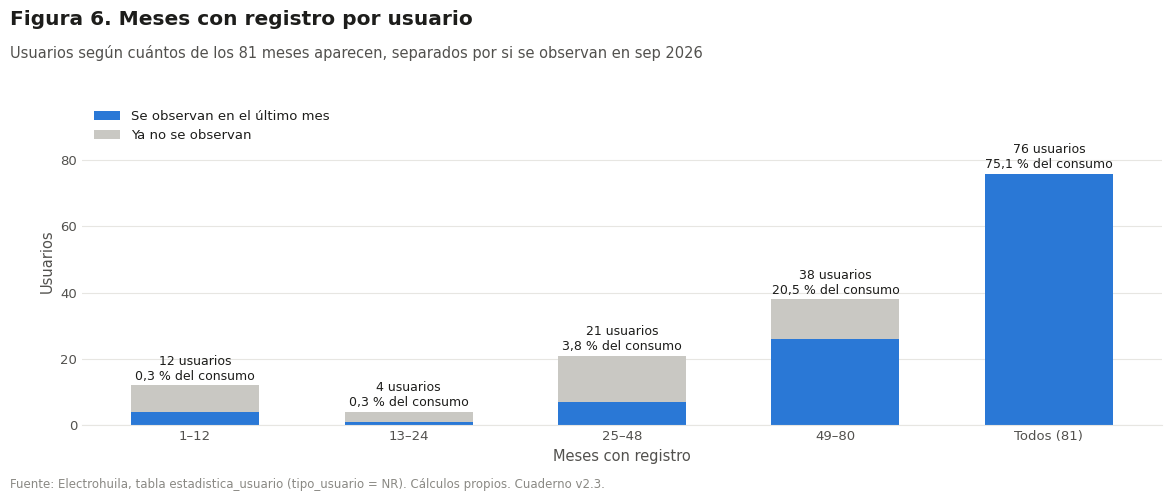

ACTIVO_HOY,Ya no se observan,Activos en el último mes,Usuarios,% del consumo 2020–2026
Meses con registro,,,,
1–12,8,4,12,0.26
13–24,3,1,4,0.27
25–48,14,7,21,3.81
49–80,12,26,38,20.55
Todos (81),0,76,76,75.12


In [22]:
N_MESES = mensual.shape[0]
perm = base.groupby('CODIGO_USUARIO').agg(MESES=('FECHA', 'nunique'), ULTIMO=('FECHA', 'max'), KWH=('TOTAL_ACTIVA', 'sum'))
perm['ACTIVO_HOY'] = perm['ULTIMO'] == ULTIMO_MES
tramos_perm = pd.cut(perm['MESES'], [0, 12, 24, 48, N_MESES - 1, N_MESES],
                     labels=['1–12', '13–24', '25–48', f'49–{N_MESES - 1}', f'Todos ({N_MESES})'])
tabla_perm = (perm.groupby([tramos_perm, 'ACTIVO_HOY'], observed=False).size().unstack(fill_value=0)
              .rename(columns={True: 'Activos en el último mes', False: 'Ya no se observan'}))
tabla_perm['Usuarios'] = tabla_perm.sum(axis=1)
tabla_perm['% del consumo 2020–2026'] = perm.groupby(tramos_perm, observed=False)['KWH'].sum() / perm['KWH'].sum() * 100
tabla_perm.index.name = 'Meses con registro'
panel = perm.index[perm['MESES'] == N_MESES]

fig, ax = nueva_figura('Meses con registro por usuario',
                       f'Usuarios según cuántos de los {N_MESES} meses aparecen, separados por si se observan en {MESES_ES[ULTIMO_MES.month - 1].lower()} {ULTIMO_MES.year}',
                       alto=4.8)
xs = np.arange(len(tabla_perm))
ax.bar(xs, tabla_perm['Activos en el último mes'], color=AZUL, width=0.6, label='Se observan en el último mes')
ax.bar(xs, tabla_perm['Ya no se observan'], bottom=tabla_perm['Activos en el último mes'], color=GRIS_SUAVE, width=0.6,
       label='Ya no se observan')
for i, (u, c) in enumerate(zip(tabla_perm['Usuarios'], tabla_perm['% del consumo 2020–2026'])):
    ax.annotate(f'{u} usuarios\n{fmt_es(c)} % del consumo', (i, u), xytext=(0, 4), textcoords='offset points',
                ha='center', fontsize=9)
ax.set_xticks(xs, tabla_perm.index.astype(str)); ax.set_xlabel('Meses con registro'); ax.set_ylabel('Usuarios')
ax.set_ylim(0, tabla_perm['Usuarios'].max() * 1.3); ax.legend(loc='upper left')
guardar(fig, 'permanencia_usuarios')
tabla_perm

**Interpretación — permanencia de los usuarios**

- **Qué muestra:** cuántos usuarios aparecen en cada rango de meses y si siguen presentes en septiembre de 2026.
- **Hallazgos:**
  - **76 usuarios están presentes en los 81 meses** y concentran el 75,1 % del consumo del periodo: son el núcleo estable.
  - Otros 38 usuarios aparecen entre 49 y 80 meses (20,6 % del consumo).
  - 12 usuarios aparecen 12 meses o menos y pesan 0,3 %; 8 de ellos ya no se observan.


## 6. Consumo agregado: tendencia, estacionalidad y composición

### 6.1 Consumo anual y comparación de periodos equivalentes

In [23]:
MES_CORTE = ULTIMO_MES.month
anual = base.groupby('ANO')['TOTAL_ACTIVA'].sum().to_frame('CONSUMO_GWH') / 1e6
anual['MESES'] = base.groupby('ANO')['MES'].nunique()
anual['VAR_%_AÑO'] = anual['CONSUMO_GWH'].pct_change() * 100
anual.loc[anual['MESES'] < 12, 'VAR_%_AÑO'] = np.nan
anual[f'ENE–{MESES_ES[MES_CORTE - 1].upper()}_GWH'] = base[base['MES'] <= MES_CORTE].groupby('ANO')['TOTAL_ACTIVA'].sum() / 1e6
anual['VAR_%_PERIODO_EQUIV'] = anual.iloc[:, 3].pct_change() * 100
anual['PROMEDIO_MENSUAL_GWH'] = anual['CONSUMO_GWH'] / anual['MESES']
anual

,CONSUMO_GWH,MESES,VAR_%_AÑO,ENE–SEP_GWH,VAR_%_PERIODO_EQUIV,PROMEDIO_MENSUAL_GWH
ANO,,,,,,
2020,125.88,12,NaN,92.71,NaN,10.49
2021,131.37,12,4.37,98.63,6.40,10.95
2022,156.99,12,19.50,116.86,18.47,13.08
2023,154.56,12,-1.55,115.58,-1.09,12.88
2024,159.79,12,3.39,121.03,4.72,13.32
2025,143.62,12,-10.12,108.06,-10.72,11.97
2026,106.00,9,NaN,106.00,-1.90,11.78


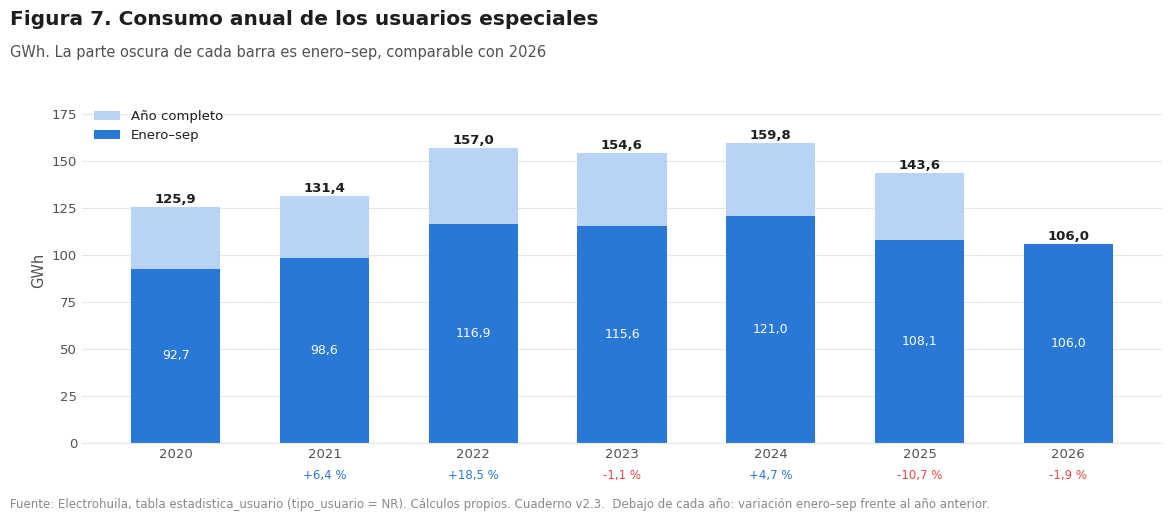

In [24]:
fig, ax = nueva_figura('Consumo anual de los usuarios especiales',
                       f'GWh. La parte oscura de cada barra es enero–{MESES_ES[MES_CORTE - 1].lower()}, comparable con 2026', alto=5)
xa = anual.index.astype(str)
ax.bar(xa, anual['CONSUMO_GWH'], color='#b7d3f6', width=0.6, label='Año completo')
ax.bar(xa, anual.iloc[:, 3], color=AZUL, width=0.6, label=f'Enero–{MESES_ES[MES_CORTE - 1].lower()}')
for i, (a, r) in enumerate(anual.iterrows()):
    ax.annotate(fmt_es(r['CONSUMO_GWH']), (i, r['CONSUMO_GWH']), xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=9.5, fontweight='bold')
    ax.annotate(fmt_es(r.iloc[3]), (i, r.iloc[3] / 2), ha='center', va='center', fontsize=9, color='white')
    if not np.isnan(r['VAR_%_PERIODO_EQUIV']):
        color = AZUL if r['VAR_%_PERIODO_EQUIV'] >= 0 else ROJO
        ax.annotate(f"{r['VAR_%_PERIODO_EQUIV']:+.1f} %".replace('.', ','), (i, 0), xytext=(0, -26),
                    textcoords='offset points', ha='center', fontsize=8.5, color=color)
ax.set_ylabel('GWh'); ax.legend(loc='upper left')
ax.set_ylim(0, anual['CONSUMO_GWH'].max() * 1.15)
guardar(fig, 'consumo_anual', nota=f'Debajo de cada año: variación enero–{MESES_ES[MES_CORTE - 1].lower()} frente al año anterior.')

**Interpretación — consumo anual**

- **Qué muestra:** el consumo de cada año en GWh y, en la parte oscura, enero–septiembre para comparar con 2026.
- **Hallazgos:**
  - El consumo creció de 125,9 GWh (2020) a 157,0 GWh (2022) y llegó a un máximo de 159,8 GWh en 2024.
  - En 2025 cayó a 143,6 GWh (−10,1 %).
  - Enero–septiembre de 2026 suma 106,0 GWh, −1,9 % frente al mismo periodo de 2025.
  - El salto de 2022 (+18,5 %) coincide con la entrada de *Kyndryl Colombia* y de la cuenta hoy de la *Fiduciaria Davivienda* (antes IBM), que juntas sumaron 19,7 GWh ese año.
  - La caída de 2025 (−16,2 GWh) es generalizada: los usuarios que bajaron restan 20,8 GWh y los que subieron suman 4,6 GWh. Las mayores bajas fueron Comercializadora Agrícola Asoj (−1,9), Caja de Compensación Familiar (−1,6), Químicos e Impalpables del Huila (−1,2) y Piscícola New York (−1,1).


### 6.2 Evolución mensual

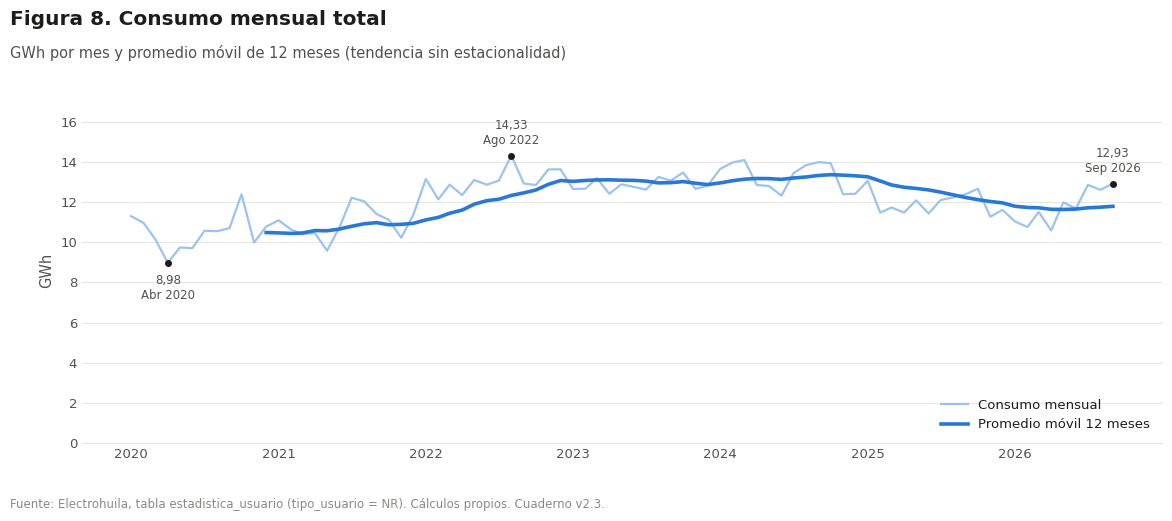

In [25]:
serie = mensual['CONSUMO_KWH'] / 1e6
media_movil = serie.rolling(12).mean()
fig, ax = nueva_figura('Consumo mensual total',
                       'GWh por mes y promedio móvil de 12 meses (tendencia sin estacionalidad)', alto=5)
ax.plot(serie.index, serie, color='#9cc2f0', lw=1.6, label='Consumo mensual')
ax.plot(media_movil.index, media_movil, color=AZUL, lw=2.6, label='Promedio móvil 12 meses')
for f in [serie.idxmax(), serie.idxmin(), serie.index.max()]:
    ax.plot(f, serie[f], 'o', color=TINTA, ms=4)
    ax.annotate(f"{fmt_es(serie[f], 2)}\n{MESES_ES[f.month - 1]} {f.year}", (f, serie[f]), xytext=(0, 8 if f != serie.idxmin() else -26),
                textcoords='offset points', ha='center', fontsize=8.5, color=TINTA_2)
ax.set_ylabel('GWh'); ax.set_ylim(0, serie.max() * 1.2); eje_fechas(ax); ax.legend(loc='lower right')
guardar(fig, 'consumo_mensual')

**Versión interactiva de la serie.** Al pasar el cursor se ve el valor de cada mes. Correcciones respecto a la versión anterior: (1) `TOTAL_ACTIVA` está en kWh, así que dividir entre 1.000.000 da **GWh**, no MWh; (2) se excluye octubre de 2026, que está incompleto y hacía que el “último dato” apareciera como una caída falsa. La figura también se guarda como HTML en `data/output/reportes/analisis_exploratorio/figuras/`.

In [26]:
import plotly.graph_objects as go

# =====================================
# SERIE DE TIEMPO DEL SISTEMA (sin el mes incompleto)
# =====================================
serie_sis = (
    base
    .groupby(["ANO", "MES"], as_index=False)
    .agg(TOTAL_ACTIVA=("TOTAL_ACTIVA", "sum"))
)
serie_sis["FECHA"] = pd.to_datetime(dict(year=serie_sis["ANO"], month=serie_sis["MES"], day=1))
serie_sis = serie_sis.sort_values("FECHA")

# Conversión: kWh / 1.000.000 = GWh
serie_sis["GWh"] = serie_sis["TOTAL_ACTIVA"] / 1_000_000

# Tendencia 12 meses (promedio móvil; solo desde el mes 12 para no sesgar el inicio)
serie_sis["TENDENCIA_12M"] = serie_sis["GWh"].rolling(window=12).mean()

ultimo = serie_sis.iloc[-1]
maximo = serie_sis.loc[serie_sis["GWh"].idxmax()]
minimo = serie_sis.loc[serie_sis["GWh"].idxmin()]

N_FIGURA += 1
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=serie_sis["FECHA"], y=serie_sis["GWh"], mode="lines", name="Consumo",
    line=dict(color="#003366", width=4),
    hovertemplate="<b>%{x|%b-%Y}</b><br>Consumo: %{y:,.2f} GWh<extra></extra>"))
fig.add_trace(go.Scatter(
    x=serie_sis["FECHA"], y=serie_sis["TENDENCIA_12M"], mode="lines", name="Tendencia 12 meses",
    line=dict(color="#F28E2B", width=3, dash="dash"),
    hovertemplate="Tendencia: %{y:,.2f} GWh<extra></extra>"))
fig.add_trace(go.Scatter(
    x=[maximo["FECHA"]], y=[maximo["GWh"]], mode="markers+text", text=[f"{maximo['GWh']:,.2f}"],
    textposition="top center", marker=dict(color="green", size=12), name="Máximo"))
fig.add_trace(go.Scatter(
    x=[ultimo["FECHA"]], y=[ultimo["GWh"]], mode="markers+text", text=[f"{ultimo['GWh']:,.2f}"],
    textposition="top center", marker=dict(color="red", size=12), name="Último mes completo"))
fig.update_layout(
    template="simple_white", height=600, hovermode="x unified",
    title=dict(text=(f"<b>Figura {N_FIGURA}. Evolución del consumo total (interactiva)</b><br>"
                     f"<sup>Último mes completo: {ultimo['GWh']:,.2f} GWh | "
                     f"Máximo: {maximo['GWh']:,.2f} GWh | Mínimo: {minimo['GWh']:,.2f} GWh</sup>"), x=0.5),
    legend=dict(orientation="h", y=1.02, x=0.5, xanchor="center", yanchor="bottom"),
    font=dict(family="Arial", size=14),
    margin=dict(t=120))
fig.update_xaxes(title="Periodo", showgrid=False)
fig.update_yaxes(title="Consumo (GWh)", gridcolor="#E6E6E6", tickformat=",.1f", rangemode="tozero")
fig.write_html(DIR_FIG / f'{N_FIGURA:02d}_consumo_mensual_interactivo.html', include_plotlyjs='cdn')
fig.show()

<Figure plotly>

**Interpretación — evolución mensual**

- **Qué muestra:** el consumo mensual total y su promedio móvil de 12 meses.
- **Hallazgos:**
  - El mínimo de la serie es abril de 2020 (8,98 GWh, 18 % menos que febrero de 2020), en pleno aislamiento por la pandemia.
  - El máximo es agosto de 2022 (14,33 GWh).
  - El promedio móvil sube hasta 2024 (≈ 13,3 GWh/mes), baja durante 2025 hasta ≈ 11,7 GWh/mes y se estabiliza en 2026.


### 6.3 Variación interanual mensual

Cada mes se compara con el mismo mes del año anterior; así se elimina la estacionalidad.

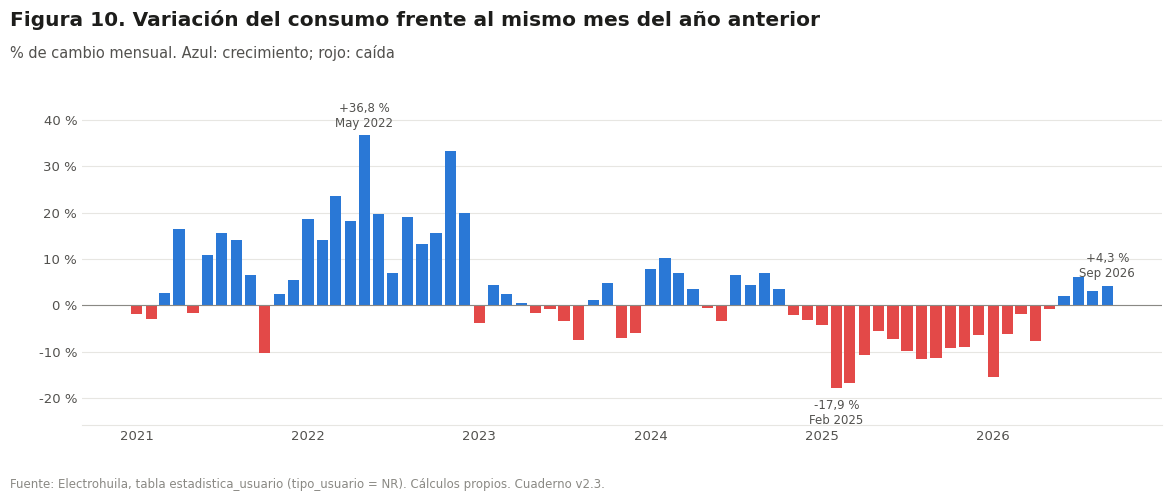

Meses con crecimiento interanual por año: {2021: 8, 2022: 12, 2023: 5, 2024: 8, 2025: 0, 2026: 4}


In [27]:
var_ia = (serie / serie.shift(12) - 1).dropna() * 100
fig, ax = nueva_figura('Variación del consumo frente al mismo mes del año anterior',
                       '% de cambio mensual. Azul: crecimiento; rojo: caída', alto=4.8)
ax.bar(var_ia.index, var_ia.values, width=24, color=[AZUL if v >= 0 else ROJO for v in var_ia])
ax.axhline(0, color=TINTA_3, lw=0.8)
for f in [var_ia.idxmax(), var_ia.idxmin(), var_ia.index.max()]:
    ax.annotate(f"{var_ia[f]:+.1f} %\n{MESES_ES[f.month - 1]} {f.year}".replace('.', ','), (f, var_ia[f]),
                xytext=(0, 6 if var_ia[f] >= 0 else -26), textcoords='offset points', ha='center', fontsize=8.5, color=TINTA_2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f'{v:.0f} %'))
ax.set_ylim(var_ia.min() - 8, var_ia.max() + 8); eje_fechas(ax)
guardar(fig, 'variacion_interanual')
meses_crec = (var_ia > 0).groupby(var_ia.index.year).sum()
print('Meses con crecimiento interanual por año:', meses_crec.to_dict())

**Interpretación — variación interanual**

- **Qué muestra:** el cambio de cada mes frente al mismo mes del año anterior.
- **Hallazgos:**
  - Hay tres fases claras. **Crecimiento (2021–2022):** los 12 meses de 2022 crecieron, con un máximo de +36,8 % en mayo de 2022 frente a un 2021 todavía afectado por la pandemia. **Estabilidad (2023–2024):** variaciones entre −7 % y +10 %. **Caída (finales de 2024 – junio de 2026):** 19 de 20 meses negativos, con mínimo de −17,9 % en febrero de 2025.
  - **Desde junio de 2026 la variación vuelve a ser positiva** (+2,1 %, +6,2 %, +3,1 % y +4,3 % en junio–septiembre).


### 6.4 Estacionalidad

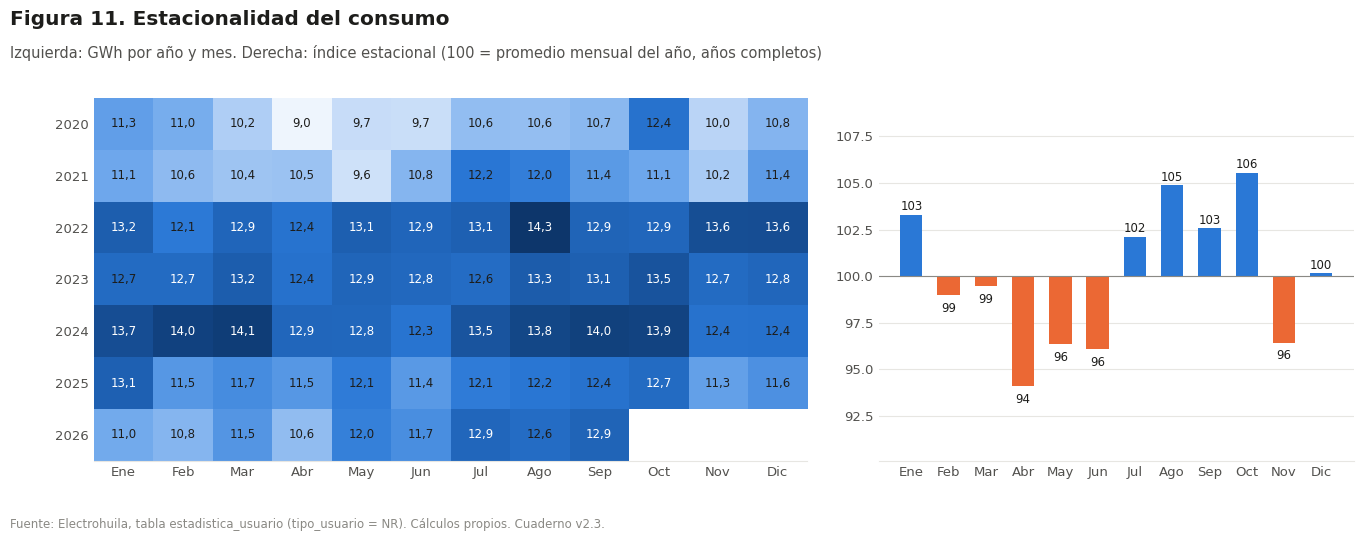

In [28]:
tabla_est = (base.groupby(['ANO', 'MES'])['TOTAL_ACTIVA'].sum() / 1e6).unstack()
tabla_est.columns = MESES_ES
indice_est = tabla_est.div(tabla_est.mean(axis=1), axis=0) * 100      # 100 = promedio mensual del año
indice_est = indice_est.loc[[a for a in indice_est.index if anual.loc[a, 'MESES'] == 12]]
perfil = indice_est.mean()

fig, (ax1, ax2) = nueva_figura('Estacionalidad del consumo',
                               'Izquierda: GWh por año y mes. Derecha: índice estacional (100 = promedio mensual del año, años completos)',
                               ancho=14, alto=5.2, columnas=2, gridspec_kw={'width_ratios': [1.5, 1]})
fig.subplots_adjust(wspace=0.12)
im = ax1.imshow(tabla_est.values, cmap=SECUENCIAL, aspect='auto')
ax1.set_xticks(range(12), MESES_ES); ax1.set_yticks(range(len(tabla_est)), tabla_est.index); ax1.grid(False)
umbral_txt = np.nanpercentile(tabla_est.values, 60)
for i in range(tabla_est.shape[0]):
    for j in range(12):
        v = tabla_est.values[i, j]
        if not np.isnan(v):
            ax1.text(j, i, fmt_es(v, 1), ha='center', va='center', fontsize=8.5, color='white' if v > umbral_txt else TINTA)
ax2.bar(MESES_ES, perfil - 100, bottom=100, color=[AZUL if v >= 100 else NARANJA for v in perfil], width=0.6)
ax2.axhline(100, color=TINTA_3, lw=0.8)
for i, v in enumerate(perfil):
    ax2.annotate(f'{v:.0f}', (i, v), xytext=(0, 3 if v >= 100 else -12), textcoords='offset points', ha='center', fontsize=8.5)
ax2.set_ylim(perfil.min() - 4, perfil.max() + 4)
guardar(fig, 'estacionalidad')

**Interpretación — estacionalidad**

- **Qué muestra:** el mapa de calor año × mes y el índice estacional promedio de los años completos (100 = mes promedio del año).
- **Hallazgos:**
  - La estacionalidad es moderada.
  - Julio–octubre están 2–6 % por encima del promedio anual (octubre es el máximo, con 106) y enero, 3 % por encima.
  - Abril–junio y noviembre están 4–6 % por debajo (abril es el mínimo, con 94).
  - El mapa también muestra el cambio de nivel de 2022 (filas más oscuras) y el menor nivel de 2025.


### 6.5 Composición del consumo: Municipio de Neiva, otros grandes usuarios y resto

Los “10 grandes” son los 10 usuarios con mayor consumo acumulado 2020–2026, sin contar el Municipio de Neiva.

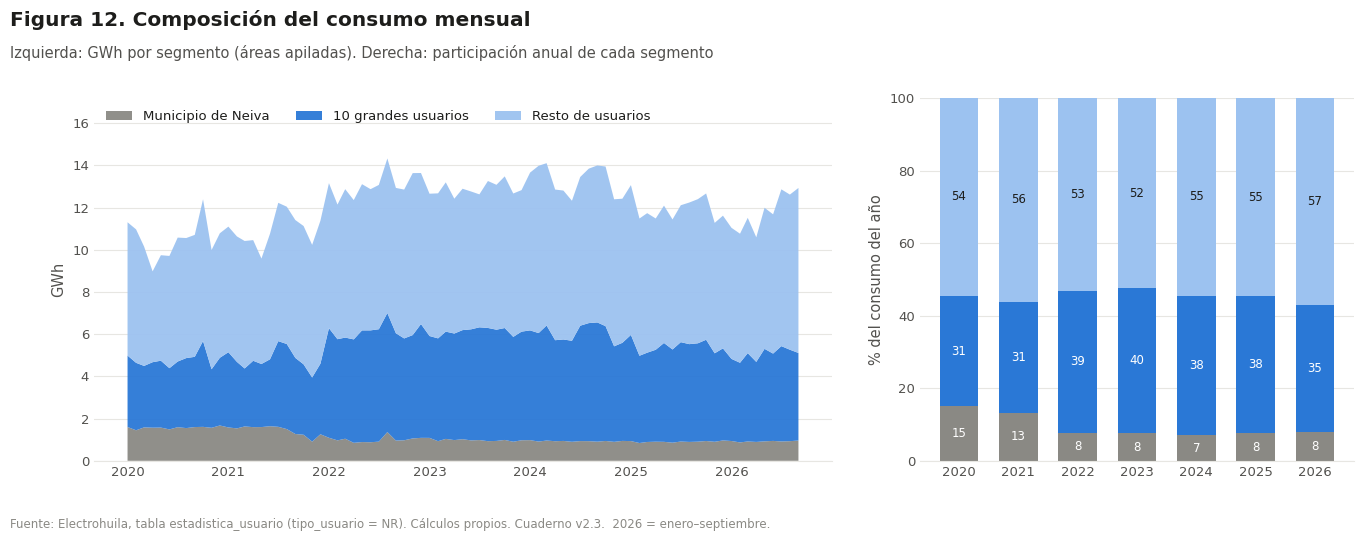

SEGMENTO,Municipio de Neiva,10 grandes usuarios,Resto de usuarios
AÑO,,,
2020,18.85,38.48,68.54
2021,17.36,40.19,73.82
2022,12.08,61.46,83.46
2023,11.75,61.67,81.14
2024,11.18,61.51,87.11
2025,10.85,54.22,78.55
2026,8.29,37.17,60.54


In [29]:
COD_NEIVA = usuarios.loc[usuarios['CUENTAS'].idxmax(), 'CODIGO']
TOP10_SIN_NEIVA = [c for c in usuarios['CODIGO'] if c != COD_NEIVA][:10]
segmento = np.select([base['CODIGO_USUARIO'] == COD_NEIVA, base['CODIGO_USUARIO'].isin(TOP10_SIN_NEIVA)],
                     ['Municipio de Neiva', '10 grandes usuarios'], 'Resto de usuarios')
comp_seg = base.assign(SEGMENTO=segmento).pivot_table(index='FECHA', columns='SEGMENTO', values='TOTAL_ACTIVA', aggfunc='sum') / 1e6
comp_seg = comp_seg[['Municipio de Neiva', '10 grandes usuarios', 'Resto de usuarios']]
COLOR_SEG = {'Municipio de Neiva': TINTA_3, '10 grandes usuarios': AZUL, 'Resto de usuarios': '#9cc2f0'}

fig, (ax1, ax2) = nueva_figura('Composición del consumo mensual',
                               'Izquierda: GWh por segmento (áreas apiladas). Derecha: participación anual de cada segmento',
                               ancho=14, alto=5.2, columnas=2, gridspec_kw={'width_ratios': [1.7, 1]})
fig.subplots_adjust(wspace=0.15)
ax1.stackplot(comp_seg.index, comp_seg.T.values, colors=[COLOR_SEG[c] for c in comp_seg], labels=comp_seg.columns, alpha=0.95)
ax1.set_ylabel('GWh'); eje_fechas(ax1); ax1.legend(loc='upper left', ncol=3)
ax1.set_ylim(0, comp_seg.sum(axis=1).max() * 1.2)
part_seg = comp_seg.groupby(comp_seg.index.year).sum()
part_seg = part_seg.div(part_seg.sum(axis=1), axis=0) * 100
abajo = np.zeros(len(part_seg))
for c in part_seg:
    ax2.bar(part_seg.index.astype(str), part_seg[c], bottom=abajo, color=COLOR_SEG[c], width=0.65)
    for i, v in enumerate(part_seg[c]):
        ax2.text(i, abajo[i] + v / 2, f'{v:.0f}', ha='center', va='center', fontsize=8.5,
                 color='white' if c != 'Resto de usuarios' else TINTA)
    abajo += part_seg[c].values
ax2.set_ylim(0, 100); ax2.set_ylabel('% del consumo del año')
guardar(fig, 'composicion_consumo', nota='2026 = enero–septiembre.')
comp_anual_seg = comp_seg.groupby(comp_seg.index.year).sum()
comp_anual_seg.index.name = 'AÑO'
comp_anual_seg.round(2)

**Interpretación — composición del consumo**

- **Qué muestra:** el consumo mensual dividido en Municipio de Neiva, los 10 usuarios más grandes y el resto, y su participación anual.
- **Hallazgos:**
  - El **Municipio de Neiva** pasa de 15 % del consumo en 2020 a 7–8 % desde 2022, por la caída de su nivel en 2021 (de 18,9 a 12,1 GWh anuales).
  - Los **10 grandes** suben de 31 % a 39–40 % en 2022–2023, con la entrada de Kyndryl y de la cuenta de la Fiduciaria Davivienda, y bajan a 38 % en 2025 y 35 % en 2026.
  - El **resto de usuarios** (≈ 140) aporta de forma estable entre 52 % y 57 %.
  - En la caída de 2025 frente a 2024 (−16,2 GWh), el resto restó 8,6 GWh, los 10 grandes 7,3 GWh y el municipio 0,3 GWh.


### 6.6 Consumo por cohorte de primera aparición

Cada usuario se asigna al año en que aparece por primera vez. La cohorte 2020 incluye a todos los que ya estaban en enero de 2020.

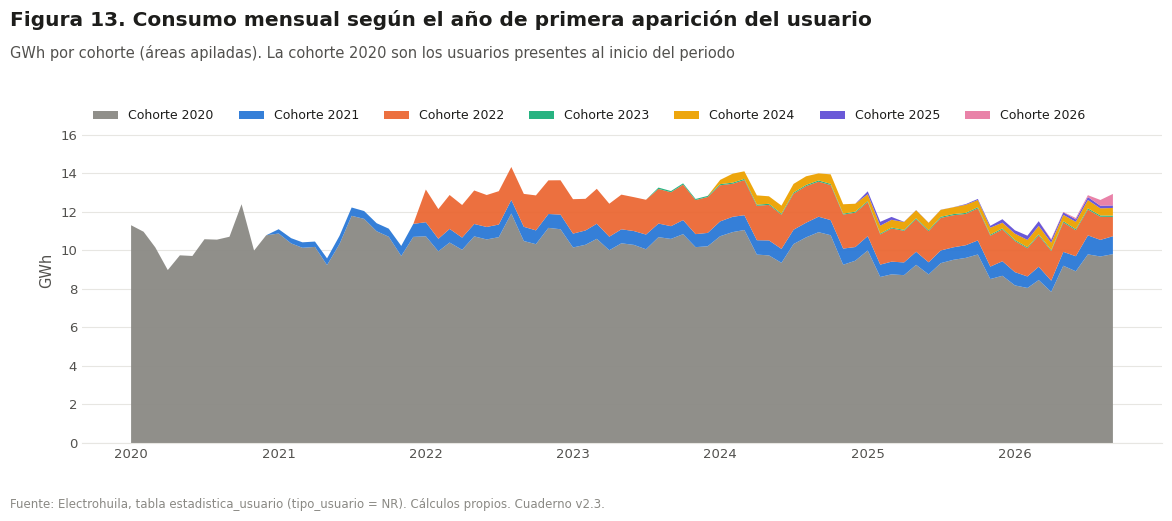

COHORTE,2020,2021,2022,2023,2024,2025,2026,Total
AÑO,,,,,,,,
2020,125.88,0.00,0.00,0.00,0.00,0.00,0.00,125.88
2021,126.67,4.70,0.00,0.00,0.00,0.00,0.00,131.37
2022,128.09,8.31,20.59,0.00,0.00,0.00,0.00,156.99
2023,124.27,8.63,21.35,0.31,0.00,0.00,0.00,154.56
2024,123.07,9.22,21.77,0.71,5.02,0.00,0.00,159.79
2025,109.52,8.11,19.90,0.65,4.54,0.91,0.00,143.62
2026,79.93,6.84,12.65,0.54,3.45,1.46,1.13,106.00


In [30]:
cohorte = base.groupby('CODIGO_USUARIO')['ANO'].min().rename('COHORTE')
coh = (base.join(cohorte, on='CODIGO_USUARIO').pivot_table(index='FECHA', columns='COHORTE', values='TOTAL_ACTIVA', aggfunc='sum')
       .fillna(0) / 1e6)
colores_coh = [TINTA_3, AZUL, NARANJA, AQUA, AMARILLO, VIOLETA, MAGENTA][:coh.shape[1]]
fig, ax = nueva_figura('Consumo mensual según el año de primera aparición del usuario',
                       'GWh por cohorte (áreas apiladas). La cohorte 2020 son los usuarios presentes al inicio del periodo',
                       alto=5)
ax.stackplot(coh.index, coh.T.values, colors=colores_coh, labels=[f'Cohorte {c}' for c in coh.columns], alpha=0.95)
ax.set_ylabel('GWh'); eje_fechas(ax); ax.set_ylim(0, coh.sum(axis=1).max() * 1.25)
ax.legend(loc='upper left', ncol=7, fontsize=9)
guardar(fig, 'consumo_por_cohorte')
coh_anual = coh.groupby(coh.index.year).sum()
coh_anual['Total'] = coh_anual.sum(axis=1)
coh_anual.index.name = 'AÑO'
coh_anual.round(2)

**Interpretación — consumo por cohorte**

- **Qué muestra:** el consumo de cada mes según el año en que apareció cada usuario.
- **Hallazgos:**
  - La **cohorte 2020** (usuarios presentes al inicio) se mantiene entre 123 y 128 GWh hasta 2024 y cae a 109,5 GWh en 2025 (−13,6 GWh): explica la mayor parte de la caída de ese año.
  - La **cohorte 2022** (Kyndryl, la cuenta de la Fiduciaria Davivienda y otros) aporta ≈ 20–22 GWh por año desde su entrada.
  - Las cohortes 2021 (≈ 8–9 GWh) y 2024 (≈ 5 GWh) son estables; 2023, 2025 y 2026 son pequeñas (≤ 1,5 GWh).


### 6.7 Perfiles estacionales de consumo por usuario (k-means)

Se aplica el método de perfiles de demanda: (1) organizar los datos como una matriz donde cada fila es un perfil, (2) **dividir cada fila por su máximo** para que el perfil sea adimensional y se compare la *forma* y no el tamaño, (3) elegir el número de grupos con el **coeficiente de silueta**, (4) agrupar con **k-means** y graficar los centroides, y (5) cruzar el grupo de cada perfil con una variable de calendario para ver cuándo aparece cada patrón.

Aquí cada perfil es el consumo de **un usuario en un año completo** (12 meses, 2020–2025). Solo se usan usuario-año con los 12 meses registrados y consumo positivo.

Perfiles usuario-año: 756 posibles | 688 con los 12 meses y consumo > 0 | 137 usuarios | años 2020–2025


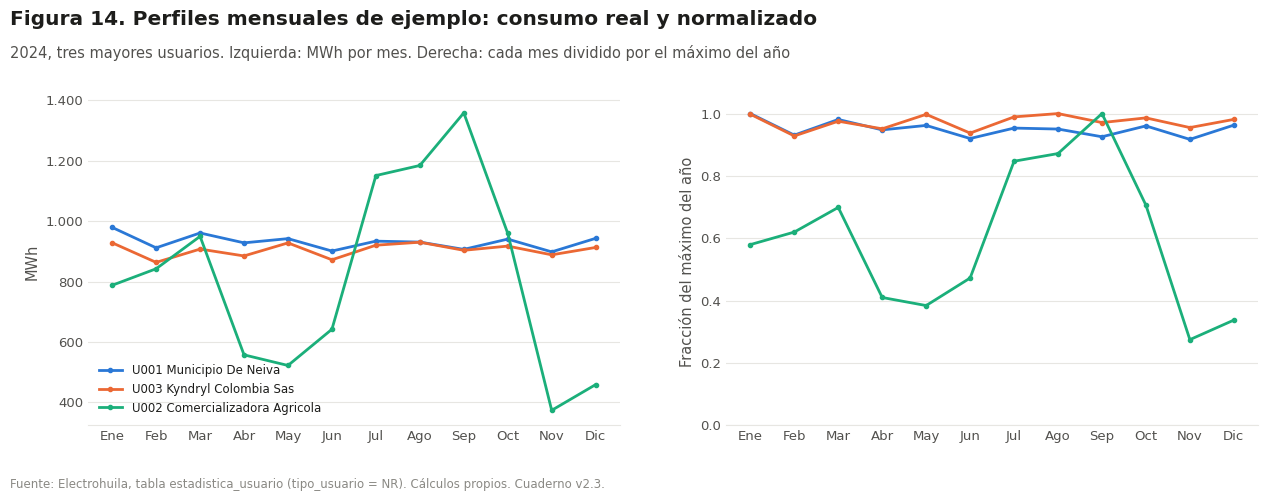

In [31]:
# -----------------------------------------------------------------------------
# 6.7.1 Organización de los datos: una fila por usuario-año, una columna por mes
# -----------------------------------------------------------------------------
anios_completos = [a for a, m in base.groupby('ANO')['MES'].nunique().items() if m == 12]
perfiles = (base[base['ANO'].isin(anios_completos)]
            .pivot_table(index=['CODIGO_USUARIO', 'ANO'], columns='MES', values='TOTAL_ACTIVA', aggfunc='sum'))
perfiles.columns = MESES_ES
n_total = len(perfiles)
perfiles = perfiles.dropna()                       # solo usuario-año con los 12 meses registrados
perfiles = perfiles[perfiles.max(axis=1) > 0]      # se descartan años completos en cero
print(f'Perfiles usuario-año: {n_total} posibles | {len(perfiles)} con los 12 meses y consumo > 0 '
      f'| {perfiles.index.get_level_values(0).nunique()} usuarios | años {anios_completos[0]}–{anios_completos[-1]}')

# Normalización: cada mes dividido por el máximo de su fila (0–1). Así se compara la forma, no el tamaño.
perfiles_norm = perfiles.div(perfiles.max(axis=1), axis=0)

# Ejemplos: los tres mayores usuarios de 2024, antes y después de normalizar
ejemplos = perfiles.xs(2024, level='ANO').sum(axis=1).nlargest(3).index
fig, (ax1, ax2) = nueva_figura('Perfiles mensuales de ejemplo: consumo real y normalizado',
                               '2024, tres mayores usuarios. Izquierda: MWh por mes. Derecha: cada mes dividido por el máximo del año',
                               ancho=13, alto=4.8, columnas=2)
fig.subplots_adjust(wspace=0.2)
for c, color in zip(ejemplos, [AZUL, NARANJA, AQUA]):
    ax1.plot(MESES_ES, perfiles.loc[(c, 2024)] / 1e3, '.-', color=color, label=f'{c} {ETIQUETA[c][:26].title()}')
    ax2.plot(MESES_ES, perfiles_norm.loc[(c, 2024)], '.-', color=color)
eje_miles(ax1); ax1.set_ylabel('MWh'); ax1.legend(loc='lower left', fontsize=8.5)
ax2.set_ylim(0, 1.05); ax2.set_ylabel('Fracción del máximo del año')
guardar(fig, 'perfiles_ejemplo')

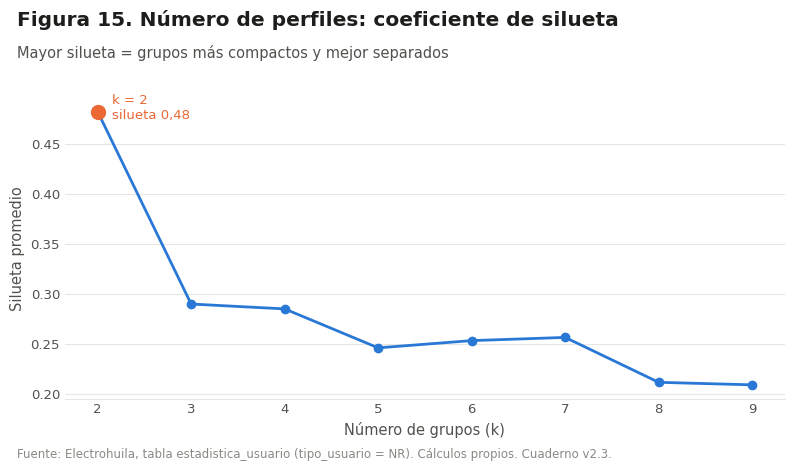

,2,3,4,5,6,7,8,9
Silueta,0.48,0.29,0.28,0.25,0.25,0.26,0.21,0.21


In [32]:
# -----------------------------------------------------------------------------
# 6.7.2 Número de perfiles: coeficiente de silueta para k = 2…9
# -----------------------------------------------------------------------------
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K = list(range(2, 10))
modelos = {k: KMeans(n_clusters=k, n_init=20, random_state=42).fit(perfiles_norm) for k in K}
siluetas = pd.Series({k: silhouette_score(perfiles_norm, modelos[k].labels_) for k in K}, name='Silueta')
k_opt = int(siluetas.idxmax())

fig, ax = nueva_figura('Número de perfiles: coeficiente de silueta',
                       'Mayor silueta = grupos más compactos y mejor separados', ancho=8, alto=4.5)
ax.plot(siluetas.index, siluetas.values, 'o-', color=AZUL)
ax.plot(k_opt, siluetas[k_opt], 'o', color=NARANJA, ms=10)
ax.annotate(f'k = {k_opt}\nsilueta {siluetas[k_opt]:.2f}'.replace('.', ','), (k_opt, siluetas[k_opt]),
            xytext=(10, -5), textcoords='offset points', fontsize=9.5, color=NARANJA)
ax.set_xlabel('Número de grupos (k)'); ax.set_ylabel('Silueta promedio'); ax.set_xticks(K)
guardar(fig, 'perfiles_silueta')
siluetas.round(3).to_frame().T

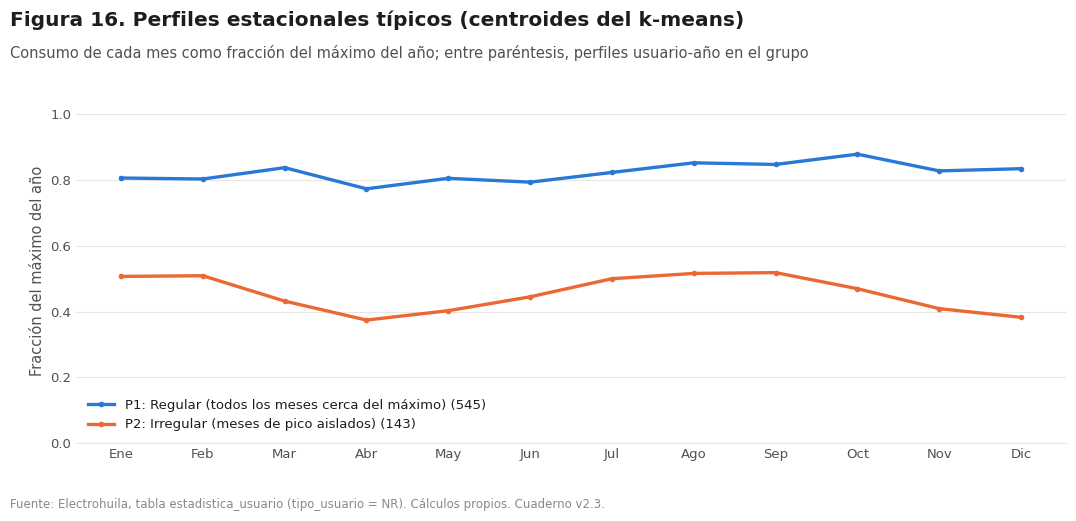

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
P1,0.81,0.80,0.84,0.77,0.81,0.79,0.82,0.85,0.85,0.88,0.83,0.83
P2,0.51,0.51,0.43,0.37,0.40,0.44,0.50,0.52,0.52,0.47,0.41,0.38


In [33]:
# -----------------------------------------------------------------------------
# 6.7.3 Perfiles óptimos: centroides del k-means con k = k_opt
# -----------------------------------------------------------------------------
km = modelos[k_opt]
centroides = pd.DataFrame(km.cluster_centers_, columns=MESES_ES)

def nombre_perfil(c):
    """Nombre descriptivo del centroide según el nivel medio de sus meses frente al máximo del año."""
    if c.mean() >= 0.7:
        return 'Regular (todos los meses cerca del máximo)'
    return 'Irregular (meses de pico aislados)'

# Se ordenan los grupos de más a menos perfiles y se les da un nombre legible
orden_g = pd.Series(km.labels_).value_counts().index
mapa_g = {g: f'P{i + 1}' for i, g in enumerate(orden_g)}
centroides.index = [mapa_g[g] for g in range(k_opt)]
centroides = centroides.loc[sorted(centroides.index)]
NOMBRE_PERFIL = {p: f'{p}: {nombre_perfil(centroides.loc[p])}' for p in centroides.index}

perfiles_res = perfiles.assign(PERFIL=[mapa_g[g] for g in km.labels_],
                               CONSUMO_ANUAL_KWH=perfiles.sum(axis=1)).reset_index()
COLOR_P = dict(zip(centroides.index, [AZUL, NARANJA, AQUA, AMARILLO, VIOLETA, MAGENTA, VERDE, ROJO, TINTA_3]))

fig, ax = nueva_figura('Perfiles estacionales típicos (centroides del k-means)',
                       'Consumo de cada mes como fracción del máximo del año; entre paréntesis, perfiles usuario-año en el grupo',
                       ancho=11, alto=5)
for p in centroides.index:
    n = (perfiles_res['PERFIL'] == p).sum()
    ax.plot(MESES_ES, centroides.loc[p], '.-', lw=2.4, color=COLOR_P[p], label=f'{NOMBRE_PERFIL[p]} ({n})')
ax.set_ylim(0, 1.05); ax.set_ylabel('Fracción del máximo del año'); ax.legend(loc='lower left')
guardar(fig, 'perfiles_centroides')
centroides.round(2)

Usuarios con 3 años completos o más: 128 | mantienen el mismo perfil todos sus años: 73


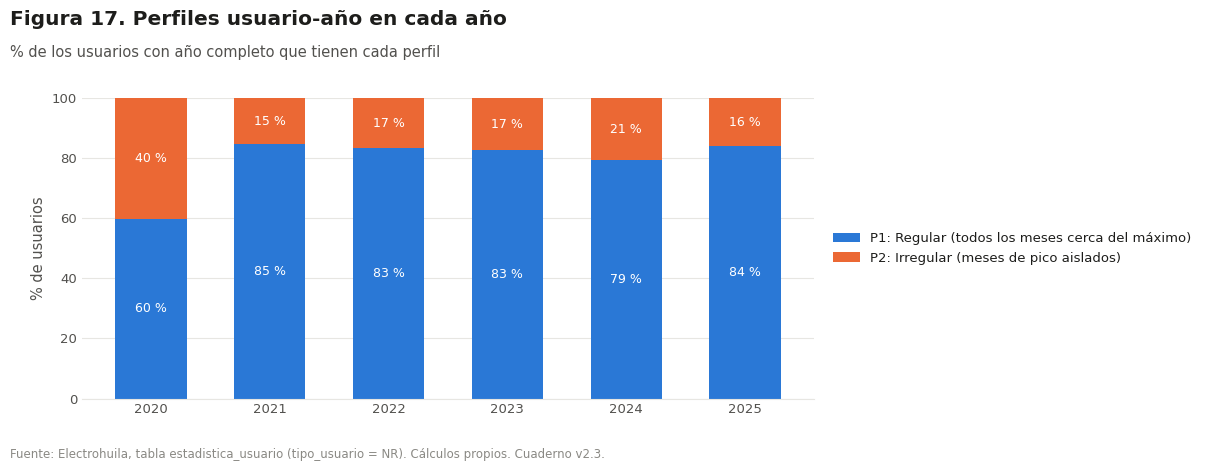

,PERFILES_USUARIO_AÑO,USUARIOS,CONSUMO_GWH,%_CONSUMO,AMPLITUD_CENTROIDE,MES_PICO
P1: Regular (todos los meses cerca del máximo),545,124,781.08,90.81,0.11,Oct
P2: Irregular (meses de pico aislados),143,69,79.05,9.19,0.14,Sep


,P1: Regular (todos los meses cerca del máximo),P2: Irregular (meses de pico aislados)
Año,,
2020,62,42
2021,93,17
2022,105,21
2023,100,21
2024,96,25
2025,89,17


,Usuario,Perfil más frecuente,Años en ese perfil / años completos
CODIGO,,,
U001,MUNICIPIO DE NEIVA,P1: Regular (todos los meses cerca del máximo),6 / 6
U002,COMERCIALIZADORA AGRICOLA ASOJ,P1: Regular (todos los meses cerca del máximo),4 / 6
U003,KYNDRYL COLOMBIA SAS,P1: Regular (todos los meses cerca del máximo),4 / 4
U004,PISCICOLA NEW YORK S.A.,P1: Regular (todos los meses cerca del máximo),5 / 6
U005,FIDUCIARIA DAVIVIENDA S.A.,P1: Regular (todos los meses cerca del máximo),4 / 4
U006,CI PISCICOLA BOTERO S.A.,P1: Regular (todos los meses cerca del máximo),6 / 6
U007,ASOC.USU.DIST.ADE.TIE.PQA.ESC.,P1: Regular (todos los meses cerca del máximo),6 / 6
U008,CAJA DE COMPENSACION FAMILIAR,P1: Regular (todos los meses cerca del máximo),6 / 6
U009,E.S.E. HOSPITAL UNIVERSITARIO,P1: Regular (todos los meses cerca del máximo),5 / 6


In [34]:
# -----------------------------------------------------------------------------
# 6.7.4 ¿Cuándo y en quién aparece cada perfil?
# -----------------------------------------------------------------------------
# a) Frecuencia de cada perfil por año (equivale a cruzar el grupo con el día de la semana en perfiles diarios)
perfil_por_anio = pd.crosstab(perfiles_res['ANO'], perfiles_res['PERFIL'])
perfil_por_anio.columns = [NOMBRE_PERFIL[p] for p in perfil_por_anio.columns]
perfil_por_anio.index.name = 'Año'

# b) Tamaño y peso en el consumo de cada perfil
resumen_perfiles = (perfiles_res.groupby('PERFIL')
                    .agg(PERFILES_USUARIO_AÑO=('CODIGO_USUARIO', 'size'), USUARIOS=('CODIGO_USUARIO', 'nunique'),
                         CONSUMO_GWH=('CONSUMO_ANUAL_KWH', lambda s: s.sum() / 1e6)))
resumen_perfiles['%_CONSUMO'] = resumen_perfiles['CONSUMO_GWH'] / resumen_perfiles['CONSUMO_GWH'].sum() * 100
resumen_perfiles['AMPLITUD_CENTROIDE'] = centroides.max(axis=1) - centroides.min(axis=1)
resumen_perfiles['MES_PICO'] = centroides.idxmax(axis=1)
resumen_perfiles.index = [NOMBRE_PERFIL[p] for p in resumen_perfiles.index]

# c) Estabilidad: ¿el usuario mantiene el mismo perfil todos sus años?
n_perfiles_usuario = perfiles_res.groupby('CODIGO_USUARIO')['PERFIL'].nunique()
anios_usuario_perf = perfiles_res.groupby('CODIGO_USUARIO')['ANO'].nunique()
estables_perfil = n_perfiles_usuario[(anios_usuario_perf >= 3) & (n_perfiles_usuario == 1)]
print(f'Usuarios con 3 años completos o más: {(anios_usuario_perf >= 3).sum()} | '
      f'mantienen el mismo perfil todos sus años: {len(estables_perfil)}')

# d) Perfil más frecuente de los 15 mayores usuarios (por consumo acumulado 2020–2026)
TOP15_TOTAL = usuarios['CODIGO'].head(15)
perfil_top = (perfiles_res[perfiles_res['CODIGO_USUARIO'].isin(TOP15_TOTAL)]
              .groupby('CODIGO_USUARIO')['PERFIL'].agg(lambda s: s.value_counts().idxmax()))
perfil_top = pd.DataFrame({'Usuario': perfil_top.index.map(ETIQUETA), 'Perfil más frecuente': perfil_top.map(NOMBRE_PERFIL),
                           'Años en ese perfil / años completos': [
                               f"{(perfiles_res[(perfiles_res.CODIGO_USUARIO == c)].PERFIL == p).sum()} / "
                               f"{(perfiles_res.CODIGO_USUARIO == c).sum()}" for c, p in perfil_top.items()]}
                          ).reindex(TOP15_TOTAL).dropna()

exportar_excel(DIR_TAB / 'perfiles_estacionales.xlsx', [
    dict(hoja='Silueta', tabla=siluetas.rename_axis('k').reset_index(), titulo='Coeficiente de silueta por número de grupos',
         descripcion='Perfiles usuario-año normalizados por su máximo; k-means con 20 inicializaciones.'),
    dict(hoja='Centroides', tabla=centroides.rename(index=NOMBRE_PERFIL).rename_axis('Perfil').reset_index(),
         titulo='Perfil típico de cada grupo (fracción del máximo del año)', descripcion='Centroides del k-means.'),
    dict(hoja='Resumen perfiles', tabla=resumen_perfiles.rename_axis('Perfil').reset_index(),
         titulo='Tamaño y consumo de cada perfil', descripcion=f'Años completos {anios_completos[0]}–{anios_completos[-1]}.'),
    dict(hoja='Perfil por año', tabla=perfil_por_anio.reset_index(), titulo='Perfiles usuario-año por año',
         descripcion='Número de usuarios con cada perfil en cada año.'),
    dict(hoja='Perfil por usuario-año', tabla=perfiles_res.assign(Usuario=perfiles_res['CODIGO_USUARIO'].map(ETIQUETA),
                                                                  PERFIL=perfiles_res['PERFIL'].map(NOMBRE_PERFIL)),
         titulo='Perfil asignado a cada usuario en cada año', descripcion='Consumo mensual en kWh.'),
], titulo_libro='Perfiles estacionales de consumo (k-means)')
# Figura: participación de cada perfil por año
part_anio = perfil_por_anio.div(perfil_por_anio.sum(axis=1), axis=0) * 100
fig, ax = nueva_figura('Perfiles usuario-año en cada año', '% de los usuarios con año completo que tienen cada perfil',
                       ancho=12, alto=4.5)
fig.subplots_adjust(right=0.68)
abajo = np.zeros(len(part_anio))
for col, p in zip(part_anio.columns, centroides.index):
    ax.bar(part_anio.index.astype(str), part_anio[col], bottom=abajo, color=COLOR_P[p], width=0.6, label=col)
    for i, v in enumerate(part_anio[col]):
        ax.text(i, abajo[i] + v / 2, f'{v:.0f} %', ha='center', va='center', fontsize=9, color='white')
    abajo += part_anio[col].values
ax.set_ylim(0, 100); ax.set_ylabel('% de usuarios'); ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
guardar(fig, 'perfiles_por_anio')

display(resumen_perfiles.round(2))
display(perfil_por_anio)
perfil_top

**Interpretación — perfiles estacionales**

- **Qué muestran:** perfiles de ejemplo antes y después de normalizar, la silueta para elegir el número de grupos, los centroides del k-means y la frecuencia de cada perfil por año.
- **Hallazgos:**
  - Se analizan 688 perfiles usuario-año (137 usuarios, 2020–2025) con los 12 meses registrados.
  - La silueta es máxima con **k = 2** (0,48, frente a 0,29 o menos para k ≥ 3): hay dos patrones claramente separados.
  - **P1 Regular** reúne 545 perfiles (79 %) y el 90,8 % del consumo. En promedio, cada mes está al 77–88 % del máximo del año: son usuarios con operación continua, como el Municipio de Neiva y Kyndryl en la figura de ejemplo.
  - **P2 Irregular** reúne 143 perfiles (21 %) y solo el 9,2 % del consumo. Sus meses están en promedio al 37–52 % del máximo del año: uno o pocos meses de pico y el resto muy por debajo. Un ejemplo es la Comercializadora Agrícola Asoj en 2024, con picos en julio–septiembre.
  - **2020 es atípico:** el 40 % de los usuarios tuvo un año irregular por el aislamiento de la pandemia, frente a 15–21 % entre 2021 y 2025.
  - De los 128 usuarios con 3 años completos o más, 73 (57 %) mantienen el mismo perfil todos los años. Los 15 mayores usuarios son regulares en la mayoría de sus años.


## 7. Distribución del consumo

### 7.1 Consumo promedio mensual por cuenta

In [35]:
por_cuenta = base.groupby('CUENTA').agg(PROMEDIO_MENSUAL=('TOTAL_ACTIVA', 'mean'), MAXIMO_MENSUAL=('TOTAL_ACTIVA', 'max'),
                                        MESES=('FECHA', 'nunique'), USUARIO=('CODIGO_USUARIO', 'last'))
TRAMOS = [-1, 0, 1_000, 10_000, 100_000, np.inf]
ETIQ_TRAMOS = ['0 (sin consumo)', '1 – 1.000', '1.001 – 10.000', '10.001 – 100.000', 'Más de 100.000']
tramos_c = pd.cut(por_cuenta['PROMEDIO_MENSUAL'], TRAMOS, labels=ETIQ_TRAMOS)
es_neiva = por_cuenta['USUARIO'] == COD_NEIVA
distribucion = pd.DataFrame({'Cuentas': tramos_c.value_counts().sort_index(),
                             'De ellas, Municipio de Neiva': tramos_c[es_neiva].value_counts().sort_index()})
distribucion['% cuentas'] = distribucion['Cuentas'] / distribucion['Cuentas'].sum() * 100
distribucion['% consumo'] = (base.groupby(base['CUENTA'].map(tramos_c), observed=False)['TOTAL_ACTIVA'].sum()
                             .reindex(distribucion.index) / base['TOTAL_ACTIVA'].sum() * 100)
distribucion.index.name = f'Consumo promedio ({UNIDAD}/mes)'
distribucion

,Cuentas,"De ellas, Municipio de Neiva",% cuentas,% consumo
Consumo promedio (kWh/mes),,,,
0 (sin consumo),17,4,2.43,0.00
1 – 1.000,381,377,54.43,0.98
1.001 – 10.000,125,94,17.86,2.45
10.001 – 100.000,142,2,20.29,39.69
Más de 100.000,35,1,5.00,56.88


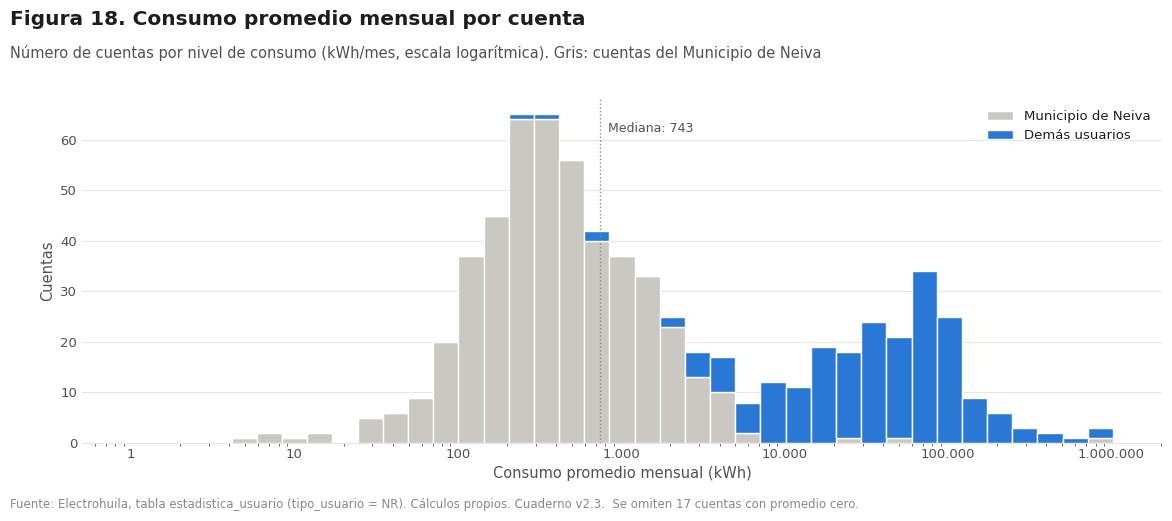

In [36]:
fig, ax = nueva_figura('Consumo promedio mensual por cuenta',
                       f'Número de cuentas por nivel de consumo ({UNIDAD}/mes, escala logarítmica). Gris: cuentas del Municipio de Neiva',
                       alto=5)
valores = por_cuenta.loc[por_cuenta['PROMEDIO_MENSUAL'] > 0]
bins = np.logspace(0, np.log10(valores['PROMEDIO_MENSUAL'].max()) + 0.1, 40)
ax.hist([valores.loc[valores['USUARIO'] == COD_NEIVA, 'PROMEDIO_MENSUAL'], valores.loc[valores['USUARIO'] != COD_NEIVA, 'PROMEDIO_MENSUAL']],
        bins=bins, stacked=True, color=[GRIS_SUAVE, AZUL], edgecolor='white', label=['Municipio de Neiva', 'Demás usuarios'])
ax.set_xscale('log'); ax.xaxis.set_major_formatter(mtick.FuncFormatter(miles))
med = valores['PROMEDIO_MENSUAL'].median()
ax.axvline(med, color=TINTA_3, lw=1, ls=':')
ax.annotate(f'Mediana: {miles(med)}', (med, ax.get_ylim()[1] * 0.9), xytext=(6, 0), textcoords='offset points', color=TINTA_2, fontsize=9)
ax.set_xlabel(f'Consumo promedio mensual ({UNIDAD})'); ax.set_ylabel('Cuentas'); ax.legend(loc='upper right')
guardar(fig, 'distribucion_consumo_cuenta', nota=f'Se omiten {int((por_cuenta["PROMEDIO_MENSUAL"] == 0).sum())} cuentas con promedio cero.')

**Interpretación — distribución por cuenta**

- **Qué muestran:** las cuentas por nivel de consumo promedio mensual (tabla) y su distribución en escala logarítmica, separando las del Municipio de Neiva (figura).
- **Hallazgos:**
  - La distribución tiene **dos poblaciones**. Las cuentas pequeñas, de 1 a 1.000 kWh/mes, son 381, y **377 son del Municipio de Neiva**. Las cuentas de los demás usuarios se agrupan entre 10.000 y 300.000 kWh/mes.
  - Las 35 cuentas de más de 100.000 kWh/mes (5 %) generan el 56,9 % de la energía; con las del tramo 10.001–100.000 suman 177 cuentas y el 96,6 %.
  - La mediana general (743 kWh/mes) no representa a ningún grupo: está entre las dos poblaciones.


### 7.2 Distribución del consumo por usuario en cada año

Para comparar 2026 (9 meses) con los años completos se usa el **consumo promedio mensual** de cada usuario en el año.

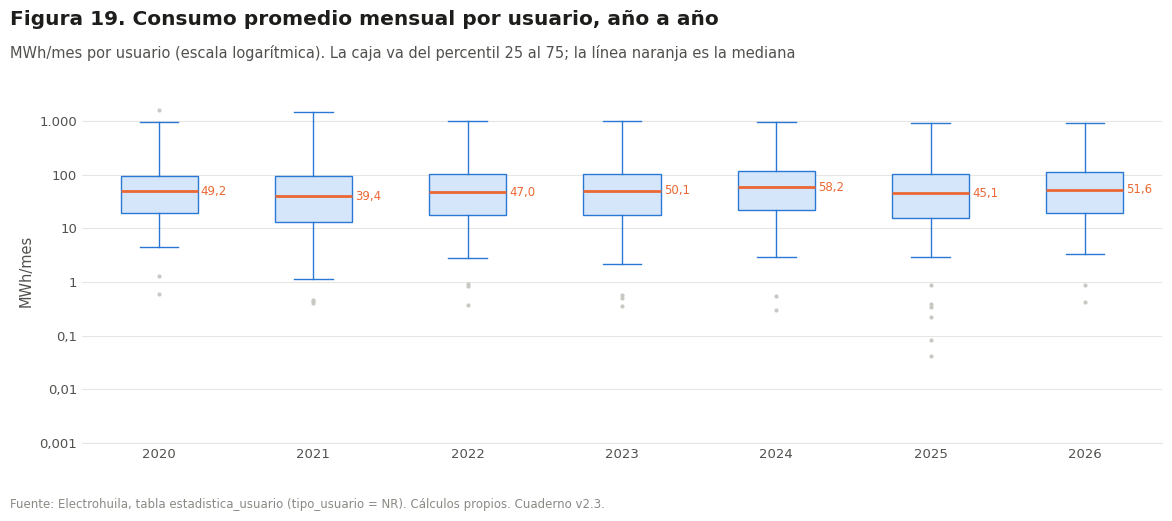

,Usuarios,P25,Mediana,P75,P90,Máximo
ANO,,,,,,
2020,110,19.32,49.16,94.94,178.78,"1,571.15"
2021,128,13.27,39.43,92.90,181.40,"1,446.87"
2022,131,17.38,47.01,100.30,212.32,"1,006.29"
2023,130,17.46,50.08,103.89,193.52,979.03
2024,124,22.05,58.24,116.20,223.37,931.28
2025,125,15.56,45.09,102.71,213.79,904.38
2026,116,19.46,51.64,113.58,214.47,921.37


In [37]:
meses_anio = base.groupby('ANO')['MES'].nunique()
prom_u_anio = base.groupby(['ANO', 'CODIGO_USUARIO'])['TOTAL_ACTIVA'].sum().reset_index()
prom_u_anio['MWH_MES'] = prom_u_anio['TOTAL_ACTIVA'] / prom_u_anio['ANO'].map(meses_anio) / 1e3
prom_u_anio = prom_u_anio[prom_u_anio['MWH_MES'] > 0]
resumen_anio = prom_u_anio.groupby('ANO')['MWH_MES'].describe(percentiles=[.25, .5, .75, .9])[['count', '25%', '50%', '75%', '90%', 'max']]
resumen_anio.columns = ['Usuarios', 'P25', 'Mediana', 'P75', 'P90', 'Máximo']
resumen_anio['Usuarios'] = resumen_anio['Usuarios'].astype(int)

fig, ax = nueva_figura('Consumo promedio mensual por usuario, año a año',
                       'MWh/mes por usuario (escala logarítmica). La caja va del percentil 25 al 75; la línea naranja es la mediana',
                       alto=5)
# La caja se calcula sobre log10 del consumo: con datos tan asimétricos, los bigotes en escala lineal no son informativos
datos = [np.log10(prom_u_anio.loc[prom_u_anio['ANO'] == a, 'MWH_MES']) for a in resumen_anio.index]
ax.boxplot(datos, widths=0.5, patch_artist=True, showfliers=True,
           medianprops=dict(color=NARANJA, lw=2), flierprops=dict(marker='o', ms=3, mfc=GRIS_SUAVE, mec='none'),
           boxprops=dict(facecolor='#d6e6fa', edgecolor=AZUL), whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
marcas = np.arange(-3, 4)
ax.set_yticks(marcas, [f'{10.0 ** m:g}'.replace('.', ',') if m < 0 else miles(10 ** m) for m in marcas])
ax.set_xticks(range(1, len(resumen_anio) + 1), resumen_anio.index.astype(str))
for i, (a, r) in enumerate(resumen_anio.iterrows(), start=1):
    ax.annotate(f"{fmt_es(r['Mediana'])}", (i + 0.27, np.log10(r['Mediana'])), va='center', fontsize=8.5, color=NARANJA)
ax.set_ylabel('MWh/mes')
guardar(fig, 'distribucion_por_usuario_anual')
resumen_anio

**Interpretación — distribución por usuario en cada año**

- **Qué muestra:** el consumo promedio mensual de cada usuario año a año (caja = 50 % central).
- **Hallazgos:**
  - El usuario mediano consumía 49,2 MWh/mes en 2020 y bajó a 39,4 en 2021. Subió hasta 58,2 en 2024, cayó a 45,1 en 2025 y se recupera a 51,6 en 2026.
  - El 50 % central está de forma estable entre ≈ 15 y ≈ 115 MWh/mes.
  - El máximo baja de 1.571 MWh/mes (2020, Municipio de Neiva) a ≈ 920 desde 2022.


## 8. Concentración y principales usuarios

Se usa la ventana de los **últimos 12 meses completos**, que refleja la base actual sin mezclar años con composición distinta.

### 8.1 Ranking, curva de Lorenz e índices de concentración

In [38]:
VENTANA = pd.date_range(ULTIMO_MES - pd.DateOffset(months=11), ULTIMO_MES, freq='MS')
ult12 = base[base['FECHA'].isin(VENTANA)]
consumo_u = ult12.groupby('CODIGO_USUARIO')['TOTAL_ACTIVA'].sum().sort_values(ascending=False)
participacion = consumo_u / consumo_u.sum() * 100
acum = participacion.cumsum()

def gini(x):
    x = np.sort(np.asarray(x, dtype=float)); n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

GINI = gini(consumo_u.values)
HHI = (participacion ** 2).sum()
N80 = int((acum < 80).sum() + 1)
indices = pd.DataFrame({'Valor': [f'{VENTANA[0]:%Y-%m} a {VENTANA[-1]:%Y-%m}', len(consumo_u), fmt_es(consumo_u.sum() / 1e6, 2),
                                  fmt_es(acum.iloc[0]), fmt_es(acum.iloc[4]), fmt_es(acum.iloc[9]), fmt_es(acum.iloc[19]),
                                  N80, f'{GINI:.2f}', f'{HHI:,.0f}']},
                       index=['Ventana', 'Usuarios con consumo', 'Consumo total (GWh)', '% del mayor usuario', '% top 5',
                              '% top 10', '% top 20', 'Usuarios que suman el 80 %', 'Índice de Gini', 'HHI (0–10.000)'])
indices

,Valor
Ventana,2025-10 a 2026-09
Usuarios con consumo,121
Consumo total (GWh),"141,57"
% del mayor usuario,"7,8"
% top 5,"28,9"
% top 10,"43,9"
% top 20,"60,3"
Usuarios que suman el 80 %,42
Índice de Gini,0.62
HHI (0–10.000),281


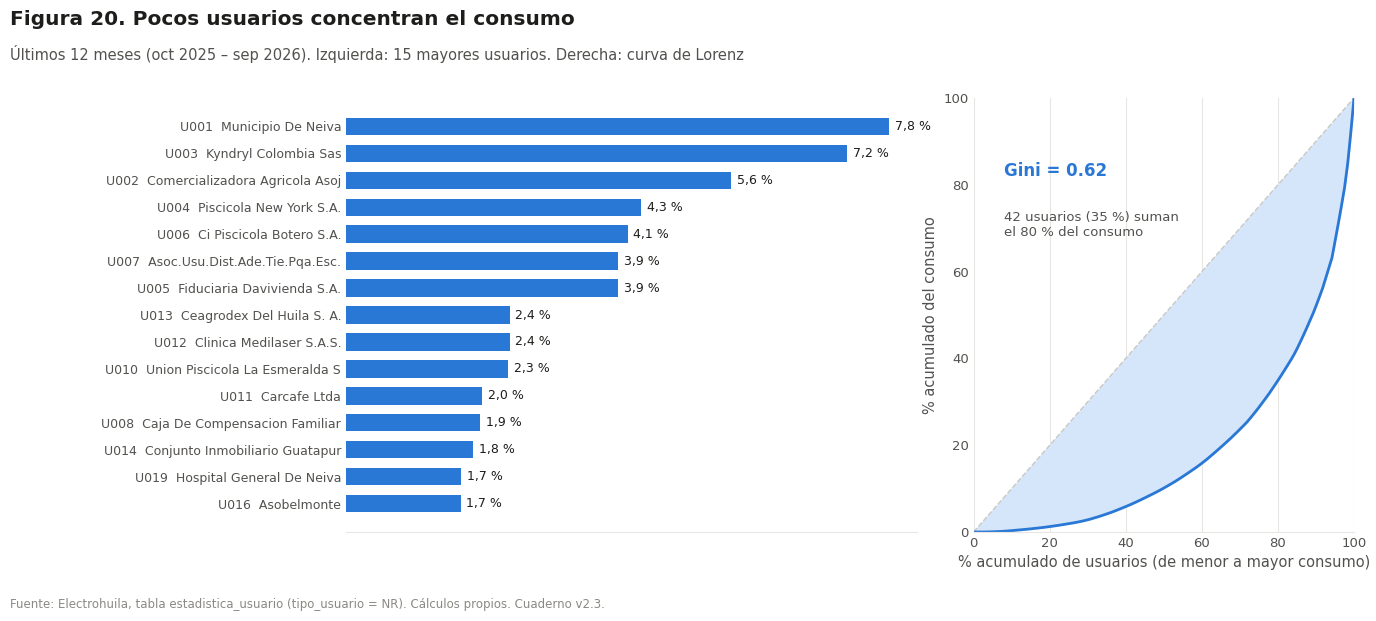

In [39]:
top = participacion.head(15)
fig, (ax1, ax2) = nueva_figura('Pocos usuarios concentran el consumo',
                               f'Últimos 12 meses ({MESES_ES[VENTANA[0].month - 1].lower()} {VENTANA[0].year} – {MESES_ES[VENTANA[-1].month - 1].lower()} {VENTANA[-1].year}). '
                               'Izquierda: 15 mayores usuarios. Derecha: curva de Lorenz',
                               ancho=14, alto=6, columnas=2, gridspec_kw={'width_ratios': [1.5, 1]})
fig.subplots_adjust(wspace=0.12, left=0.25)
y = np.arange(len(top))[::-1]
ax1.barh(y, top.values, color=AZUL, height=0.65)
ax1.set_yticks(y, [f'{c}  {ETIQUETA[c][:30].title()}' for c in top.index], fontsize=9)
ax1.grid(False); ax1.set_xticks([])
for yi, v in zip(y, top.values):
    ax1.annotate(f'{fmt_es(v)} %', (v, yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
xl = np.arange(0, len(consumo_u) + 1) / len(consumo_u) * 100
yl = np.concatenate([[0], np.cumsum(np.sort(consumo_u.values)) / consumo_u.sum() * 100])
ax2.plot([0, 100], [0, 100], color=GRIS_SUAVE, lw=1, ls='--')
ax2.fill_between(xl, yl, xl, color='#d6e6fa'); ax2.plot(xl, yl, color=AZUL)
ax2.set_xlabel('% acumulado de usuarios (de menor a mayor consumo)'); ax2.set_ylabel('% acumulado del consumo')
ax2.text(8, 82, f'Gini = {GINI:.2f}', fontsize=12, fontweight='bold', color=AZUL)
ax2.text(8, 74, f'{N80} usuarios ({N80 / len(consumo_u):.0%}) suman\nel 80 % del consumo'.replace('%)', ' %)'), fontsize=9.5, color=TINTA_2, va='top')
ax2.set_xlim(0, 100); ax2.set_ylim(0, 100); ax2.grid(axis='both')
guardar(fig, 'concentracion_consumo')

**Interpretación — concentración**

- **Qué muestra:** la participación de los 15 mayores usuarios en los últimos 12 meses (octubre 2025 – septiembre 2026, 141,6 GWh) y la curva de Lorenz.
- **Hallazgos:**
  - El mayor usuario (Municipio de Neiva) pesa 7,8 %; los 5 mayores suman 28,9 %, los 10 mayores 43,9 % y los 20 mayores 60,3 %.
  - **42 de 121 usuarios (35 %) concentran el 80 % del consumo.**
  - Gini 0,62, una desigualdad alta.
  - HHI 281, baja concentración (menos de 1.000): no hay un usuario dominante.


### 8.2 Evolución de la concentración año a año

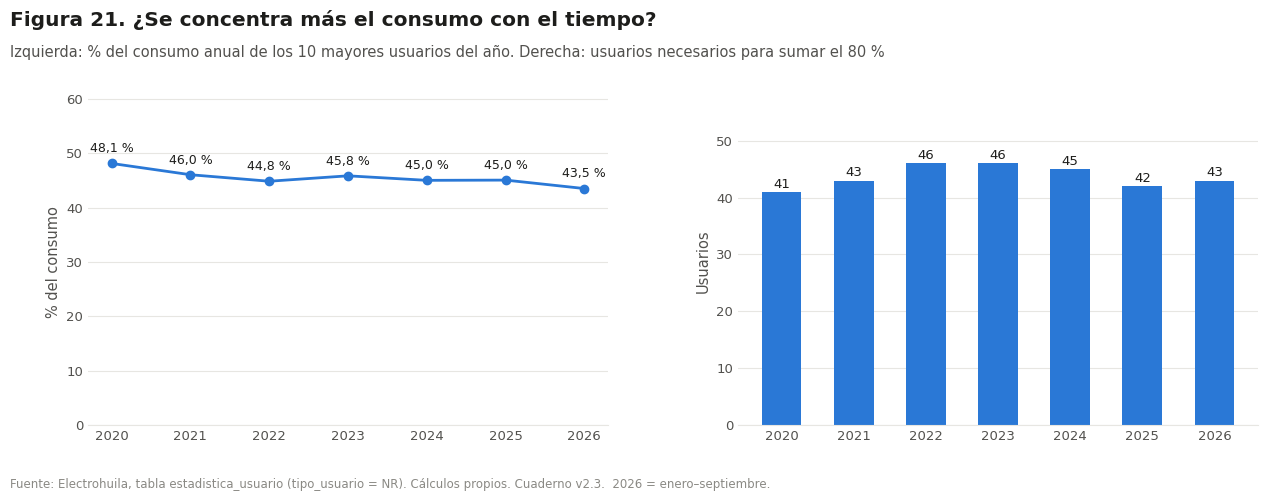

,USUARIOS_CON_CONSUMO,GINI,HHI,%_TOP_10,USUARIOS_80%
AÑO,,,,,
2020,110,0.61,429.51,48.10,41
2021,128,0.64,356.25,46.03,43
2022,131,0.63,278.55,44.83,46
2023,130,0.63,288.47,45.83,46
2024,124,0.61,280.12,45.00,45
2025,125,0.64,288.03,45.04,42
2026,116,0.60,277.50,43.49,43


In [40]:
filas = []
for a, g in base.groupby('ANO'):
    cu = g.groupby('CODIGO_USUARIO')['TOTAL_ACTIVA'].sum().sort_values(ascending=False)
    cu = cu[cu > 0]
    p_ = cu / cu.sum() * 100
    filas.append({'AÑO': a, 'USUARIOS_CON_CONSUMO': len(cu), 'GINI': gini(cu.values), 'HHI': (p_ ** 2).sum(),
                  '%_TOP_10': p_.head(10).sum(), 'USUARIOS_80%': int((p_.cumsum() < 80).sum() + 1)})
conc_anual = pd.DataFrame(filas).set_index('AÑO')

fig, (ax1, ax2) = nueva_figura('¿Se concentra más el consumo con el tiempo?',
                               'Izquierda: % del consumo anual de los 10 mayores usuarios del año. Derecha: usuarios necesarios para sumar el 80 %',
                               ancho=13, alto=4.8, columnas=2)
fig.subplots_adjust(wspace=0.25)
xa = conc_anual.index.astype(str)
ax1.plot(xa, conc_anual['%_TOP_10'], marker='o', color=AZUL)
ax2.bar(xa, conc_anual['USUARIOS_80%'], color=AZUL, width=0.55)
for i, (a, r) in enumerate(conc_anual.iterrows()):
    ax1.annotate(f"{fmt_es(r['%_TOP_10'])} %", (i, r['%_TOP_10']), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9)
    ax2.annotate(f"{int(r['USUARIOS_80%'])}", (i, r['USUARIOS_80%']), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9.5)
ax1.set_ylim(0, conc_anual['%_TOP_10'].max() * 1.25); ax1.set_ylabel('% del consumo')
ax2.set_ylim(0, conc_anual['USUARIOS_80%'].max() * 1.25); ax2.set_ylabel('Usuarios')
guardar(fig, 'evolucion_concentracion', nota='2026 = enero–septiembre.')
conc_anual

**Interpretación — evolución de la concentración**

- **Qué muestra:** la participación de los 10 mayores y los usuarios necesarios para sumar el 80 %, año a año.
- **Hallazgos:**
  - La concentración bajó de 2020 a 2022: los 10 mayores pasaron de 48,1 % a 44,8 % y los usuarios para el 80 % subieron de 41 a 46.
  - Desde 2022 es estable: los 10 mayores pesan 43–46 % y hacen falta 42–46 usuarios para el 80 %.
  - El Gini está entre 0,60 y 0,64 todos los años.


### 8.3 Consumo mensual de los 9 mayores usuarios

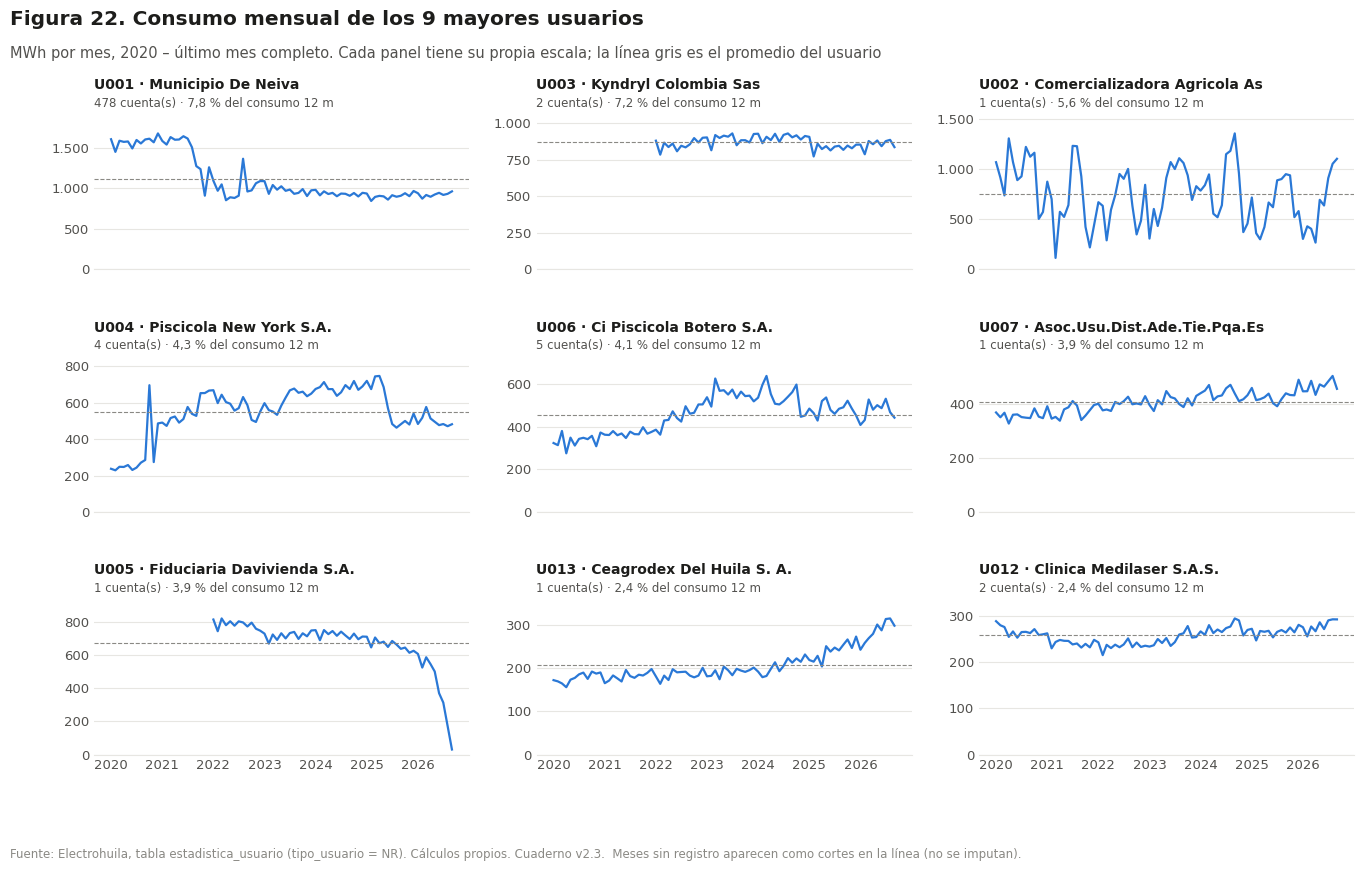

In [41]:
TOP9 = consumo_u.index[:9]
fig, axes = nueva_figura('Consumo mensual de los 9 mayores usuarios',
                         'MWh por mes, 2020 – último mes completo. Cada panel tiene su propia escala; la línea gris es el promedio del usuario',
                         ancho=14, alto=8.5, filas=3, columnas=3, sharex=True)
fig.subplots_adjust(hspace=0.55, wspace=0.18, top=1 - 1.15 / 8.5)
for ax, c in zip(axes.flat, TOP9):
    s = base[base['CODIGO_USUARIO'] == c].groupby('FECHA')['TOTAL_ACTIVA'].sum().reindex(mensual.index) / 1e3
    ax.plot(s.index, s, color=AZUL, lw=1.6)
    ax.axhline(s.mean(), color=TINTA_3, lw=0.8, ls='--')
    n_cuentas = base.loc[base['CODIGO_USUARIO'] == c, 'CUENTA'].nunique()
    ax.set_title(f'{c} · {ETIQUETA[c][:28].title()}', loc='left', fontsize=10, fontweight='bold', pad=17)
    ax.text(0, 1.02, f'{n_cuentas} cuenta(s) · {fmt_es(participacion[c])} % del consumo 12 m', transform=ax.transAxes,
            fontsize=8.5, color=TINTA_2, va='bottom')
    ax.set_ylim(0, s.max() * 1.15); eje_miles(ax); eje_fechas(ax)
guardar(fig, 'consumo_top9_usuarios', nota='Meses sin registro aparecen como cortes en la línea (no se imputan).')

**Interpretación — consumo de los mayores usuarios**

- **Qué muestra:** la serie mensual de cada uno de los 9 mayores usuarios, en su propia escala.
- **Hallazgos:**
  - **Municipio de Neiva:** pasa de ≈ 1,6 GWh/mes en 2020–mediados de 2021 a ≈ 0,95 GWh/mes desde finales de 2021, aunque sus cuentas aumentaron. Un cambio de nivel tan abrupto sugiere cambio de medición, de facturación o modernización del alumbrado, y debe confirmarse.
  - **Comercializadora Agrícola Asoj:** el más variable, con ciclos entre 0,1 y 1,4 GWh/mes, propios de una actividad por temporadas.
  - **Fiduciaria Davivienda:** la cuenta, antes de IBM, consumía ≈ 0,7–0,8 GWh/mes desde 2022 y cae a 30 MWh en septiembre de 2026. Es una **alerta inmediata**.
  - **Piscícola New York (variantes unidas):** sube de ≈ 0,3 a ≈ 0,7 GWh/mes hasta 2024 y baja a ≈ 0,5 en 2026.
  - **Kyndryl, Asociación de distrito de riego, Ceagrodex y Clínica Medilaser:** estables o crecientes.


### 8.4 Mapa de los 20 mayores usuarios por año

Cada celda es el consumo promedio mensual del usuario en el año (MWh/mes). El color compara cada año con el promedio del propio usuario: azul oscuro = año alto, claro = año bajo. Así se ve la trayectoria de cada uno sin que el tamaño de los grandes oculte a los demás.

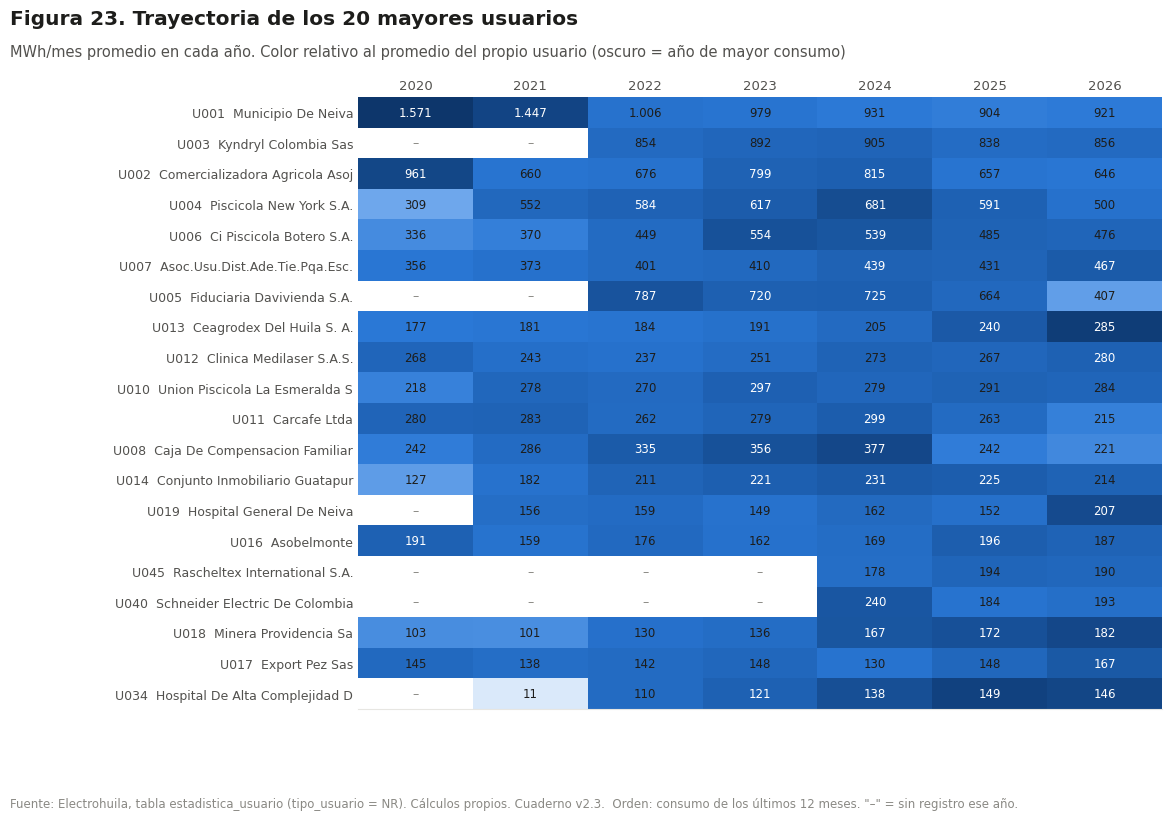

In [42]:
TOP20 = consumo_u.index[:20]
mapa = (prom_u_anio[prom_u_anio['CODIGO_USUARIO'].isin(TOP20)]
        .pivot_table(index='CODIGO_USUARIO', columns='ANO', values='MWH_MES').reindex(TOP20))
mapa_rel = mapa.div(mapa.mean(axis=1), axis=0)
fig, ax = nueva_figura('Trayectoria de los 20 mayores usuarios',
                       'MWh/mes promedio en cada año. Color relativo al promedio del propio usuario (oscuro = año de mayor consumo)',
                       ancho=12, alto=8)
fig.subplots_adjust(left=0.3)
ax.imshow(mapa_rel.values, cmap=SECUENCIAL, aspect='auto', vmin=0, vmax=mapa_rel.max().max())
ax.set_xticks(range(mapa.shape[1]), mapa.columns.astype(str)); ax.xaxis.tick_top()
ax.set_yticks(range(len(mapa)), [f'{c}  {ETIQUETA[c][:30].title()}' for c in mapa.index], fontsize=9)
ax.grid(False)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, miles(v), ha='center', va='center', fontsize=8.5,
                    color='white' if mapa_rel.values[i, j] > 0.75 * mapa_rel.max().max() else TINTA)
        else:
            ax.text(j, i, '–', ha='center', va='center', fontsize=9, color=TINTA_3)
guardar(fig, 'mapa_top20_usuarios', nota='Orden: consumo de los últimos 12 meses. "–" = sin registro ese año.')

**Interpretación — trayectoria de los 20 mayores usuarios**

- **Qué muestra:** el consumo promedio mensual de los 20 mayores usuarios por año; el color indica los años en que cada uno consumió más que su propio promedio.
- **Hallazgos:**
  - **Crecen:** Ceagrodex (177 → 285 MWh/mes), Minera Providencia (103 → 182), Asociación de distrito de riego (356 → 467) y Hospital de Alta Complejidad (110 → 146 desde 2022).
  - **Bajan:** Municipio de Neiva (1.571 → 921), Fiduciaria Davivienda (787 en 2022 → 407), CI Piscícola Botero (554 en 2023 → 476), Caja de Compensación Familiar (377 en 2024 → 221), Carcafé (299 en 2024 → 215) y Piscícola New York (681 en 2024 → 500).
  - **Estables:** Kyndryl (≈ 850–900 desde 2022), Clínica Medilaser, Unión Piscícola La Esmeralda y Asobelmonte.
  - **Recientes:** Rascheltex y Schneider Electric, desde 2024.


## 9. Comportamiento por usuario: cambios, estabilidad y atípicos

### 9.1 Últimos 12 meses frente a los 12 meses anteriores

In [43]:
VENTANA_ANT = pd.date_range(VENTANA[0] - pd.DateOffset(months=12), VENTANA[0] - pd.DateOffset(months=1), freq='MS')
ant = base[base['FECHA'].isin(VENTANA_ANT)].groupby('CODIGO_USUARIO')['TOTAL_ACTIVA'].sum()
comp = pd.DataFrame({'ANTERIOR_KWH': ant, 'ULTIMOS_12M_KWH': consumo_u}).fillna(0)
comp['VAR_%'] = ((comp['ULTIMOS_12M_KWH'] / comp['ANTERIOR_KWH'] - 1) * 100).replace([np.inf, -np.inf], np.nan)
comp['CAMBIO_KWH'] = comp['ULTIMOS_12M_KWH'] - comp['ANTERIOR_KWH']
comp['GRUPO'] = np.select(
    [comp['ANTERIOR_KWH'] == 0, comp['ULTIMOS_12M_KWH'] == 0, comp['VAR_%'] >= 20, comp['VAR_%'] <= -20],
    ['Sin consumo en ventana anterior', 'Sin consumo en últimos 12 m', 'Crece ≥ 20 %', 'Cae ≥ 20 %'], 'Estable (±20 %)')
comp['USUARIO'] = comp.index.map(ETIQUETA)
resumen_comp = comp.groupby('GRUPO').agg(USUARIOS=('USUARIO', 'size'), ANTERIOR_GWH=('ANTERIOR_KWH', 'sum'),
                                         ULTIMOS_12M_GWH=('ULTIMOS_12M_KWH', 'sum'), CAMBIO_GWH=('CAMBIO_KWH', 'sum'))
resumen_comp[['ANTERIOR_GWH', 'ULTIMOS_12M_GWH', 'CAMBIO_GWH']] /= 1e6
resumen_comp.loc['Total'] = resumen_comp.sum()
resumen_comp['USUARIOS'] = resumen_comp['USUARIOS'].astype(int)
resumen_comp

,USUARIOS,ANTERIOR_GWH,ULTIMOS_12M_GWH,CAMBIO_GWH
GRUPO,,,,
Cae ≥ 20 %,20,26.21,16.60,-9.60
Crece ≥ 20 %,17,6.84,10.03,3.19
Estable (±20 %),78,111.79,113.01,1.21
Sin consumo en ventana anterior,6,0.00,1.92,1.92
Sin consumo en últimos 12 m,10,1.98,0.00,-1.98
Total,131,146.82,141.57,-5.26


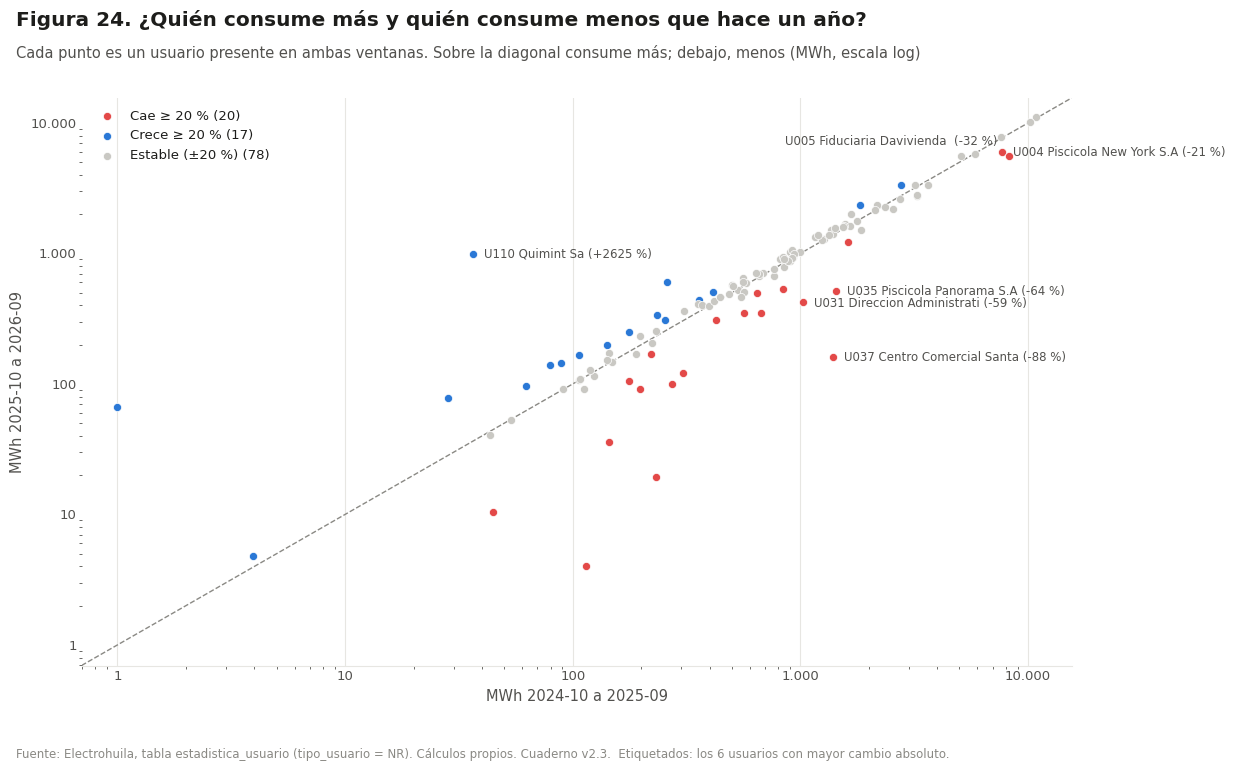

In [44]:
ambos = comp[(comp['ANTERIOR_KWH'] > 0) & (comp['ULTIMOS_12M_KWH'] > 0)]
COLOR_GRUPO = {'Crece ≥ 20 %': AZUL, 'Cae ≥ 20 %': ROJO, 'Estable (±20 %)': GRIS_SUAVE}
fig, ax = nueva_figura('¿Quién consume más y quién consume menos que hace un año?',
                       'Cada punto es un usuario presente en ambas ventanas. Sobre la diagonal consume más; debajo, menos (MWh, escala log)',
                       ancho=11, alto=7.5)
for g, sub in ambos.groupby('GRUPO'):
    ax.scatter(sub['ANTERIOR_KWH'] / 1e3, sub['ULTIMOS_12M_KWH'] / 1e3, s=34, color=COLOR_GRUPO[g],
               label=f'{g} ({len(sub)})', edgecolor='white', lw=0.5, zorder=3)
lim = [ambos[['ANTERIOR_KWH', 'ULTIMOS_12M_KWH']].min().min() / 1e3 * 0.7, ambos[['ANTERIOR_KWH', 'ULTIMOS_12M_KWH']].max().max() / 1e3 * 1.4]
ax.plot(lim, lim, color=TINTA_3, lw=1, ls='--')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim); ax.grid(axis='both')
fmt_log = mtick.FuncFormatter(lambda v, p: f'{v:g}'.replace('.', ',') if v < 1 else miles(v))
ax.xaxis.set_major_formatter(fmt_log); ax.yaxis.set_major_formatter(fmt_log)
ax.set_xlabel(f'MWh {VENTANA_ANT[0]:%Y-%m} a {VENTANA_ANT[-1]:%Y-%m}'); ax.set_ylabel(f'MWh {VENTANA[0]:%Y-%m} a {VENTANA[-1]:%Y-%m}')
for i, (c, r) in enumerate(ambos.reindex(ambos['CAMBIO_KWH'].abs().sort_values(ascending=False).index).head(6).iterrows()):
    ax.annotate(f"{c} {ETIQUETA[c][:22].title()} ({r['VAR_%']:+.0f} %)", (r['ANTERIOR_KWH'] / 1e3, r['ULTIMOS_12M_KWH'] / 1e3),
                xytext=(-8, 8) if i == 0 else (8, -3), ha='right' if i == 0 else 'left', textcoords='offset points', fontsize=8.5, color=TINTA_2)
ax.legend(loc='upper left')
guardar(fig, 'cambio_consumo_usuarios', nota='Etiquetados: los 6 usuarios con mayor cambio absoluto.')

In [45]:
cols = ['USUARIO', 'ANTERIOR_KWH', 'ULTIMOS_12M_KWH', 'CAMBIO_KWH', 'VAR_%', 'GRUPO']
mayores_cambios = pd.concat([comp.nlargest(8, 'CAMBIO_KWH'), comp.nsmallest(8, 'CAMBIO_KWH')])[cols]
mayores_cambios

,USUARIO,ANTERIOR_KWH,ULTIMOS_12M_KWH,CAMBIO_KWH,VAR_%,GRUPO
CODIGO_USUARIO,,,,,,
U110,QUIMINT SA,"36,564.00","996,483.00","959,919.00","2,625.31",Crece ≥ 20 %
U116,PROCESADORA Y COMERCIALIZADORA,0.00,"797,087.00","797,087.00",NaN,Sin consumo en ventana anterior
U106,LABORATORIO FRANCO COLOMBIANO,0.00,"692,484.00","692,484.00",NaN,Sin consumo en ventana anterior
U013,CEAGRODEX DEL HUILA S. A.,"2,763,067.00","3,347,048.00","583,981.00",21.14,Crece ≥ 20 %
U019,HOSPITAL GENERAL DE NEIVA,"1,833,336.00","2,352,455.00","519,119.00",28.32,Crece ≥ 20 %
U007,ASOC.USU.DIST.ADE.TIE.PQA.ESC.,"5,073,736.00","5,556,849.00","483,113.00",9.52,Estable (±20 %)
U054,Persona natural U054,"259,608.00","601,450.00","341,842.00",131.68,Crece ≥ 20 %
U017,EXPORT PEZ SAS,"1,665,421.00","1,990,915.00","325,494.00",19.54,Estable (±20 %)
U005,FIDUCIARIA DAVIVIENDA S.A.,"8,216,461.00","5,554,456.00","-2,662,005.00",-32.40,Cae ≥ 20 %


**Interpretación — cambio de consumo por usuario**

- **Qué muestra:** el consumo de cada usuario en los últimos 12 meses frente a los 12 anteriores; sobre la diagonal crecen y debajo caen.
- **Hallazgos:**
  - El total baja 5,3 GWh (146,8 → 141,6 GWh, −3,6 %).
  - Los 78 usuarios estables (±20 %) suman 113 GWh y suben levemente (+1,2 GWh).
  - **20 usuarios que caen más de 20 % restan 9,6 GWh**: Fiduciaria Davivienda (−2,7 GWh), Piscícola New York (−1,6 GWh, −21 %), Centro Comercial Santa Lucía (−88 %), Piscícola Panorama (−64 %) y Dirección Administrativa Judicial (−59 %).
  - 10 usuarios dejan de consumir (−2,0 GWh), entre ellos Tigre Colombia y Químicos e Impalpables del Huila.
  - Compensan en parte 17 usuarios que crecen (+3,2 GWh) y 6 que aparecen (+1,9 GWh, principalmente Procesadora y Comercializadora y Laboratorio Franco Colombiano).


### 9.2 Estabilidad del consumo mensual

Se mide con el **coeficiente de variación** (CV = desviación estándar / media) de los últimos 24 meses completos, para usuarios con al menos 18 meses con registro en esa ventana. Un CV bajo indica un consumo regular y fácil de anticipar; uno alto, un consumo por temporadas o con cambios bruscos.

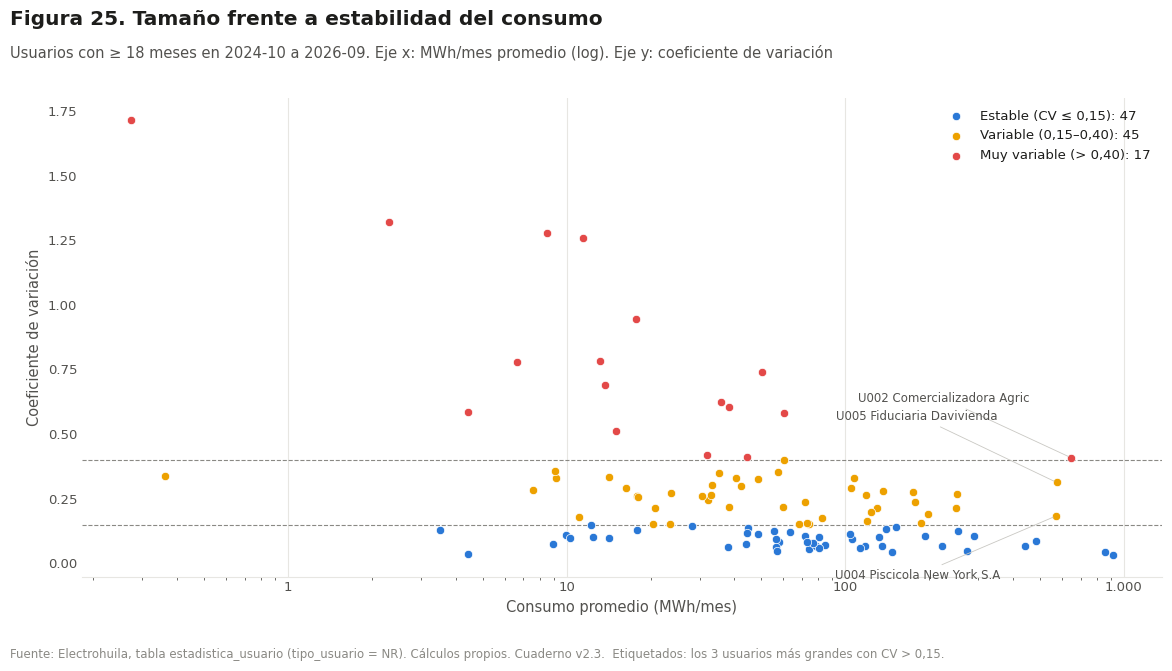

,Usuarios,MWh/mes (suma),% del consumo
ESTABILIDAD,,,
"Estable (CV ≤ 0,15)",47,"6,380.08",54.64
"Variable (0,15–0,40)",45,"4,296.20",36.79
"Muy variable (> 0,40)",17,999.97,8.56


In [46]:
VENTANA_24 = pd.date_range(ULTIMO_MES - pd.DateOffset(months=23), ULTIMO_MES, freq='MS')
s24 = serie_u_24 = (base[base['FECHA'].isin(VENTANA_24)].groupby(['CODIGO_USUARIO', 'FECHA'])['TOTAL_ACTIVA'].sum()
                    .groupby('CODIGO_USUARIO').agg(['mean', 'std', 'size']))
s24 = s24[(s24['size'] >= 18) & (s24['mean'] > 0)].copy()
s24['CV'] = s24['std'] / s24['mean']
s24['MWH_MES'] = s24['mean'] / 1e3
s24['ESTABILIDAD'] = pd.cut(s24['CV'], [-0.01, 0.15, 0.40, np.inf], labels=['Estable (CV ≤ 0,15)', 'Variable (0,15–0,40)', 'Muy variable (> 0,40)'])
tabla_estab = s24.groupby('ESTABILIDAD', observed=False).agg(Usuarios=('CV', 'size'), MWh_mes_promedio=('MWH_MES', 'sum'))
tabla_estab['% del consumo'] = tabla_estab['MWh_mes_promedio'] / tabla_estab['MWh_mes_promedio'].sum() * 100
tabla_estab = tabla_estab.rename(columns={'MWh_mes_promedio': 'MWh/mes (suma)'})

COLOR_ESTAB = {'Estable (CV ≤ 0,15)': AZUL, 'Variable (0,15–0,40)': AMARILLO, 'Muy variable (> 0,40)': ROJO}
fig, ax = nueva_figura('Tamaño frente a estabilidad del consumo',
                       f'Usuarios con ≥ 18 meses en {VENTANA_24[0]:%Y-%m} a {VENTANA_24[-1]:%Y-%m}. Eje x: MWh/mes promedio (log). Eje y: coeficiente de variación',
                       ancho=12, alto=6.5)
for g, sub in s24.groupby('ESTABILIDAD', observed=True):
    ax.scatter(sub['MWH_MES'], sub['CV'], s=36, color=COLOR_ESTAB[g], label=f'{g}: {len(sub)}', edgecolor='white', lw=0.5, zorder=3)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f'{v:g}'.replace('.', ',') if v < 1 else miles(v)))
ax.axhline(0.15, color=TINTA_3, lw=0.8, ls='--'); ax.axhline(0.40, color=TINTA_3, lw=0.8, ls='--')
grandes_variables = s24[(s24['MWH_MES'] >= s24['MWH_MES'].quantile(0.75)) & (s24['CV'] > 0.15)].nlargest(6, 'MWH_MES')
DESPLAZAMIENTOS = [(-30, 40), (-40, 45), (-40, -45)]          # etiquetas sin superposición
for (c, r), d in zip(grandes_variables.head(3).sort_values('CV', ascending=False).iterrows(), DESPLAZAMIENTOS):
    ax.annotate(f'{c} {ETIQUETA[c][:22].title()}', (r['MWH_MES'], r['CV']), xytext=d,
                textcoords='offset points', ha='right', fontsize=8.5, color=TINTA_2,
                arrowprops=dict(arrowstyle='-', color=GRIS_SUAVE, lw=0.6))
ax.set_xlabel('Consumo promedio (MWh/mes)'); ax.set_ylabel('Coeficiente de variación'); ax.grid(axis='both')
ax.legend(loc='upper right')
guardar(fig, 'estabilidad_consumo', nota='Etiquetados: los 3 usuarios más grandes con CV > 0,15.')
tabla_estab

**Interpretación — estabilidad del consumo**

- **Qué muestran:** el tamaño (MWh/mes) frente a la variabilidad mensual (coeficiente de variación) de 109 usuarios con historia suficiente en los últimos 24 meses.
- **Hallazgos:**
  - **47 usuarios son estables** (CV ≤ 0,15) y suman el 54,6 % del consumo, incluidos los dos más grandes: Municipio de Neiva (CV 0,03) y Kyndryl (CV 0,04).
  - 45 son variables y 17 muy variables. Los muy variables son en su mayoría pequeños (mediana de 15 MWh/mes, frente a 74 de los estables) y pesan 8,6 %.
  - Entre los grandes destacan como variables la Comercializadora Agrícola Asoj (CV 0,41, ciclos de temporada), la Fiduciaria Davivienda (0,31, por su caída de 2026) y Piscícola New York (0,18).


### 9.3 Meses atípicos por usuario (puntuación robusta)

Para cada usuario se compara cada mes con su propia mediana: z = 0,6745 · (x − mediana) / MAD. Se marca como atípico si |z| > 3, el valor se aleja al menos 50 % de la mediana **y** la diferencia es de al menos 1.000 kWh (evita marcar oscilaciones pequeñas de usuarios muy estables o de consumo casi nulo). Se excluyen usuarios con menos de 12 meses observados.

In [47]:
serie_u = base.groupby(['CODIGO_USUARIO', 'FECHA'])['TOTAL_ACTIVA'].sum().reset_index()
g = serie_u.groupby('CODIGO_USUARIO')['TOTAL_ACTIVA']
serie_u['MEDIANA'] = g.transform('median')
serie_u['MAD'] = g.transform(lambda s: (s - s.median()).abs().median())
serie_u['MESES'] = g.transform('size')
serie_u['Z_ROBUSTO'] = np.where(serie_u['MAD'] > 0, 0.6745 * (serie_u['TOTAL_ACTIVA'] - serie_u['MEDIANA']) / serie_u['MAD'], np.nan)
serie_u['DESVIO_%'] = np.where(serie_u['MEDIANA'] > 0, (serie_u['TOTAL_ACTIVA'] / serie_u['MEDIANA'] - 1) * 100, np.nan)
serie_u['DIF_KWH'] = serie_u['TOTAL_ACTIVA'] - serie_u['MEDIANA']
serie_u['ATIPICO'] = ((serie_u['Z_ROBUSTO'].abs() > UMBRAL_Z_ROBUSTO) & (serie_u['DESVIO_%'].abs() >= 50)
                      & (serie_u['DIF_KWH'].abs() >= 1_000)
                      & (serie_u['MESES'] >= 12))
serie_u['TIPO'] = np.where(serie_u['TOTAL_ACTIVA'] == 0, 'Cero registrado',
                           np.where(serie_u['Z_ROBUSTO'] > 0, 'Pico', 'Caída'))
anomalias = serie_u[serie_u['ATIPICO']].copy()
anomalias['USUARIO'] = anomalias['CODIGO_USUARIO'].map(ETIQUETA)
resumen_anom = pd.DataFrame({
    'Meses-usuario evaluados': [int((serie_u['MESES'] >= 12).sum())],
    'Meses atípicos': [len(anomalias)],
    'Usuarios con al menos uno': [anomalias['CODIGO_USUARIO'].nunique()],
    'Picos': [int((anomalias['TIPO'] == 'Pico').sum())],
    'Caídas': [int((anomalias['TIPO'] == 'Caída').sum())],
    'Ceros registrados': [int((anomalias['TIPO'] == 'Cero registrado').sum())]}, index=['Resultado']).T
resumen_anom

,Resultado
Meses-usuario evaluados,9569
Meses atípicos,358
Usuarios con al menos uno,75
Picos,276
Caídas,79
Ceros registrados,3


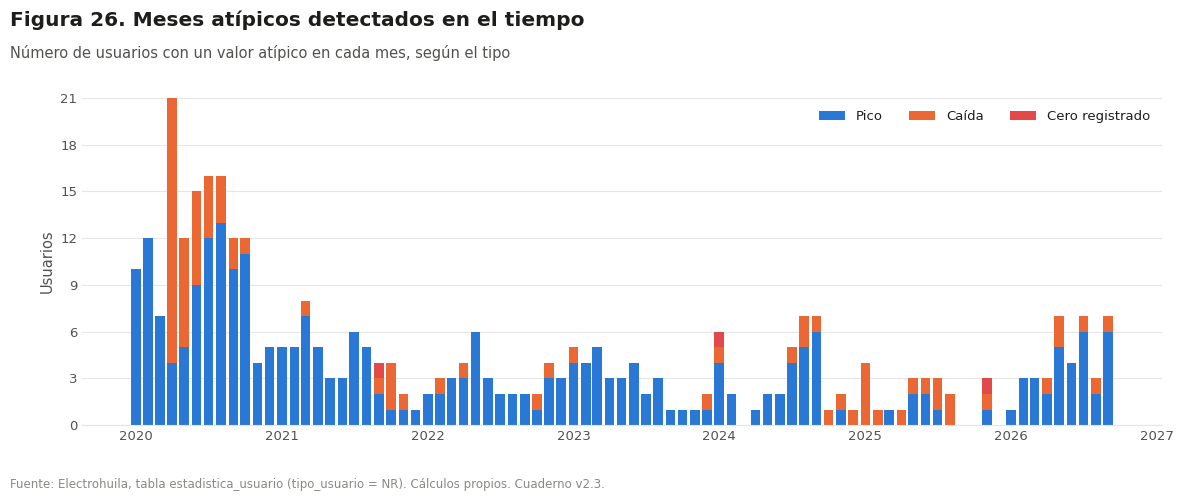

In [48]:
anom_mes = anomalias.groupby(['FECHA', 'TIPO']).size().unstack(fill_value=0).reindex(mensual.index, fill_value=0)
fig, ax = nueva_figura('Meses atípicos detectados en el tiempo',
                       'Número de usuarios con un valor atípico en cada mes, según el tipo', alto=4.8)
abajo = np.zeros(len(anom_mes))
for tipo, color in [('Pico', AZUL), ('Caída', NARANJA), ('Cero registrado', ROJO)]:
    if tipo in anom_mes:
        ax.bar(anom_mes.index, anom_mes[tipo], bottom=abajo, width=24, color=color, label=tipo)
        abajo += anom_mes[tipo].values
ax.set_ylabel('Usuarios'); eje_fechas(ax); ax.legend(loc='upper right', ncol=3)
ax.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))
guardar(fig, 'atipicos_en_el_tiempo')

In [49]:
cols = ['CODIGO_USUARIO', 'USUARIO', 'FECHA', 'TOTAL_ACTIVA', 'MEDIANA', 'DIF_KWH', 'DESVIO_%', 'Z_ROBUSTO', 'TIPO']
# Ordenados por la diferencia absoluta en kWh: los de mayor impacto en el total primero
anomalias.reindex(anomalias['DIF_KWH'].abs().sort_values(ascending=False).index)[cols].head(12)

,CODIGO_USUARIO,USUARIO,FECHA,TOTAL_ACTIVA,MEDIANA,DIF_KWH,DESVIO_%,Z_ROBUSTO,TIPO
11,U001,MUNICIPIO DE NEIVA,2020-12-01,1673687,"960,803.00","712,884.00",74.20,7.71,Pico
1513,U020,CLINICA UROS S.A. S,2022-11-01,833952,"126,749.00","707,203.00",557.96,27.23,Pico
356,U005,FIDUCIARIA DAVIVIENDA S.A.,2026-09-01,30275,"714,371.00","-684,096.00",-95.76,-11.78,Caída
17,U001,MUNICIPIO DE NEIVA,2021-06-01,1638923,"960,803.00","678,120.00",70.58,7.34,Pico
14,U001,MUNICIPIO DE NEIVA,2021-03-01,1628123,"960,803.00","667,320.00",69.45,7.22,Pico
18,U001,MUNICIPIO DE NEIVA,2021-07-01,1610639,"960,803.00","649,836.00",67.63,7.03,Pico
9,U001,MUNICIPIO DE NEIVA,2020-10-01,1608696,"960,803.00","647,893.00",67.43,7.01,Pico
0,U001,MUNICIPIO DE NEIVA,2020-01-01,1602039,"960,803.00","641,236.00",66.74,6.94,Pico
8,U001,MUNICIPIO DE NEIVA,2020-09-01,1599200,"960,803.00","638,397.00",66.44,6.91,Pico
16,U001,MUNICIPIO DE NEIVA,2021-05-01,1598611,"960,803.00","637,808.00",66.38,6.90,Pico


**Interpretación — meses atípicos**

- **Qué muestran:** el resumen de valores atípicos, su distribución en el tiempo y los 12 de mayor impacto en kWh.
- **Hallazgos:**
  - 358 meses atípicos (3,7 % de 9.569 evaluados) en 75 usuarios: 276 picos, 79 caídas y 3 ceros.
  - **Abril de 2020** concentra 21 usuarios atípicos (17 caídas), coherente con el aislamiento por la pandemia.
  - Los de mayor impacto son:
    - los picos del Municipio de Neiva en 2020–2021, que son el nivel previo a su cambio de 2021 (el método también detecta **cambios de nivel**);
    - Clínica Uros en noviembre de 2022 (834 MWh frente a una mediana de 127);
    - la caída de la Fiduciaria Davivienda en septiembre de 2026 (−96 %).
  - El E.S.E. Hospital Universitario tiene 40 meses atípicos: su consumo bajó de ≈ 6 GWh/año (2020–2022) a ≈ 0,7 desde 2024, otro cambio de nivel por explicar.


### 9.4 Ceros registrados

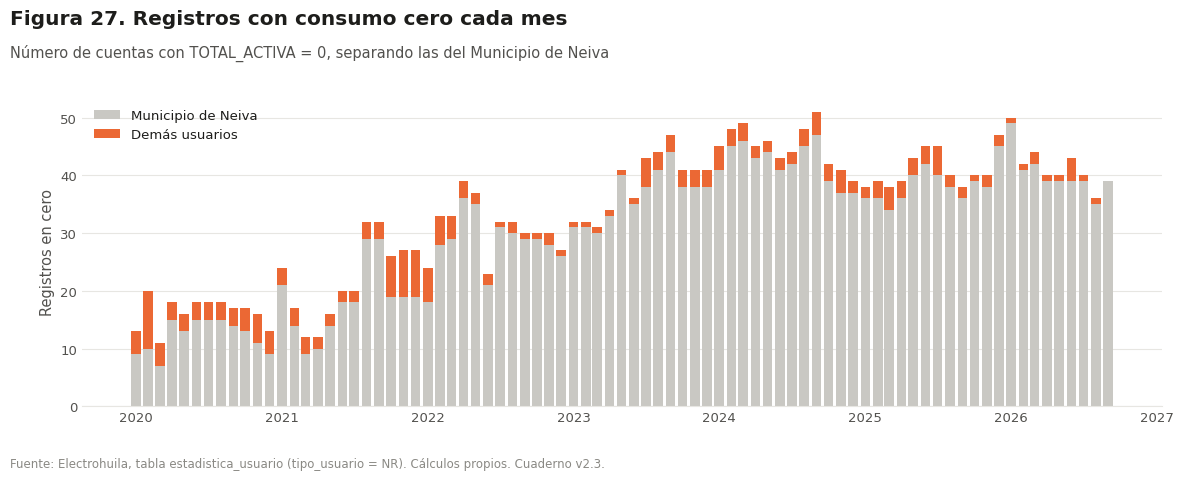

,Usuario,Registros_en_cero,Cuentas,% de sus registros
CODIGO_USUARIO,,,,
U001,MUNICIPIO DE NEIVA,2471,263,7.17
U011,CARCAFE LTDA,74,2,14.40
U031,DIRECCION ADMINISTRATIVA JUDIC,17,1,11.56
U147,INGECARPA S.A.S,17,1,68.00
U149,HOSPITAL UNIVERSITARIO DE NEIV,15,1,100.00
U023,QUIMICOS E IMPALPABLES DEL HUI,15,1,19.74
U124,Persona natural U124,14,1,21.54
U109,CAFE FORTALEZA S.A.S.,7,1,8.33
U006,CI PISCICOLA BOTERO S.A.,6,2,2.63


In [50]:
ceros = base[base['TOTAL_ACTIVA'] == 0]
ceros_mes = (ceros.assign(GRUPO=np.where(ceros['CODIGO_USUARIO'] == COD_NEIVA, 'Municipio de Neiva', 'Demás usuarios'))
             .groupby(['FECHA', 'GRUPO']).size().unstack(fill_value=0).reindex(mensual.index, fill_value=0))
ceros_usuario = (ceros.groupby('CODIGO_USUARIO').agg(Registros_en_cero=('CUENTA', 'size'), Cuentas=('CUENTA', 'nunique'))
                 .sort_values('Registros_en_cero', ascending=False))
ceros_usuario.insert(0, 'Usuario', ceros_usuario.index.map(ETIQUETA))
ceros_usuario['% de sus registros'] = ceros_usuario['Registros_en_cero'] / base.groupby('CODIGO_USUARIO').size().reindex(ceros_usuario.index) * 100

fig, ax = nueva_figura('Registros con consumo cero cada mes',
                       'Número de cuentas con TOTAL_ACTIVA = 0, separando las del Municipio de Neiva', alto=4.6)
ax.bar(ceros_mes.index, ceros_mes.get('Municipio de Neiva', 0), width=24, color=GRIS_SUAVE, label='Municipio de Neiva')
ax.bar(ceros_mes.index, ceros_mes.get('Demás usuarios', 0), bottom=ceros_mes.get('Municipio de Neiva', 0), width=24,
       color=NARANJA, label='Demás usuarios')
ax.set_ylabel('Registros en cero'); eje_fechas(ax); ax.legend(loc='upper left')
guardar(fig, 'ceros_registrados')
ceros_usuario.head(10)

**Interpretación — ceros registrados**

- **Qué muestran:** el número de registros con consumo cero cada mes y los usuarios con más ceros.
- **Hallazgos:**
  - De los 2.700 registros en cero del periodo, **2.471 (91,5 %) son de 263 cuentas del Municipio de Neiva**.
  - El total de ceros por mes crece de ≈ 16 en 2020 a ≈ 42 en 2026.
  - En los demás usuarios hay 229 ceros. Destacan Carcafé (74), la Dirección Administrativa Judicial (17), Ingecarpa (17, el 68 % de sus registros) y la cuenta *Hospital Universitario de Neiva* (todos sus registros en cero).


## 10. Exportación de tablas y verificación de totales

In [51]:
# --- Verificación: los totales deben cuadrar en cada etapa ---
total_original = df['TOTAL_ACTIVA'].sum()
controles = pd.DataFrame([
    ('Registros: archivo = copia de trabajo', len(df), len(df_a)),
    (f'{UNIDAD}: archivo = copia de trabajo', total_original, df_a['TOTAL_ACTIVA'].sum()),
    (f'{UNIDAD}: archivo = base de análisis + mes incompleto excluido', total_original, base['TOTAL_ACTIVA'].sum() + excluidos['TOTAL_ACTIVA'].sum()),
    (f'{UNIDAD}: base de análisis = suma de la serie mensual', base['TOTAL_ACTIVA'].sum(), mensual['CONSUMO_KWH'].sum()),
    (f'{UNIDAD}: base de análisis = suma del consumo anual', base['TOTAL_ACTIVA'].sum(), round(anual['CONSUMO_GWH'].sum() * 1e6)),
    (f'{UNIDAD}: base de análisis = suma por usuario', base['TOTAL_ACTIVA'].sum(), base.groupby('USUARIO')['TOTAL_ACTIVA'].sum().sum()),
    (f'{UNIDAD}: últimos 12 meses = suma del ranking', ult12['TOTAL_ACTIVA'].sum(), consumo_u.sum()),
    ('Registros sin usuario asignado', 0, int(df_a['USUARIO'].isna().sum())),
], columns=['Control', 'Esperado', 'Obtenido'])
controles['¿Cuadra?'] = np.where(np.isclose(controles['Esperado'], controles['Obtenido']), 'Sí', 'NO')
cuentas_multiusuario = int((df_a.groupby('CUENTA')['USUARIO'].nunique() > 1).sum())
print(f'Cuentas cuyo historial queda repartido entre más de un usuario (cambio de titular): {cuentas_multiusuario}')
assert (controles['¿Cuadra?'] == 'Sí').all(), 'Hay totales que no cuadran'
controles

Cuentas cuyo historial queda repartido entre más de un usuario (cambio de titular): 0


,Control,Esperado,Obtenido,¿Cuadra?
0,Registros: archivo = copia de trabajo,46749,46749,Sí
1,kWh: archivo = copia de trabajo,978707686,978707686,Sí
2,kWh: archivo = base de análisis + mes incomple...,978707686,978707686,Sí
3,kWh: base de análisis = suma de la serie mensual,978212080,978212080,Sí
4,kWh: base de análisis = suma del consumo anual,978212080,978212080,Sí
5,kWh: base de análisis = suma por usuario,978212080,978212080,Sí
6,kWh: últimos 12 meses = suma del ranking,141565696,141565696,Sí
7,Registros sin usuario asignado,0,0,Sí


**Interpretación — verificación**

- **Qué muestra:** los controles de totales entre el archivo original y cada tabla del análisis.
- **Hallazgos:**
  - Todos los controles cuadran. La copia de trabajo conserva los 46.749 registros y los 978.707.686 kWh del archivo.
  - La base de análisis, la serie mensual, el consumo anual y la suma por usuario coinciden en 978.212.080 kWh. La diferencia, 495.606 kWh, son los 2 registros de octubre de 2026 excluidos.
  - El ranking de 12 meses suma exactamente el consumo de la ventana.
  - Ninguna cuenta queda repartida entre dos usuarios, como corresponde al método del titular actual.


### Libro de Excel con todos los resultados

Cada tabla se exporta con encabezados en español, formato de miles, fechas como año-mes y porcentajes con un decimal. Cada hoja es una *Tabla de Excel* con filtros, y la primera hoja es un índice con vínculos. En las hojas de resultados se usa la etiqueta protegida del usuario; los nombres originales solo aparecen en las hojas de homologación, que son necesarias para revisar la consolidación.

In [52]:
MES_TXT = MESES_ES[MES_CORTE - 1].lower()
ult12_u = consumo_u.rename('c12')
t_usuarios = pd.DataFrame({
    'Código': usuarios['CODIGO'], 'Usuario': usuarios['ETIQUETA'],
    'Tipo de titular': np.where(usuarios['PERSONA_NATURAL'], 'Persona natural (nombre protegido)', 'Persona jurídica o entidad'),
    'Cuentas': usuarios['CUENTAS'], 'Variantes de nombre': usuarios['VARIANTES_NOMBRE'],
    'Primer mes': usuarios['PRIMER_MES'], 'Último mes': usuarios['ULTIMO_MES'],
    'Consumo total 2020-2026 (kWh)': usuarios['CONSUMO_TOTAL_KWH']})
t_usuarios['Consumo últimos 12 m (kWh)'] = t_usuarios['Código'].map(consumo_u).fillna(0)
t_usuarios['% del consumo 12 m'] = t_usuarios['Código'].map(participacion).fillna(0)
t_usuarios['Grupo de cambio 12 m'] = t_usuarios['Código'].map(comp['GRUPO']).fillna('Sin consumo en ambas ventanas')

t_ranking = pd.DataFrame({'Posición': range(1, len(consumo_u) + 1), 'Código': consumo_u.index,
                          'Usuario': consumo_u.index.map(ETIQUETA), 'Consumo 12 m (kWh)': consumo_u.values,
                          '% del total': participacion.values, '% acumulado': acum.values})

t_indices = pd.DataFrame({'Indicador': ['Usuarios con consumo', 'Consumo total (GWh)', '% del mayor usuario', '% de los 5 mayores',
                                        '% de los 10 mayores', '% de los 20 mayores', 'Usuarios que suman el 80 %',
                                        'Índice de Gini (0–1)', 'HHI (0–10.000)'],
                          'Valor': [len(consumo_u), consumo_u.sum() / 1e6, acum.iloc[0], acum.iloc[4], acum.iloc[9],
                                    acum.iloc[19], N80, GINI, HHI]})

t_calidad = calidad.copy()
t_calidad['% de registros'] = [np.nan] + [v / len(df_a) * 100 if isinstance(v, (int, np.integer)) and i in (1, 2, 3, 4, 5) else np.nan
                                          for i, v in enumerate(calidad['Valor'][1:], start=1)]

t_mensual = mensual.reset_index().rename(columns={'FECHA': 'Mes', 'USUARIOS': 'Usuarios', 'CUENTAS': 'Cuentas',
                                                  'CONSUMO_KWH': 'Consumo (kWh)', 'CUENTAS_POR_USUARIO': 'Cuentas por usuario'})
t_mensual.insert(4, 'Consumo (GWh)', t_mensual['Consumo (kWh)'] / 1e6)
t_mensual['Promedio móvil 12 m (GWh)'] = media_movil.values

t_anual = anual.reset_index()
t_anual.columns = ['Año', 'Consumo (GWh)', 'Meses con datos', 'Var. % vs año anterior', f'Consumo ene–{MESES_ES[MES_CORTE - 1].lower()} (GWh)',
                   'Var. % periodo equivalente', 'Promedio mensual (GWh)']

t_estac = tabla_est.copy(); t_estac['Total'] = t_estac.sum(axis=1, min_count=1)
t_estac = t_estac.reset_index().rename(columns={'ANO': 'Año'})
t_indice_est = pd.DataFrame({'Mes': MESES_ES, 'Índice estacional (100 = promedio)': perfil.values})

t_tramos = distribucion.reset_index().rename(columns={distribucion.index.name: 'Consumo promedio mensual (kWh)',
                                                      '% cuentas': '% de cuentas', '% consumo': '% del consumo'})
t_tramos['Consumo promedio mensual (kWh)'] = t_tramos['Consumo promedio mensual (kWh)'].astype(str)

t_cambio = comp.reset_index().rename(columns={'CODIGO_USUARIO': 'Código', 'index': 'Código'})
t_cambio = t_cambio[['Código', 'USUARIO', 'ANTERIOR_KWH', 'ULTIMOS_12M_KWH', 'CAMBIO_KWH', 'VAR_%', 'GRUPO']]
t_cambio.columns = ['Código', 'Usuario', f'Consumo {VENTANA_ANT[0]:%Y-%m} a {VENTANA_ANT[-1]:%Y-%m} (kWh)',
                    f'Consumo {VENTANA[0]:%Y-%m} a {VENTANA[-1]:%Y-%m} (kWh)', 'Cambio (kWh)', 'Variación %', 'Grupo']
t_cambio = t_cambio.sort_values('Cambio (kWh)')

t_atip = anomalias.reindex(anomalias['DIF_KWH'].abs().sort_values(ascending=False).index)
t_atip = t_atip[['CODIGO_USUARIO', 'USUARIO', 'FECHA', 'TOTAL_ACTIVA', 'MEDIANA', 'DIF_KWH', 'DESVIO_%', 'Z_ROBUSTO', 'TIPO']]
t_atip.columns = ['Código', 'Usuario', 'Mes', 'Consumo del mes (kWh)', 'Mediana del usuario (kWh)', 'Diferencia (kWh)',
                  'Desvío %', 'Z robusto', 'Tipo']

t_corresp = (df_a.groupby(['CODIGO_USUARIO', 'USUARIO', 'NOMBRE_LIMPIO'])
             .agg(Cuentas=('CUENTA', 'nunique'), Primer_mes=('FECHA', 'min'), Ultimo_mes=('FECHA', 'max')).reset_index())
t_corresp.columns = ['Código', 'Usuario (titular actual)', 'Nombre en el archivo', 'Cuentas', 'Primer mes', 'Último mes']

t_estructura = estructura.reset_index().rename(columns={'index': 'Columna'})

t_flujos = flujos.reset_index()
t_flujos.columns = ['Año', 'Usuarios observados', 'Primera aparición', 'Reaparece', 'Deja de observarse', 'Permanece del año anterior']

P12 = f'{VENTANA[0]:%Y-%m} a {VENTANA[-1]:%Y-%m}'
HOJAS = [
    dict(hoja='Usuarios', tabla=t_usuarios, titulo='Usuarios consolidados',
         descripcion='Un registro por usuario (titular actual de sus cuentas), ordenado por consumo total. Nombres de personas naturales protegidos.'),
    dict(hoja='Serie mensual', tabla=t_mensual, titulo='Usuarios, cuentas y consumo por mes',
         descripcion=f'Enero 2020 – {ULTIMO_MES:%Y-%m} (último mes completo).'),
    dict(hoja='Flujos anuales', tabla=t_flujos, titulo='Primera aparición y deja de observarse por año',
         descripcion=f'2026 = enero–{MES_TXT}. Para 2020 no se calculan flujos (no hay año anterior).'),
    dict(hoja='Consumo anual', tabla=t_anual, titulo='Consumo anual y comparación de periodos equivalentes',
         descripcion=f'GWh. La variación de periodo equivalente compara enero–{MES_TXT} de cada año.'),
    dict(hoja='Consumo año-mes', tabla=t_estac, titulo='Consumo por año y mes (GWh)',
         descripcion='Celdas vacías = meses aún no disponibles.'),
    dict(hoja='Índice estacional', tabla=t_indice_est, titulo='Índice estacional promedio',
         descripcion='100 = promedio mensual del año; calculado con los años completos.'),
    dict(hoja='Tramos por cuenta', tabla=t_tramos, titulo='Cuentas por tramo de consumo promedio mensual',
         descripcion='Incluye cuántas cuentas de cada tramo son del Municipio de Neiva.'),
    dict(hoja='Concentración', tabla=t_indices, titulo='Indicadores de concentración del consumo',
         descripcion=f'Últimos 12 meses ({P12}).'),
    dict(hoja='Ranking 12 m', tabla=t_ranking, titulo='Ranking de usuarios por consumo',
         descripcion=f'Últimos 12 meses ({P12}).'),
    dict(hoja='Cambio 12 m', tabla=t_cambio, titulo='Cambio de consumo por usuario',
         descripcion='Últimos 12 meses frente a los 12 anteriores, ordenado de mayor caída a mayor aumento.'),
    dict(hoja='Atípicos', tabla=t_atip, titulo='Meses atípicos por usuario',
         descripcion='|z robusto| > 3, desvío ≥ 50 % y diferencia ≥ 1.000 kWh. Ordenado por impacto en kWh.'),
    dict(hoja='Calidad', tabla=t_calidad, titulo='Controles de calidad del archivo', descripcion='Sobre los 46.749 registros originales.'),
    dict(hoja='Estructura', tabla=t_estructura, titulo='Estructura del archivo de entrada',
         descripcion='Hoja Exportar Hoja de Trabajo del Excel de entrada.'),
    dict(hoja='Correspondencia nombres', tabla=t_corresp, titulo='Correspondencia nombre original → usuario (titular actual)',
         descripcion='Uso interno: contiene nombres de titulares para revisar la homologación.'),
    dict(hoja='Cuentas varios nombres', tabla=TABLA_CAMBIOS, titulo='Cuentas que aparecen con más de un nombre',
         descripcion='Uso interno. Similitud < 0,6 = posible cambio de titular.'),
    dict(hoja='Homologación pendiente', tabla=TABLA_CANDIDATOS, titulo='Pares de nombres parecidos no unidos',
         descripcion='Variantes de escritura entre usuarios. Registre la decisión en la columna correspondiente.'),
    dict(hoja='Cobertura cuentas', tabla=cobertura, titulo='Cobertura del registro mensual por cuenta',
         descripcion='Resumen de la figura de registro mensual de cada cuenta.'),
    dict(hoja='Ciclos', tabla=ciclos.reset_index().rename(columns={'CICLO': 'Ciclo'}), titulo='Registros, cuentas y consumo por ciclo de facturación',
         descripcion='Ninguna cuenta cambia de ciclo.'),
    dict(hoja='Permanencia', tabla=tabla_perm.reset_index().astype({'Meses con registro': str}), titulo='Usuarios según meses con registro',
         descripcion=f'De {N_MESES} meses posibles; activos = se observan en el último mes completo.'),
    dict(hoja='Composición anual', tabla=comp_anual_seg.reset_index().rename(columns={'AÑO': 'Año'})
         .rename(columns=lambda c: c if c == 'Año' else f'{c} (GWh)'),
         titulo='Consumo anual por segmento (GWh)', descripcion='10 grandes = mayores por consumo 2020–2026 sin el Municipio de Neiva.'),
    dict(hoja='Cohortes', tabla=coh_anual.reset_index().rename(columns={'AÑO': 'Año'}).rename(columns=lambda c: f'Cohorte {c} (GWh)' if isinstance(c, (int, np.integer)) else ('Total (GWh)' if c == 'Total' else c)),
         titulo='Consumo anual por cohorte de primera aparición (GWh)', descripcion='Filas = año de consumo; columnas = año de primera aparición.'),
    dict(hoja='Distribución anual', tabla=resumen_anio.reset_index().rename(columns={'ANO': 'Año', 'P25': 'P25 (MWh/mes)', 'Mediana': 'Mediana (MWh/mes)',
                                                                                   'P75': 'P75 (MWh/mes)', 'P90': 'P90 (MWh/mes)', 'Máximo': 'Máximo (MWh/mes)'}),
         titulo='Consumo promedio mensual por usuario: percentiles por año', descripcion='Usuarios con consumo positivo en el año.'),
    dict(hoja='Concentración anual', tabla=conc_anual.reset_index().rename(columns={
        'AÑO': 'Año', 'USUARIOS_CON_CONSUMO': 'Usuarios con consumo', 'GINI': 'Gini', 'HHI': 'HHI', '%_TOP_10': '% de los 10 mayores',
        'USUARIOS_80%': 'Usuarios que suman el 80 %'}), titulo='Indicadores de concentración por año', descripcion='2026 = enero–septiembre.'),
    dict(hoja='Top 20 por año', tabla=mapa.reset_index().assign(Usuario=lambda d: d['CODIGO_USUARIO'].map(ETIQUETA))
         .rename(columns={'CODIGO_USUARIO': 'Código'}).rename(columns=lambda c: f'{c} (MWh/mes)' if isinstance(c, (int, np.integer)) else c)
         [['Código', 'Usuario'] + [f'{c} (MWh/mes)' for c in mapa.columns]],
         titulo='Consumo promedio mensual de los 20 mayores usuarios por año', descripcion='Celdas vacías = sin registro ese año.'),
    dict(hoja='Estabilidad', tabla=s24.reset_index().assign(Usuario=lambda d: d['CODIGO_USUARIO'].map(ETIQUETA))
         .rename(columns={'CODIGO_USUARIO': 'Código', 'MWH_MES': 'Promedio (MWh/mes)', 'CV': 'Coef. de variación', 'size': 'Meses',
                          'ESTABILIDAD': 'Estabilidad'})[['Código', 'Usuario', 'Meses', 'Promedio (MWh/mes)', 'Coef. de variación', 'Estabilidad']]
         .astype({'Estabilidad': str}).sort_values('Promedio (MWh/mes)', ascending=False),
         titulo='Estabilidad del consumo mensual por usuario', descripcion=f'Últimos 24 meses ({VENTANA_24[0]:%Y-%m} a {VENTANA_24[-1]:%Y-%m}).'),
    dict(hoja='Ceros por usuario', tabla=ceros_usuario.reset_index().rename(columns={'CODIGO_USUARIO': 'Código', 'Registros_en_cero': 'Registros en cero'}),
         titulo='Registros con consumo cero por usuario', descripcion='Periodo de análisis (sin el mes incompleto).'),
    dict(hoja='Listado 156 usuarios', tabla=pd.DataFrame({'N.º': range(1, len(listado_usuarios) + 1), 'Usuario (titular actual)': listado_usuarios}),
         titulo='Listado de usuarios: titular actual de cada cuenta', descripcion='Uso interno. Mismo listado del análisis original.'),
    dict(hoja='Nombres absorbidos', tabla=absorbidos.rename(columns={'NOMBRE_ANTERIOR': 'Nombre anterior', 'TITULAR_ACTUAL': 'Titular actual',
                                                                     'CUENTAS': 'Cuentas', 'REGISTROS': 'Registros'}),
         titulo='Nombres anteriores que pasan al titular actual de la cuenta', descripcion='Uso interno.'),
    dict(hoja='Verificación', tabla=controles, titulo='Verificación de totales', descripcion='Todos los controles deben decir Sí.'),
]
salida = exportar_excel(DIR_TAB / 'resultados_analisis_exploratorio.xlsx', HOJAS,
                        titulo_libro='Usuarios especiales de Electrohuila — resultados del análisis exploratorio')
print('Libro exportado:', salida)
print(pd.DataFrame({'Hoja': [h['hoja'] for h in HOJAS], 'Filas': [len(h['tabla']) for h in HOJAS]}).to_string(index=False))

Libro exportado: output/tablas/resultados_analisis_exploratorio.xlsx
                   Hoja  Filas
               Usuarios    152
          Serie mensual     81
         Flujos anuales      7
          Consumo anual      7
        Consumo año-mes      7
      Índice estacional     12
      Tramos por cuenta      5
          Concentración      9
           Ranking 12 m    121
            Cambio 12 m    131
               Atípicos    358
                Calidad      9
             Estructura      7
Correspondencia nombres    218
 Cuentas varios nombres     71
 Homologación pendiente      9
      Cobertura cuentas      5
                 Ciclos      3
            Permanencia      5
      Composición anual      7
               Cohortes      7
     Distribución anual      7
    Concentración anual      7
         Top 20 por año     20
            Estabilidad    109
      Ceros por usuario     37
   Listado 156 usuarios    152
     Nombres absorbidos     69
           Verificación      8


**Cómo leer el libro de resultados.** La hoja *Índice* lista todas las tablas con vínculos. Las hojas con etiqueta protegida (*Usuarios*, consumo, concentración, comportamiento) se pueden compartir. Las de homologación (*Correspondencia nombres*, *Cuentas varios nombres*, *Homologación pendiente*, *Listado 156 usuarios* y *Nombres absorbidos*) son de uso interno porque muestran nombres originales. En *Homologación pendiente* el revisor puede anotar su decisión para incorporarla al diccionario `remplazo` de la sección 4.4. Todas las hojas tienen filtros, encabezado fijo y formatos de miles, fecha (año-mes) y porcentaje.

## 11. Conclusiones y próximos pasos

1. **Datos confiables.** No hay duplicados, nulos ni negativos, y todos los totales cuadran con el archivo. El 94 % de los meses-cuenta tiene consumo y solo el 0,3 % son vacíos. Octubre de 2026 está incompleto y se excluye.
2. **152 usuarios detrás de 701 cuentas.** Cada cuenta toma su último nombre (titular actual) y se unen 5 pares de variantes de escritura. El Municipio de Neiva tiene 478 cuentas (68 %).
3. **Base estable.**
   - Entre 105 y 131 usuarios activos al mes; hoy, 114.
   - 76 usuarios están presentes los 81 meses y generan el 75 % del consumo.
   - En 2026 dejaron de observarse 13 usuarios (2,8 GWh en 2025).
4. **Consumo en tres fases.**
   - Crecimiento a 157 GWh en 2022, impulsado por Kyndryl y la cuenta hoy de la Fiduciaria Davivienda.
   - Meseta en 2023–2024, con un máximo de 159,8 GWh.
   - Caída de 10 % en 2025, generalizada y concentrada en usuarios antiguos.

   En enero–septiembre de 2026 la caída se modera (−1,9 %) y desde junio la variación interanual vuelve a ser positiva.
5. **Estacionalidad moderada.** Julio–octubre están 2–6 % por encima del promedio anual y abril–junio y noviembre 4–6 % por debajo.
6. **Concentración alta pero estable.** 42 usuarios generan el 80 % del consumo (Gini 0,62) y ninguno pesa más de 8 %.
7. **Alertas de seguimiento:**
   - la caída de la Fiduciaria Davivienda a 30 MWh en septiembre de 2026;
   - el cambio de nivel del Municipio de Neiva en 2021 y del E.S.E. Hospital Universitario desde 2023;
   - los 20 usuarios que caen más de 20 % en el último año;
   - el aumento de cuentas municipales en cero (de ≈ 16 a ≈ 42 por mes).
8. **Predecibilidad.** El 55 % del consumo viene de usuarios estables (CV ≤ 0,15), lo que favorece un pronóstico por segmentos.
9. **Perfiles estacionales.** El k-means con normalización por el máximo identifica dos perfiles: *regular* (79 % de los perfiles usuario-año y 91 % del consumo) e *irregular* (21 % y 9 %). La irregularidad se disparó en 2020 (40 % de los usuarios) por la pandemia.

### Información faltante y próximos pasos
- **NIT o código único de cliente**, para validar la consolidación sin depender del nombre.
- **Unidad oficial** de `TOTAL_ACTIVA` (aquí se infiere kWh) y **significado del ciclo 202**.
- **Explicación de los cambios de nivel** (Municipio de Neiva 2021, Hospital Universitario 2023) y revisión de los atípicos con facturación.
- **Depuración de cuentas municipales en cero** con el Municipio de Neiva.
- **Seguimiento mensual** de los 42 usuarios que suman el 80 % y de los 20 que caen más de 20 %.
- **Siguiente etapa:** pronóstico mensual por segmentos (estables y variables) con el panel de 76 usuarios permanentes.

## 12. Referencias

Hong, T., & Fan, S. (2016). Probabilistic electric load forecasting: A tutorial review. *International Journal of Forecasting, 32*(3), 914–938. https://doi.org/10.1016/j.ijforecast.2015.11.011

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Leys, C., Ley, C., Klein, O., Bernard, P., & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute deviation around the median. *Journal of Experimental Social Psychology, 49*(4), 764–766. https://doi.org/10.1016/j.jesp.2013.03.013

Rhoades, S. A. (1993). The Herfindahl-Hirschman index. *Federal Reserve Bulletin*, marzo de 1993. https://fedinprint.org/item/fedgrb/15160

Wang, Y., Chen, Q., Hong, T., & Kang, C. (2019). Review of smart meter data analytics: Applications, methodologies, and challenges. *IEEE Transactions on Smart Grid, 10*(3), 3125–3148. https://doi.org/10.1109/TSG.2018.2818167

## 12. Entrega final: base de resultados y dashboard

Esta última etapa exporta el DataFrame de análisis y genera el dashboard usando la misma fuente y reglas de consolidación.

In [ ]:
# =============================================================================
# 12. Entrega final: base de resultados y dashboard
# =============================================================================
# El notebook es el único archivo de programación del proyecto.
# `base` es el DataFrame final del análisis exploratorio.
import sqlite3

resultado_exploratorio = base.copy()
if 'ID_CUENTA' not in resultado_exploratorio.columns:
    resultado_exploratorio['ID_CUENTA'] = resultado_exploratorio['CUENTA']
if 'USUARIO_CONSOLIDADO' not in resultado_exploratorio.columns:
    resultado_exploratorio['USUARIO_CONSOLIDADO'] = resultado_exploratorio['USUARIO']
if 'PERSONA_NATURAL' not in resultado_exploratorio.columns:
    resultado_exploratorio['PERSONA_NATURAL'] = resultado_exploratorio['USUARIO'].map(usuarios['PERSONA_NATURAL']).fillna(False)
if 'TIPO_TITULAR' not in resultado_exploratorio.columns:
    resultado_exploratorio['TIPO_TITULAR'] = np.where(
        resultado_exploratorio['PERSONA_NATURAL'], 'Persona natural', 'Persona jurídica o entidad')

DIR_SALIDA = DIR_OUTPUT   # data/output (antes no estaba definida)
DIR_BASE = DIR_SALIDA / 'base_datos'
DIR_BASE.mkdir(parents=True, exist_ok=True)
ruta_csv = DIR_BASE / 'resultado_exploratorio.csv'
ruta_sqlite = DIR_BASE / 'resultado_exploratorio.sqlite'
resultado_exploratorio.to_csv(ruta_csv, index=False, encoding='utf-8-sig')
with sqlite3.connect(ruta_sqlite) as con:
    resultado_exploratorio.to_sql('resultado_exploratorio', con, if_exists='replace', index=False)
    pd.DataFrame({'campo': resultado_exploratorio.columns,
                  'tipo': [str(x) for x in resultado_exploratorio.dtypes]}).to_sql(
        'diccionario_datos', con, if_exists='replace', index=False)

ruta_dashboard = RAIZ / 'templates' / 'dashboard_analisis_exploratorio.html'
print('Base CSV:', ruta_csv)
print('Base SQLite:', ruta_sqlite)
print('Dashboard HTML:', ruta_dashboard)
print(f'Registros: {len(resultado_exploratorio):,} | cuentas: {resultado_exploratorio["CUENTA"].nunique():,} | usuarios: {resultado_exploratorio["USUARIO"].nunique():,}')

# Series mensuales detalladas por usuario y cuenta
from pathlib import Path
_SERIES_JS = '<script>\n(function(){\n  if(window.__seriesDetalleCargadas)return; window.__seriesDetalleCargadas=true;\n  const D=DATOS, months=D.meses, nM=months.length, f1=new Intl.NumberFormat(\'es-CO\',{minimumFractionDigits:1,maximumFractionDigits:1});\n  const style=document.createElement(\'style\');style.textContent=\'.serie-panel{grid-column:1/-1;background:#fff;border:1px solid #e3e3de;border-radius:10px;padding:14px 16px 12px;box-shadow:0 1px 2px rgba(20,20,20,.05)}.serie-panel h2{font-size:15px;margin:0}.serie-panel p{font-size:12px;color:#85868a;margin:3px 0 10px}.serie-bar{display:flex;flex-wrap:wrap;gap:10px;align-items:end;padding:10px 0}.serie-bar label{font-size:11px;color:#85868a;font-weight:650;text-transform:uppercase;display:flex;flex-direction:column;gap:4px}.serie-bar select{height:32px;min-width:280px;border:1px solid #e3e3de;border-radius:7px;padding:0 8px;background:#fff}.serie-bar button{height:32px;border:1px solid #e3e3de;border-radius:7px;background:#fff;padding:0 12px;cursor:pointer}.serie-summary{font-size:12px;color:#4f5054;margin:4px 0 8px}.serie-chart{height:340px;width:100%}\';document.head.appendChild(style);\n  const userPanel=\'<article class="serie-panel"><h2>Serie mensual por usuario</h2><p>Consumo de energía activa del usuario consolidado seleccionado · kWh/GWh · exportable</p><div class="serie-bar"><label>Usuario<select id="serie-usuario-select"></select></label><button id="serie-usuario-csv">Descargar serie CSV</button></div><div class="serie-summary" id="serie-usuario-summary"></div><div class="serie-chart" id="serie-usuario-chart"></div></article>\';\n  const accountPanel=\'<article class="serie-panel"><h2>Serie mensual por cuenta</h2><p>ID original de cuenta y usuario asociado · kWh/GWh · exportable</p><div class="serie-bar"><label>Cuenta<select id="serie-cuenta-select"></select></label><button id="serie-cuenta-csv">Descargar serie CSV</button></div><div class="serie-summary" id="serie-cuenta-summary"></div><div class="serie-chart" id="serie-cuenta-chart"></div></article>\';\n  document.getElementById(\'g-usuarios\').insertAdjacentHTML(\'beforeend\',userPanel);document.getElementById(\'g-cuentas\').insertAdjacentHTML(\'beforeend\',accountPanel);\n  const ulabel=u=>D.usuarios.cod[u]+\' · \'+D.usuarios.nom[u],clabel=c=>D.cuentas.cod[c]+\' · \'+ulabel(D.cuentas.usr[c]);\n  const series=(kind,id)=>{const a=new Float64Array(nM);for(let i=0;i<D.hechos.c.length;i++){const c=D.hechos.c[i];if((kind===\'u\'?D.cuentas.usr[c]:c)===id)a[D.hechos.m[i]]+=D.hechos.v[i]}return Array.from(a)};\n  const csv=(kind,id,a)=>{const rows=[[\'FECHA\',\'ID_CUENTA\',\'CODIGO_USUARIO\',\'USUARIO\',\'ENERGIA_KWH\',\'ENERGIA_GWH\']];for(let m=0;m<nM;m++){const cs=kind===\'c\'?[id]:D.cuentas.cod.map((_,c)=>c).filter(c=>D.cuentas.usr[c]===id),u=kind===\'c\'?D.cuentas.usr[id]:id;rows.push([months[m],cs.map(c=>D.cuentas.cod[c]).join(\', \'),D.usuarios.cod[u],D.usuarios.nom[u],Math.round(a[m]),(a[m]/1e6).toFixed(6)])}const q=x=>{x=String(x);return /[;"\\n]/.test(x)?\'"\'+x.replace(/"/g,\'""\')+\'"\':x};return \'\\ufeff\'+rows.map(r=>r.map(q).join(\';\')).join(\'\\r\\n\')};\n  const draw=(chart,summary,title,a,btn,kind,id,file)=>{const total=a.reduce((x,y)=>x+y,0),peak=Math.max(...a),pm=months[a.indexOf(peak)];document.getElementById(summary).innerHTML=\'<b>Total:</b> \'+f1.format(total/1e6)+\' GWh · <b>Promedio mensual:</b> \'+f1.format(total/nM/1e6)+\' GWh · <b>Pico:</b> \'+f1.format(peak/1e6)+\' GWh (\'+pm+\')\';Plotly.react(document.getElementById(chart),[{type:\'scatter\',mode:\'lines+markers\',x:months,y:a.map(x=>x/1e6),customdata:a,line:{color:\'#2a78d6\',width:2.2},fill:\'tozeroy\',fillcolor:\'rgba(42,120,214,.08)\',hovertemplate:\'%{x}<br><b>%{y:.3f} GWh</b><br>%{customdata:,.0f} kWh<extra></extra>\'}],{title:{text:title,x:0,font:{size:14}},xaxis:{type:\'date\',tickformat:\'%b\\n%Y\'},yaxis:{title:\'GWh\',rangemode:\'tozero\'},margin:{l:50,r:18,t:42,b:45},paper_bgcolor:\'rgba(0,0,0,0)\',plot_bgcolor:\'rgba(0,0,0,0)\',hovermode:\'x unified\'},{responsive:true,displaylogo:false,toImageButtonOptions:{format:\'png\',scale:2}});document.getElementById(btn).onclick=()=>{const x=document.createElement(\'a\');x.href=URL.createObjectURL(new Blob([csv(kind,id,a)],{type:\'text/csv;charset=utf-8\'}));x.download=file+\'.csv\';document.body.appendChild(x);x.click();setTimeout(()=>{URL.revokeObjectURL(x.href);x.remove()},500)}};\n  const us=document.getElementById(\'serie-usuario-select\'),cs=document.getElementById(\'serie-cuenta-select\');D.usuarios.cod.forEach((_,u)=>{const o=document.createElement(\'option\');o.value=u;o.textContent=ulabel(u);us.appendChild(o)});D.cuentas.cod.forEach((_,c)=>{const o=document.createElement(\'option\');o.value=c;o.textContent=clabel(c);cs.appendChild(o)});\n  us.onchange=()=>{const u=+us.value;draw(\'serie-usuario-chart\',\'serie-usuario-summary\',\'Serie mensual · \'+ulabel(u),series(\'u\',u),\'serie-usuario-csv\',\'u\',u,\'serie_usuario_\'+D.usuarios.cod[u])};cs.onchange=()=>{const c=+cs.value;draw(\'serie-cuenta-chart\',\'serie-cuenta-summary\',\'Serie mensual · ID \'+D.cuentas.cod[c],series(\'c\',c),\'serie-cuenta-csv\',\'c\',c,\'serie_cuenta_\'+D.cuentas.cod[c])};us.value=0;cs.value=0;us.onchange();cs.onchange();\n})();\n</script>'
_h = Path(ruta_dashboard).read_text(encoding='utf-8')
if '__seriesDetalleCargadas' not in _h:   # evita insertar el bloque dos veces
    _h = _h.replace('</body>', _SERIES_JS + '</body>')
    Path(ruta_dashboard).write_text(_h, encoding='utf-8')

# Solo se muestra el filtro de período en las pestañas del dashboard
_SOLO_PERIODO_CSS = '<style id="solo-periodo-css">.filtros .f-grupo:not(:first-child), .filtros > .btn-sec{display:none!important}</style>'
_h = Path(ruta_dashboard).read_text(encoding='utf-8')
if 'solo-periodo-css' not in _h:   # evita insertar el estilo dos veces
    _h = _h.replace('</head>', _SOLO_PERIODO_CSS + '</head>')
    Path(ruta_dashboard).write_text(_h, encoding='utf-8')
